In [ ]:
# ============================================================
# 50-Series Model Benchmark
# LightGBM vs Temporal Fusion Transformer
# ============================================================
#
# This notebook is intentionally independent from our existing
# forecasting notebooks. Nothing here modifies the production
# LightGBM pipeline that we have already built.
#
# Goal:
#   1. Select 50 representative store-item demand series.
#   2. Train/evaluate global LightGBM and global TFT models.
#   3. Use identical historical evaluation periods.
#   4. Compare MAE, WAPE, consistency, and final holdout results.
#   5. Decide which model should power the finished application.
# ============================================================

import random
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# LightGBM
import lightgbm as lgb
from lightgbm import LGBMRegressor

# PyTorch / TFT
import torch
import lightning.pytorch as pl

from lightning.pytorch.callbacks import EarlyStopping
from pytorch_forecasting import (
    TemporalFusionTransformer,
    TimeSeriesDataSet
)
from pytorch_forecasting.metrics import QuantileLoss


# ------------------------------------------------------------
# Reproducibility
# ------------------------------------------------------------
# Using the same random seed makes our experiment easier to
# reproduce if we need to run the notebook again.
# ------------------------------------------------------------

RANDOM_SEED = 42

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
pl.seed_everything(RANDOM_SEED, workers=True)


# ------------------------------------------------------------
# Experiment configuration
# ------------------------------------------------------------

# Number of store-item time series we ultimately want to test.
N_SERIES = 50

# Keep the same historical context used in our existing project.
MAX_ENCODER_LENGTH = 120

# Maximum forecasting horizon used in our project.
MAX_PREDICTION_LENGTH = 60

# Final production horizons that we care about.
FORECAST_HORIZONS = [7, 14, 30, 60]


# ------------------------------------------------------------
# Display environment information.
# This is useful later when documenting the experiment.
# ------------------------------------------------------------

print("50-Series TFT vs LightGBM Benchmark")
print("------------------------------------")
print(f"Target number of series: {N_SERIES}")
print(f"Forecast horizons: {FORECAST_HORIZONS}")
print(f"Maximum encoder length: {MAX_ENCODER_LENGTH}")
print(f"Maximum prediction length: {MAX_PREDICTION_LENGTH}")
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")

if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
else:
    print("Training device: CPU")

print("\nEnvironment setup complete.")

In [8]:
# ============================================================
# STEP 2A — Extract Favorita train.csv
# ============================================================

from pathlib import Path
import zipfile
import py7zr


# ------------------------------------------------------------
# File locations
# ------------------------------------------------------------

OUTER_ZIP = Path(
    "../data/favorita-grocery-sales-forecasting.zip"
)

FAVORITA_FOLDER = Path("../data/favorita")

# Temporary .7z file that exists inside the Kaggle ZIP.
TRAIN_7Z = FAVORITA_FOLDER / "train.csv.7z"

# Final CSV that we actually need.
TRAIN_PATH = FAVORITA_FOLDER / "train.csv"


# ------------------------------------------------------------
# Create the destination folder if necessary.
# ------------------------------------------------------------

FAVORITA_FOLDER.mkdir(
    parents=True,
    exist_ok=True
)


# ------------------------------------------------------------
# Step 1:
# Extract train.csv.7z from the outer Kaggle ZIP.
#
# Skip this if we already extracted it previously.
# ------------------------------------------------------------

if not TRAIN_7Z.exists() and not TRAIN_PATH.exists():

    print("Extracting train.csv.7z from outer ZIP...")

    with zipfile.ZipFile(OUTER_ZIP, "r") as zip_file:
        zip_file.extract(
            "train.csv.7z",
            path=FAVORITA_FOLDER
        )

    print("train.csv.7z extracted.")


# ------------------------------------------------------------
# Step 2:
# Extract train.csv from train.csv.7z.
#
# py7zr understands the 7-Zip archive format.
# ------------------------------------------------------------

if not TRAIN_PATH.exists():

    print("\nExtracting train.csv from train.csv.7z...")
    print("This is a large file, so this may take a few minutes.")

    with py7zr.SevenZipFile(
        TRAIN_7Z,
        mode="r"
    ) as archive:

        archive.extractall(
            path=FAVORITA_FOLDER
        )

    print("train.csv extracted.")


# ------------------------------------------------------------
# Verify that extraction succeeded.
# ------------------------------------------------------------

if not TRAIN_PATH.exists():
    raise FileNotFoundError(
        "Extraction finished, but train.csv was not found."
    )


# Show file size so we know we have the real training dataset.
file_size_gb = (
    TRAIN_PATH.stat().st_size
    / (1024 ** 3)
)

print("\nSUCCESS")
print("Training file:")
print(TRAIN_PATH.resolve())

print(
    f"\ntrain.csv size: {file_size_gb:.2f} GB"
)


SUCCESS
Training file:
C:\Users\karra\Desktop\inventory-forecasting\data\favorita\train.csv

train.csv size: 4.65 GB


In [ ]:
# ============================================================
# STEP 2B — Find eligible store-item series
# ============================================================
#
# We scan the 4.65 GB train.csv in chunks so that we do NOT
# try to load the entire dataset into RAM.
#
# For each store-item combination, we record:
#   - number of observed sales rows
#   - first date
#   - last date
#   - total positive sales
#
# Later we will filter these combinations so that the 50
# benchmark series have long histories and reach the end
# of the Favorita dataset.
# ============================================================

import time
import pandas as pd
import numpy as np


# Only read columns needed for selecting the benchmark series.
columns_to_read = [
    "date",
    "store_nbr",
    "item_nbr",
    "unit_sales",
]

# Read 1 million rows at a time to control memory usage.
CHUNK_SIZE = 1_000_000

# Dictionary used to accumulate statistics for each
# (store_nbr, item_nbr) combination.
series_stats = {}

start_time = time.time()


# ------------------------------------------------------------
# Scan train.csv chunk-by-chunk.
# ------------------------------------------------------------

for chunk_number, chunk in enumerate(
    pd.read_csv(
        TRAIN_PATH,
        usecols=columns_to_read,
        parse_dates=["date"],
        chunksize=CHUNK_SIZE,
    ),
    start=1,
):

    # Group rows belonging to the same store-item series.
    grouped = chunk.groupby(
        ["store_nbr", "item_nbr"],
        sort=False
    )

    for (store_nbr, item_nbr), group in grouped:

        key = (
            int(store_nbr),
            int(item_nbr)
        )

        # Calculate statistics from this chunk.
        chunk_rows = len(group)
        chunk_first_date = group["date"].min()
        chunk_last_date = group["date"].max()

        # For candidate ranking only, negative values such as
        # returns are not counted as positive demand.
        chunk_positive_sales = (
            group["unit_sales"]
            .clip(lower=0)
            .sum()
        )

        # First time we encounter this store-item combination.
        if key not in series_stats:

            series_stats[key] = {
                "observed_rows": chunk_rows,
                "first_date": chunk_first_date,
                "last_date": chunk_last_date,
                "total_positive_sales": chunk_positive_sales,
            }

        else:

            # Add information from this chunk to what we have
            # already observed in previous chunks.
            stats = series_stats[key]

            stats["observed_rows"] += chunk_rows

            stats["first_date"] = min(
                stats["first_date"],
                chunk_first_date
            )

            stats["last_date"] = max(
                stats["last_date"],
                chunk_last_date
            )

            stats["total_positive_sales"] += (
                chunk_positive_sales
            )

    # Show progress every 10 million rows.
    if chunk_number % 10 == 0:
        print(
            f"Processed approximately "
            f"{chunk_number * CHUNK_SIZE:,} rows..."
        )


# ------------------------------------------------------------
# Convert accumulated statistics into a DataFrame.
# ------------------------------------------------------------

candidate_df = pd.DataFrame(
    [
        {
            "store_nbr": store_nbr,
            "item_nbr": item_nbr,
            **stats,
        }
        for (store_nbr, item_nbr), stats
        in series_stats.items()
    ]
)


# Number of calendar days between the first and last
# observation for each series.
candidate_df["history_days"] = (
    candidate_df["last_date"]
    - candidate_df["first_date"]
).dt.days + 1


# Average positive sales on observed rows.
candidate_df["avg_positive_sales"] = (
    candidate_df["total_positive_sales"]
    / candidate_df["observed_rows"]
)


elapsed_minutes = (
    time.time() - start_time
) / 60


print("\n" + "=" * 60)
print("CANDIDATE SCAN COMPLETE")
print("=" * 60)

print(
    f"Store-item combinations found: "
    f"{len(candidate_df):,}"
)

print(
    f"Runtime: {elapsed_minutes:.2f} minutes"
)

print("\nHistory length summary:")
print(
    candidate_df["history_days"].describe()
)

print("\nObserved-row summary:")
print(
    candidate_df["observed_rows"].describe()
)

In [ ]:
# ============================================================
# STEP 2C — Filter to eligible long-history series
# ============================================================
#
# We do NOT want to randomly choose 50 out of all 174,685.
#
# A benchmark series should:
#   1. Have a reasonably long history
#   2. Have enough actual observations
#   3. Continue close to the end of the Favorita dataset
#
# This matters because later we need enough historical data
# for the 120-day encoder AND enough recent data for proper
# forecasting/backtesting.
# ============================================================

# Favorita training data ends on August 15, 2017.
DATASET_END = pd.Timestamp("2017-08-15")


# ------------------------------------------------------------
# Basic eligibility rules
# ------------------------------------------------------------

eligible_df = candidate_df[
    # At least ~3 years between first and last observation.
    (candidate_df["history_days"] >= 1000)

    &

    # At least 900 actual observed rows.
    (candidate_df["observed_rows"] >= 900)

    &

    # Series must still be active near the end of the dataset.
    (candidate_df["last_date"] >= pd.Timestamp("2017-08-01"))
].copy()


print("=" * 60)
print("ELIGIBLE SERIES")
print("=" * 60)

print(
    f"All store-item combinations: "
    f"{len(candidate_df):,}"
)

print(
    f"Eligible long-history series: "
    f"{len(eligible_df):,}"
)


print("\nNumber of different stores represented:")
print(
    eligible_df["store_nbr"].nunique()
)


print("\nDemand-level summary:")
print(
    eligible_df["avg_positive_sales"].describe()
)


print("\nHistory-length summary:")
print(
    eligible_df["history_days"].describe()
)


print("\nObserved-row summary:")
print(
    eligible_df["observed_rows"].describe()
)

In [ ]:
# ============================================================
# STEP 2D — Create a diverse candidate shortlist
# ============================================================
#
# We have ~60,000 eligible store-item series.
#
# Instead of randomly selecting 50 immediately, we first divide
# eligible series into demand-volume groups:
#
#       LOW demand
#       MEDIUM demand
#       HIGH demand
#
# Then we sample candidates from each group and across stores.
#
# Later, we will inspect volatility and promotion behavior before
# choosing the FINAL 50.
# ============================================================


# ------------------------------------------------------------
# 1. Divide eligible series into three demand-volume groups.
#
# qcut() divides the data using quantiles.
#
# Roughly:
#     bottom 1/3  -> low
#     middle 1/3  -> medium
#     top 1/3     -> high
# ------------------------------------------------------------

eligible_df["demand_group"] = pd.qcut(
    eligible_df["avg_positive_sales"],
    q=3,
    labels=["low", "medium", "high"]
)


print("Demand groups:")
print(
    eligible_df["demand_group"]
    .value_counts()
    .sort_index()
)


# ------------------------------------------------------------
# 2. Randomly sample up to 100 series from EACH demand group.
#
# We intentionally create ~300 candidates rather than directly
# selecting the final 50.
#
# random_state=42 makes this selection reproducible.
# ------------------------------------------------------------

shortlist_parts = []

for demand_group in ["low", "medium", "high"]:

    group_df = eligible_df[
        eligible_df["demand_group"] == demand_group
    ]

    sampled = group_df.sample(
        n=min(100, len(group_df)),
        random_state=42
    )

    shortlist_parts.append(sampled)


candidate_shortlist = pd.concat(
    shortlist_parts,
    ignore_index=True
)


# ------------------------------------------------------------
# 3. Inspect the shortlist.
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("CANDIDATE SHORTLIST")
print("=" * 60)

print(
    f"Shortlisted series: "
    f"{len(candidate_shortlist)}"
)

print(
    f"Stores represented: "
    f"{candidate_shortlist['store_nbr'].nunique()}"
)

print("\nDemand-group distribution:")

print(
    candidate_shortlist["demand_group"]
    .value_counts()
    .sort_index()
)

print("\nAverage demand by group:")

print(
    candidate_shortlist
    .groupby(
        "demand_group",
        observed=True
    )["avg_positive_sales"]
    .agg(["min", "median", "max"])
)

In [ ]:
# ============================================================
# STEP 2E — Extract the 300 shortlisted store-item series
# ============================================================
#
# GOAL:
# The original train.csv has ~125 million rows.
# We already know WHICH 300 store-item series we want.
#
# We now scan train.csv and save ONLY rows belonging
# to those 300 series.
#
# After this succeeds, we save the result permanently so
# future work can use the much smaller extracted dataset.
# ============================================================

import gc
import time
import pandas as pd


# ------------------------------------------------------------
# 1. Build a small lookup table containing our 300 series.
#
# Example:
#
# store_nbr    item_nbr
#     3         589403
#     8         123456
#    ...
#
# drop_duplicates() is just a safety check.
# ------------------------------------------------------------

selected_pairs = (
    candidate_shortlist[
        ["store_nbr", "item_nbr"]
    ]
    .drop_duplicates()
    .copy()
)

# Make sure the identifier types match train.csv.
selected_pairs["store_nbr"] = (
    selected_pairs["store_nbr"].astype("int16")
)

selected_pairs["item_nbr"] = (
    selected_pairs["item_nbr"].astype("int32")
)


print(
    f"Series we are extracting: "
    f"{len(selected_pairs)}"
)


# ------------------------------------------------------------
# 2. Tell pandas exactly which columns and data types we need.
#
# Specifying dtypes reduces memory usage and gives the CSV
# parser less type inference work to perform.
# ------------------------------------------------------------

columns_to_read = [
    "date",
    "store_nbr",
    "item_nbr",
    "unit_sales",
    "onpromotion",
]

column_types = {
    "store_nbr": "int16",
    "item_nbr": "int32",
    "unit_sales": "float32",
    "onpromotion": "boolean",
}


# Use a smaller chunk than before.
# Each chunk contains 500,000 rows rather than 1,000,000.
CHUNK_SIZE = 500_000

candidate_chunks = []

start_time = time.time()


# ------------------------------------------------------------
# 3. Read train.csv gradually.
# ------------------------------------------------------------

reader = pd.read_csv(
    TRAIN_PATH,
    usecols=columns_to_read,
    dtype=column_types,
    parse_dates=["date"],
    chunksize=CHUNK_SIZE,

    # Explicitly use the C parser.
    engine="c",
)


for chunk_number, chunk in enumerate(
    reader,
    start=1
):

    # --------------------------------------------------------
    # INNER MERGE
    #
    # This means:
    #
    # "Keep a row ONLY if its store_nbr + item_nbr pair
    # also exists in selected_pairs."
    #
    # So all unrelated Favorita rows disappear here.
    # --------------------------------------------------------

    filtered_chunk = chunk.merge(
        selected_pairs,
        on=["store_nbr", "item_nbr"],
        how="inner"
    )


    if not filtered_chunk.empty:

        candidate_chunks.append(
            filtered_chunk
        )


    # --------------------------------------------------------
    # Because our chunks are now 500,000 rows,
    # every 20 chunks ≈ 10 million processed rows.
    # --------------------------------------------------------

    if chunk_number % 20 == 0:

        rows_processed = (
            chunk_number * CHUNK_SIZE
        )

        elapsed_minutes = (
            time.time() - start_time
        ) / 60

        rows_kept = sum(
            len(df)
            for df in candidate_chunks
        )

        print(
            f"Processed approximately "
            f"{rows_processed:,} rows "
            f"| kept {rows_kept:,} "
            f"| elapsed {elapsed_minutes:.1f} min"
        )

    # Release temporary objects that we no longer need.
    del chunk
    gc.collect()


# ------------------------------------------------------------
# 4. Combine the pieces.
#
# At this point candidate_chunks contains ONLY data belonging
# to our 300 selected series.
# ------------------------------------------------------------

candidate_data = pd.concat(
    candidate_chunks,
    ignore_index=True
)


# ------------------------------------------------------------
# 5. Sort chronologically within every store-item series.
#
# This will matter later because forecasting depends on
# observations being in time order.
# ------------------------------------------------------------

candidate_data = (
    candidate_data
    .sort_values(
        [
            "store_nbr",
            "item_nbr",
            "date"
        ]
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 6. Save the extracted dataset.
#
# THIS becomes our working Favorita benchmark dataset.
# ------------------------------------------------------------

CANDIDATE_DATA_PATH = (
    FAVORITA_FOLDER
    / "benchmark_300_candidates.csv"
)

candidate_data.to_csv(
    CANDIDATE_DATA_PATH,
    index=False
)


# ------------------------------------------------------------
# 7. Verification
# ------------------------------------------------------------

number_of_series = (
    candidate_data[
        ["store_nbr", "item_nbr"]
    ]
    .drop_duplicates()
    .shape[0]
)

elapsed_minutes = (
    time.time() - start_time
) / 60


print("\n" + "=" * 60)
print("300-SERIES EXTRACTION COMPLETE")
print("=" * 60)

print(
    f"Rows extracted: "
    f"{len(candidate_data):,}"
)

print(
    f"Store-item series extracted: "
    f"{number_of_series}"
)

print(
    f"Stores represented: "
    f"{candidate_data['store_nbr'].nunique()}"
)

print(
    f"Date range: "
    f"{candidate_data['date'].min().date()} "
    f"to "
    f"{candidate_data['date'].max().date()}"
)

print(
    f"Runtime: "
    f"{elapsed_minutes:.2f} minutes"
)

print(
    "\nSaved dataset:"
)

print(
    CANDIDATE_DATA_PATH.resolve()
)

In [ ]:
# ============================================================
# STEP 3B — Audit our 300 extracted time series
# ============================================================
#
# IMPORTANT:
# We are NOT cleaning anything yet.
#
# We first inspect:
#   - rows
#   - series lengths
#   - missing promotion values
#   - zero sales
#   - negative sales
#
# This lets us make cleaning decisions based on the actual data.
# ============================================================


print("=" * 60)
print("300-SERIES DATA AUDIT")
print("=" * 60)


# ------------------------------------------------------------
# 1. Basic dataset information
# ------------------------------------------------------------

print(f"Total observations: {len(candidate_data):,}")

number_of_series = (
    candidate_data[
        ["store_nbr", "item_nbr"]
    ]
    .drop_duplicates()
    .shape[0]
)

print(f"Number of time series: {number_of_series}")

print(
    f"Number of stores: "
    f"{candidate_data['store_nbr'].nunique()}"
)

print(
    f"Number of unique items: "
    f"{candidate_data['item_nbr'].nunique()}"
)


# ------------------------------------------------------------
# 2. How many observed rows does each series contain?
#
# groupby(["store_nbr", "item_nbr"])
#
# means:
#
# "Put all rows belonging to the same store-item combination
# together."
#
# size() then counts the rows in each group.
# ------------------------------------------------------------

series_lengths = (
    candidate_data
    .groupby(
        ["store_nbr", "item_nbr"]
    )
    .size()
)


print("\nObserved rows per series:")

print(
    series_lengths.describe()
)


# ------------------------------------------------------------
# 3. Promotion information
# ------------------------------------------------------------

missing_promotions = (
    candidate_data["onpromotion"]
    .isna()
    .sum()
)

promotion_rows = (
    candidate_data["onpromotion"]
    .eq(True)
    .sum()
)

no_promotion_rows = (
    candidate_data["onpromotion"]
    .eq(False)
    .sum()
)


print("\nPromotion information:")

print(
    f"Promotion=True: "
    f"{promotion_rows:,}"
)

print(
    f"Promotion=False: "
    f"{no_promotion_rows:,}"
)

print(
    f"Promotion missing/unknown: "
    f"{missing_promotions:,}"
)


# ------------------------------------------------------------
# 4. Inspect sales values
#
# Favorita can contain negative unit_sales values.
#
# Negative sales can represent things such as product returns.
# We do NOT remove or clip them yet.
# ------------------------------------------------------------

zero_sales = (
    candidate_data["unit_sales"]
    .eq(0)
    .sum()
)

negative_sales = (
    candidate_data["unit_sales"]
    .lt(0)
    .sum()
)

positive_sales = (
    candidate_data["unit_sales"]
    .gt(0)
    .sum()
)


print("\nSales-value information:")

print(
    f"Positive-sales rows: "
    f"{positive_sales:,}"
)

print(
    f"Zero-sales rows: "
    f"{zero_sales:,}"
)

print(
    f"Negative-sales rows: "
    f"{negative_sales:,}"
)


# ------------------------------------------------------------
# 5. Sales distribution
#
# describe() gives us statistics such as:
#
# count  -> number of values
# mean   -> arithmetic average
# std    -> standard deviation / spread
# min    -> smallest value
# 25%    -> first quartile
# 50%    -> median
# 75%    -> third quartile
# max    -> largest value
# ------------------------------------------------------------

print("\nUnit-sales distribution:")

print(
    candidate_data["unit_sales"]
    .describe()
)

In [ ]:
# ============================================================
# STEP 3C — Show only the sales numbers we couldn't see
# ============================================================

print(
    "Positive-sales rows:",
    (candidate_data["unit_sales"] > 0).sum()
)

print(
    "Zero-sales rows:",
    (candidate_data["unit_sales"] == 0).sum()
)

print(
    "Negative-sales rows:",
    (candidate_data["unit_sales"] < 0).sum()
)

print("\nSales statistics:")

print(
    candidate_data["unit_sales"].describe()
)

In [ ]:
# ============================================================
# STEP 3D — Audit missing calendar dates in each time series
# ============================================================
#
# We are NOT filling missing dates yet.
#
# We want to compare:
#
#   expected calendar days
#            vs
#   actual observed rows
#
# for every store-item time series.
# ============================================================


# ------------------------------------------------------------
# 1. Find the first date, last date, and number of observed
#    rows for every store-item series.
# ------------------------------------------------------------

date_audit = (
    candidate_data
    .groupby(["store_nbr", "item_nbr"])
    .agg(
        first_date=("date", "min"),
        last_date=("date", "max"),
        observed_days=("date", "nunique")
    )
    .reset_index()
)


# ------------------------------------------------------------
# 2. Calculate how many calendar days SHOULD exist between
#    the first and last date.
#
# Example:
#
# Jan 1 → Jan 5
#
# Expected:
# Jan 1, Jan 2, Jan 3, Jan 4, Jan 5
#
# = 5 calendar days
#
# The +1 is needed because both the first and last dates count.
# ------------------------------------------------------------

date_audit["expected_calendar_days"] = (
    (
        date_audit["last_date"]
        - date_audit["first_date"]
    ).dt.days
    + 1
)


# ------------------------------------------------------------
# 3. Missing dates =
#
# expected calendar days - dates actually observed
# ------------------------------------------------------------

date_audit["missing_days"] = (
    date_audit["expected_calendar_days"]
    - date_audit["observed_days"]
)


# ------------------------------------------------------------
# 4. Calculate the percentage of the calendar that is missing.
# ------------------------------------------------------------

date_audit["missing_percentage"] = (
    date_audit["missing_days"]
    / date_audit["expected_calendar_days"]
    * 100
)


# ------------------------------------------------------------
# 5. Show the overall results.
# ------------------------------------------------------------

print("=" * 60)
print("MISSING-DATE AUDIT")
print("=" * 60)

print(
    f"Total series: "
    f"{len(date_audit)}"
)

print(
    f"Series with at least one missing date: "
    f"{(date_audit['missing_days'] > 0).sum()}"
)

print(
    f"Total missing store-item dates: "
    f"{date_audit['missing_days'].sum():,}"
)


print("\nMissing days per series:")

print(
    date_audit["missing_days"].describe()
)


print("\nMissing percentage per series:")

print(
    date_audit["missing_percentage"].describe()
)


# ------------------------------------------------------------
# 6. Show the 10 series with the most missing dates.
# ------------------------------------------------------------

print("\n10 series with the most missing dates:")

print(
    date_audit
    .sort_values(
        "missing_days",
        ascending=False
    )
    .head(10)
    [
        [
            "store_nbr",
            "item_nbr",
            "observed_days",
            "expected_calendar_days",
            "missing_days",
            "missing_percentage"
        ]
    ]
)

In [ ]:
# ============================================================
# STEP 3E — Extract Favorita store transaction data
# ============================================================
#
# WHY?
#
# We need to distinguish:
#
#   missing item row + store operating
#              from
#   missing item row + store not operating
#
# transactions.csv tells us whether a store recorded
# transactions on a particular date.
# ============================================================

import zipfile
import py7zr
from pathlib import Path


TRANSACTIONS_7Z = (
    FAVORITA_FOLDER
    / "transactions.csv.7z"
)

TRANSACTIONS_PATH = (
    FAVORITA_FOLDER
    / "transactions.csv"
)


# ------------------------------------------------------------
# 1. Extract transactions.csv.7z from the outer Kaggle ZIP
# ------------------------------------------------------------

if (
    not TRANSACTIONS_7Z.exists()
    and not TRANSACTIONS_PATH.exists()
):

    print(
        "Extracting transactions.csv.7z "
        "from outer ZIP..."
    )

    with zipfile.ZipFile(
        OUTER_ZIP,
        "r"
    ) as zip_file:

        zip_file.extract(
            "transactions.csv.7z",
            path=FAVORITA_FOLDER
        )


# ------------------------------------------------------------
# 2. Extract transactions.csv from the .7z archive
# ------------------------------------------------------------

if not TRANSACTIONS_PATH.exists():

    print(
        "Extracting transactions.csv..."
    )

    with py7zr.SevenZipFile(
        TRANSACTIONS_7Z,
        mode="r"
    ) as archive:

        archive.extractall(
            path=FAVORITA_FOLDER
        )


# ------------------------------------------------------------
# 3. Load the transaction dataset
# ------------------------------------------------------------

transactions_df = pd.read_csv(
    TRANSACTIONS_PATH,
    parse_dates=["date"]
)


print("\n" + "=" * 60)
print("TRANSACTION DATA LOADED")
print("=" * 60)

print(
    f"Rows: "
    f"{len(transactions_df):,}"
)

print(
    f"Stores: "
    f"{transactions_df['store_nbr'].nunique()}"
)

print(
    f"Date range: "
    f"{transactions_df['date'].min().date()} "
    f"to "
    f"{transactions_df['date'].max().date()}"
)

print("\nFirst 5 rows:")

print(
    transactions_df.head()
)

In [ ]:
# ============================================================
# STEP 3F — Classify missing store-item dates
# ============================================================
#
# Goal:
#
# For every missing date in every one of our 300 series,
# determine whether the STORE was operating on that date.
# ============================================================

import pandas as pd


# ------------------------------------------------------------
# 1. Create the complete calendar that SHOULD exist for
#    every store-item series.
#
# Example:
#
# Original:
# Jan 1
# Jan 2
# Jan 4
#
# Complete calendar:
# Jan 1
# Jan 2
# Jan 3   <-- inserted calendar date
# Jan 4
# ------------------------------------------------------------

complete_series_parts = []


for row in date_audit.itertuples(index=False):

    # Create every calendar date between this series'
    # first and last observed date.
    full_dates = pd.date_range(
        start=row.first_date,
        end=row.last_date,
        freq="D"
    )

    # Create a small DataFrame representing the complete
    # calendar for this particular store-item series.
    series_calendar = pd.DataFrame(
        {
            "date": full_dates,
            "store_nbr": row.store_nbr,
            "item_nbr": row.item_nbr,
        }
    )

    complete_series_parts.append(
        series_calendar
    )


# Combine the 300 complete calendars.
complete_calendar = pd.concat(
    complete_series_parts,
    ignore_index=True
)


# ------------------------------------------------------------
# 2. Mark which dates actually existed in candidate_data.
#
# observed = True means:
#     this store-item-date existed in train.csv.
#
# observed = False means:
#     this is one of our missing dates.
# ------------------------------------------------------------

observed_dates = (
    candidate_data[
        ["date", "store_nbr", "item_nbr"]
    ]
    .drop_duplicates()
    .copy()
)

observed_dates["observed"] = True


complete_calendar = complete_calendar.merge(
    observed_dates,
    on=[
        "date",
        "store_nbr",
        "item_nbr"
    ],
    how="left"
)


# Missing values in "observed" correspond to dates that
# were absent from train.csv.
complete_calendar["observed"] = (
    complete_calendar["observed"]
    .fillna(False)
    .astype(bool)
)


# ------------------------------------------------------------
# 3. Keep ONLY missing store-item dates.
# ------------------------------------------------------------

missing_dates = (
    complete_calendar[
        ~complete_calendar["observed"]
    ]
    .copy()
)


# ------------------------------------------------------------
# 4. Attach store-level transaction information.
#
# We merge using:
#
#       date + store_nbr
#
# because transactions_df describes the whole STORE,
# not an individual item.
# ------------------------------------------------------------

missing_dates = missing_dates.merge(
    transactions_df,
    on=[
        "date",
        "store_nbr"
    ],
    how="left"
)


# ------------------------------------------------------------
# 5. Classify whether the store was operating.
#
# If a transaction count exists and is greater than zero,
# the store was processing customer transactions that day.
# ------------------------------------------------------------

missing_dates["store_operating"] = (
    missing_dates["transactions"]
    .fillna(0)
    .gt(0)
)


# ------------------------------------------------------------
# 6. Count the two categories.
# ------------------------------------------------------------

operating_missing = (
    missing_dates["store_operating"]
    .sum()
)

non_operating_missing = (
    (~missing_dates["store_operating"])
    .sum()
)


print("=" * 60)
print("MISSING-DATE CLASSIFICATION")
print("=" * 60)

print(
    f"Total missing store-item dates: "
    f"{len(missing_dates):,}"
)

print(
    f"Missing while store was operating: "
    f"{operating_missing:,}"
)

print(
    f"Missing while store had no transaction record: "
    f"{non_operating_missing:,}"
)


print("\nPercentages:")

print(
    f"Store operating: "
    f"{operating_missing / len(missing_dates) * 100:.2f}%"
)

print(
    f"No store transaction record: "
    f"{non_operating_missing / len(missing_dates) * 100:.2f}%"
)

In [ ]:
# ============================================================
# STEP 3G — Investigate gaps where the store had no
# transaction record
# ============================================================

non_operating_dates = (
    missing_dates[
        ~missing_dates["store_operating"]
    ]
    .copy()
)


# ------------------------------------------------------------
# How many UNIQUE calendar dates are involved?
#
# Remember:
# 4,441 is the number of missing STORE-ITEM-DATE combinations.
#
# If 100 items from the same store are missing on Christmas,
# that's 100 missing combinations but only one calendar date.
# ------------------------------------------------------------

print("=" * 60)
print("NON-OPERATING GAP AUDIT")
print("=" * 60)

print(
    f"Missing store-item dates: "
    f"{len(non_operating_dates):,}"
)

print(
    f"Unique calendar dates involved: "
    f"{non_operating_dates['date'].nunique():,}"
)

print(
    f"Stores involved: "
    f"{non_operating_dates['store_nbr'].nunique()}"
)


# ------------------------------------------------------------
# Count which calendar dates appear most frequently.
#
# This helps us detect common closures such as holidays.
# ------------------------------------------------------------

date_counts = (
    non_operating_dates
    .groupby("date")
    .size()
    .sort_values(ascending=False)
)


print("\n20 dates responsible for the most gaps:")

print(
    date_counts.head(20)
)


# ------------------------------------------------------------
# Also inspect store + date combinations.
#
# This tells us whether a missing transaction record affected
# many selected items within the same store on the same day.
# ------------------------------------------------------------

store_date_counts = (
    non_operating_dates
    .groupby(
        ["date", "store_nbr"]
    )
    .size()
    .sort_values(ascending=False)
)


print(
    "\n20 largest store-date gaps:"
)

print(
    store_date_counts.head(20)
)

In [ ]:
# ============================================================
# STEP 3H — Build continuous daily histories for all 300 series
# ============================================================
#
# POLICY:
#
# 1. Original observed sales row
#       -> preserve original unit_sales
#
# 2. Missing item row while store was operating
#       -> unit_sales = 0
#
# 3. Missing item row while store had no transaction record
#       -> keep unit_sales missing (NaN)
#       -> mark store_operating = False
#
# We NEVER overwrite the original candidate_data.
# We create a new modeling DataFrame.
# ============================================================


# ------------------------------------------------------------
# 1. Start from the complete calendar we already created.
#
# complete_calendar contains one row for every calendar day
# between the first and last observation of each series.
# ------------------------------------------------------------

model_data = (
    complete_calendar[
        ["date", "store_nbr", "item_nbr"]
    ]
    .copy()
)


# ------------------------------------------------------------
# 2. Attach the ORIGINAL sales and promotion information.
#
# how="left" means:
#
# Keep every row from our complete calendar.
#
# If an original sales row exists, attach it.
# Otherwise unit_sales/onpromotion remain missing.
# ------------------------------------------------------------

model_data = model_data.merge(
    candidate_data[
        [
            "date",
            "store_nbr",
            "item_nbr",
            "unit_sales",
            "onpromotion"
        ]
    ],
    on=[
        "date",
        "store_nbr",
        "item_nbr"
    ],
    how="left"
)


# ------------------------------------------------------------
# 3. Record whether this was an ORIGINAL observed sales row.
#
# Remember:
# original Favorita data contained zero explicit zero-sales
# rows for these 300 series.
#
# Therefore a non-missing unit_sales value tells us that
# the store-item-date originally existed.
# ------------------------------------------------------------

model_data["was_observed"] = (
    model_data["unit_sales"].notna()
)


# ------------------------------------------------------------
# 4. Attach store-level transaction information.
# ------------------------------------------------------------

model_data = model_data.merge(
    transactions_df,
    on=["date", "store_nbr"],
    how="left"
)


# ------------------------------------------------------------
# 5. Determine whether the store was operating.
# ------------------------------------------------------------

model_data["store_operating"] = (
    model_data["transactions"]
    .fillna(0)
    .gt(0)
)


# ------------------------------------------------------------
# 6. Identify dates where:
#
# - item sales row was missing
# - BUT the store was operating
#
# These become ZERO recorded sales.
# ------------------------------------------------------------

open_store_missing_item = (
    (~model_data["was_observed"])
    &
    (model_data["store_operating"])
)


model_data.loc[
    open_store_missing_item,
    "unit_sales"
] = 0.0


# ------------------------------------------------------------
# 7. Create an explicit promotion-status variable.
#
# We use THREE states:
#
# promotion
# no_promotion
# unknown
#
# We do NOT turn missing promotion information into False.
# ------------------------------------------------------------

model_data["promotion_status"] = "unknown"

model_data.loc[
    model_data["onpromotion"] == True,
    "promotion_status"
] = "promotion"

model_data.loc[
    model_data["onpromotion"] == False,
    "promotion_status"
] = "no_promotion"


# ------------------------------------------------------------
# 8. Sort each time series chronologically.
# ------------------------------------------------------------

model_data = (
    model_data
    .sort_values(
        ["store_nbr", "item_nbr", "date"]
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 9. Verification
# ------------------------------------------------------------

print("=" * 60)
print("CONTINUOUS DATASET CREATED")
print("=" * 60)

print(
    f"Total calendar rows: "
    f"{len(model_data):,}"
)

print(
    f"Original observed rows: "
    f"{model_data['was_observed'].sum():,}"
)

print(
    f"Inserted zero-sales rows: "
    f"{open_store_missing_item.sum():,}"
)

closed_missing = (
    (~model_data["was_observed"])
    &
    (~model_data["store_operating"])
)

print(
    f"Closed/no-transaction missing rows: "
    f"{closed_missing.sum():,}"
)

print(
    f"Remaining missing unit_sales: "
    f"{model_data['unit_sales'].isna().sum():,}"
)


print("\nPromotion status:")

print(
    model_data["promotion_status"]
    .value_counts()
)


print("\nNumber of series:")

print(
    model_data[
        ["store_nbr", "item_nbr"]
    ]
    .drop_duplicates()
    .shape[0]
)

In [ ]:
# ============================================================
# STEP 3I — Load Favorita holiday and event data
# ============================================================
#
# PURPOSE:
#
# 1. Understand whether our unresolved store-closure dates
#    coincide with known holidays/events.
#
# 2. Later, potentially use holiday/event information as
#    forecasting features.
#
# We are NOT changing model_data in this step.
# ============================================================

import zipfile
import py7zr
import pandas as pd


HOLIDAYS_7Z = (
    FAVORITA_FOLDER
    / "holidays_events.csv.7z"
)

HOLIDAYS_PATH = (
    FAVORITA_FOLDER
    / "holidays_events.csv"
)


# ------------------------------------------------------------
# 1. Extract holidays_events.csv.7z from the outer Kaggle ZIP
#    if we haven't already extracted it.
# ------------------------------------------------------------

if (
    not HOLIDAYS_7Z.exists()
    and not HOLIDAYS_PATH.exists()
):

    print(
        "Extracting holidays_events.csv.7z "
        "from outer ZIP..."
    )

    with zipfile.ZipFile(
        OUTER_ZIP,
        "r"
    ) as zip_file:

        zip_file.extract(
            "holidays_events.csv.7z",
            path=FAVORITA_FOLDER
        )


# ------------------------------------------------------------
# 2. Extract the actual CSV from the .7z archive.
# ------------------------------------------------------------

if not HOLIDAYS_PATH.exists():

    print(
        "Extracting holidays_events.csv..."
    )

    with py7zr.SevenZipFile(
        HOLIDAYS_7Z,
        mode="r"
    ) as archive:

        archive.extractall(
            path=FAVORITA_FOLDER
        )


# ------------------------------------------------------------
# 3. Load the holiday/event dataset.
# ------------------------------------------------------------

holidays_df = pd.read_csv(
    HOLIDAYS_PATH,
    parse_dates=["date"]
)


# ------------------------------------------------------------
# 4. Basic inspection.
#
# Don't worry if some of these column names are unfamiliar.
# We'll understand them before using them.
# ------------------------------------------------------------

print("=" * 60)
print("HOLIDAY / EVENT DATA LOADED")
print("=" * 60)

print(
    f"Rows: "
    f"{len(holidays_df):,}"
)

print(
    f"Date range: "
    f"{holidays_df['date'].min().date()} "
    f"to "
    f"{holidays_df['date'].max().date()}"
)

print("\nColumns:")

print(
    holidays_df.columns.tolist()
)

print("\nFirst 10 rows:")

print(
    holidays_df.head(10)
)

print("\nHoliday/event types:")

print(
    holidays_df["type"].value_counts()
)

In [ ]:
# ============================================================
# STEP 3J — Load Favorita store metadata
# ============================================================
#
# WHY?
#
# Holiday records have geographical scope:
#
# National  -> potentially applies to all stores
# Regional  -> applies to a particular state/province
# Local     -> applies to a particular city
#
# stores.csv tells us where each store is located.
# ============================================================

STORES_7Z = (
    FAVORITA_FOLDER
    / "stores.csv.7z"
)

STORES_PATH = (
    FAVORITA_FOLDER
    / "stores.csv"
)


# ------------------------------------------------------------
# 1. Extract stores.csv.7z from the outer ZIP if needed.
# ------------------------------------------------------------

if (
    not STORES_7Z.exists()
    and not STORES_PATH.exists()
):

    print(
        "Extracting stores.csv.7z "
        "from outer ZIP..."
    )

    with zipfile.ZipFile(
        OUTER_ZIP,
        "r"
    ) as zip_file:

        zip_file.extract(
            "stores.csv.7z",
            path=FAVORITA_FOLDER
        )


# ------------------------------------------------------------
# 2. Extract stores.csv from the .7z file.
# ------------------------------------------------------------

if not STORES_PATH.exists():

    print(
        "Extracting stores.csv..."
    )

    with py7zr.SevenZipFile(
        STORES_7Z,
        mode="r"
    ) as archive:

        archive.extractall(
            path=FAVORITA_FOLDER
        )


# ------------------------------------------------------------
# 3. Load store metadata.
# ------------------------------------------------------------

stores_df = pd.read_csv(
    STORES_PATH
)


print("=" * 60)
print("STORE METADATA LOADED")
print("=" * 60)

print(
    f"Stores: "
    f"{stores_df['store_nbr'].nunique()}"
)

print("\nColumns:")

print(
    stores_df.columns.tolist()
)

print("\nFirst 10 stores:")

print(
    stores_df.head(10)
)

print("\nNumber of cities:")

print(
    stores_df["city"].nunique()
)

print("\nNumber of states/provinces:")

print(
    stores_df["state"].nunique()
)

In [ ]:
# ============================================================
# STEP 3K — Match holidays/events to the correct stores
# ============================================================
#
# GOAL:
#
# Convert the holiday table from:
#
#     date + geographical holiday
#
# into:
#
#     date + store_nbr + holiday information
#
# This allows us to know whether a holiday/event actually
# applies to a particular store.
# ============================================================


holiday_store_parts = []


# ------------------------------------------------------------
# 1. NATIONAL holidays/events
#
# A national record applies to every store.
# ------------------------------------------------------------

national_holidays = holidays_df[
    holidays_df["locale"] == "National"
].copy()


for store_nbr in stores_df["store_nbr"]:

    temp = national_holidays.copy()

    temp["store_nbr"] = store_nbr

    holiday_store_parts.append(temp)


# ------------------------------------------------------------
# 2. REGIONAL holidays
#
# For regional records:
#
# holidays_df.locale_name
#
# corresponds to:
#
# stores_df.state
#
# Example:
#
# Pichincha holiday
#       ↓
# only stores located in Pichincha
# ------------------------------------------------------------

regional_holidays = holidays_df[
    holidays_df["locale"] == "Regional"
].copy()


for holiday in regional_holidays.itertuples(index=False):

    matching_stores = stores_df[
        stores_df["state"] == holiday.locale_name
    ]["store_nbr"]

    for store_nbr in matching_stores:

        temp = pd.DataFrame(
            {
                "date": [holiday.date],
                "type": [holiday.type],
                "locale": [holiday.locale],
                "locale_name": [holiday.locale_name],
                "description": [holiday.description],
                "transferred": [holiday.transferred],
                "store_nbr": [store_nbr]
            }
        )

        holiday_store_parts.append(temp)


# ------------------------------------------------------------
# 3. LOCAL holidays
#
# For local records:
#
# holidays_df.locale_name
#
# corresponds to:
#
# stores_df.city
# ------------------------------------------------------------

local_holidays = holidays_df[
    holidays_df["locale"] == "Local"
].copy()


for holiday in local_holidays.itertuples(index=False):

    matching_stores = stores_df[
        stores_df["city"] == holiday.locale_name
    ]["store_nbr"]

    for store_nbr in matching_stores:

        temp = pd.DataFrame(
            {
                "date": [holiday.date],
                "type": [holiday.type],
                "locale": [holiday.locale],
                "locale_name": [holiday.locale_name],
                "description": [holiday.description],
                "transferred": [holiday.transferred],
                "store_nbr": [store_nbr]
            }
        )

        holiday_store_parts.append(temp)


# ------------------------------------------------------------
# 4. Combine everything.
#
# Note:
# A store/date can legitimately have MORE THAN ONE event.
#
# Example:
#
# Dec 31 → national event
# Dec 31 → local holiday
#
# So we are NOT dropping duplicate store-date rows yet.
# ------------------------------------------------------------

store_holidays = pd.concat(
    holiday_store_parts,
    ignore_index=True
)


# Keep only the period covered by our sales data.
store_holidays = store_holidays[
    (
        store_holidays["date"]
        >= model_data["date"].min()
    )
    &
    (
        store_holidays["date"]
        <= model_data["date"].max()
    )
].copy()


print("=" * 60)
print("STORE-SPECIFIC HOLIDAY TABLE")
print("=" * 60)

print(
    f"Holiday-store records: "
    f"{len(store_holidays):,}"
)

print(
    f"Unique store-date combinations: "
    f"{store_holidays[['store_nbr', 'date']].drop_duplicates().shape[0]:,}"
)

print(
    f"Stores represented: "
    f"{store_holidays['store_nbr'].nunique()}"
)

print("\nHoliday/event types:")

print(
    store_holidays["type"]
    .value_counts()
)

In [ ]:
# ============================================================
# STEP 3L — Holiday closures + open-store holiday demand
# ============================================================
#
# We answer TWO questions:
#
# Q1. Of the 4,441 unresolved missing store-item dates,
#     how many occurred on an applicable holiday?
#
# Q2. When stores WERE operating on an applicable holiday,
#     was sales demand different from ordinary operating days?
#
# IMPORTANT:
# This measures ASSOCIATION, not causation.
# ============================================================


# ------------------------------------------------------------
# 1. Build ONE row per store + date for actual holidays.
#
# Why do this?
#
# store_holidays can contain multiple records for the same
# store/date. If we merged that directly into model_data,
# one sales row could accidentally be duplicated.
#
# For this first analysis, we only ask:
#
#     "Was an actual Holiday applicable to this store?"
#
# ------------------------------------------------------------

actual_holidays = (
    store_holidays[
        store_holidays["type"] == "Holiday"
    ][["store_nbr", "date"]]
    .drop_duplicates()
    .copy()
)

actual_holidays["is_holiday"] = True


# ------------------------------------------------------------
# 2. Attach the holiday flag to our continuous modeling data.
#
# model_data is at:
#
#     store + item + date
#
# actual_holidays is at:
#
#     store + date
#
# Therefore the same holiday flag can apply to multiple
# selected items within that store.
# ------------------------------------------------------------

holiday_analysis = model_data.merge(
    actual_holidays,
    on=["store_nbr", "date"],
    how="left"
)


# Dates with no matching holiday record become False.
holiday_analysis["is_holiday"] = (
    holiday_analysis["is_holiday"]
    .fillna(False)
    .astype(bool)
)


# ------------------------------------------------------------
# 3. QUESTION 1:
#
# How many of our 4,441 unresolved observations occurred
# on an applicable holiday?
#
# These are rows where:
#
# - the item wasn't observed
# - the store had no transactions
# ------------------------------------------------------------

unresolved_mask = (
    (~holiday_analysis["was_observed"])
    &
    (~holiday_analysis["store_operating"])
)


unresolved_rows = holiday_analysis[
    unresolved_mask
].copy()


unresolved_on_holiday = (
    unresolved_rows["is_holiday"].sum()
)

unresolved_not_holiday = (
    (~unresolved_rows["is_holiday"]).sum()
)


print("=" * 60)
print("QUESTION 1 — UNRESOLVED GAPS")
print("=" * 60)

print(
    f"Total unresolved rows: "
    f"{len(unresolved_rows):,}"
)

print(
    f"On applicable holidays: "
    f"{unresolved_on_holiday:,}"
)

print(
    f"Not on applicable holidays: "
    f"{unresolved_not_holiday:,}"
)

print(
    f"Holiday share: "
    f"{unresolved_on_holiday / len(unresolved_rows) * 100:.2f}%"
)


# ------------------------------------------------------------
# 4. QUESTION 2:
#
# Compare demand ONLY when stores were operating.
#
# This prevents store closures from artificially dragging
# holiday demand toward zero.
#
# Also remove unresolved NaN targets.
# ------------------------------------------------------------

open_days = holiday_analysis[
    (holiday_analysis["store_operating"])
    &
    (holiday_analysis["unit_sales"].notna())
].copy()


# ------------------------------------------------------------
# 5. Compare overall sales on:
#
#     ordinary operating days
#            vs
#     holiday operating days
#
# Mean:
# average sales.
#
# Median:
# middle sales value.
#
# We look at BOTH because retail demand can contain large
# spikes/outliers that pull the mean upward.
# ------------------------------------------------------------

holiday_demand_summary = (
    open_days
    .groupby("is_holiday")["unit_sales"]
    .agg(
        observations="count",
        mean_sales="mean",
        median_sales="median"
    )
)


print("\n" + "=" * 60)
print("QUESTION 2 — OPEN-STORE HOLIDAY DEMAND")
print("=" * 60)

print(holiday_demand_summary)


# ------------------------------------------------------------
# 6. Calculate the percentage difference in MEAN sales.
#
# Example:
#
# normal mean  = 5
# holiday mean = 6
#
# difference = +20%
# ------------------------------------------------------------

normal_mean = (
    open_days.loc[
        ~open_days["is_holiday"],
        "unit_sales"
    ].mean()
)

holiday_mean = (
    open_days.loc[
        open_days["is_holiday"],
        "unit_sales"
    ].mean()
)


holiday_mean_difference_pct = (
    (holiday_mean - normal_mean)
    / normal_mean
    * 100
)


print(
    f"\nMean holiday-associated difference: "
    f"{holiday_mean_difference_pct:+.2f}%"
)


# ------------------------------------------------------------
# 7. Do the same using MEDIAN sales.
#
# This helps us determine whether the difference exists
# throughout typical observations or is mostly being driven
# by a few huge sales values.
# ------------------------------------------------------------

normal_median = (
    open_days.loc[
        ~open_days["is_holiday"],
        "unit_sales"
    ].median()
)

holiday_median = (
    open_days.loc[
        open_days["is_holiday"],
        "unit_sales"
    ].median()
)


if normal_median != 0:

    holiday_median_difference_pct = (
        (holiday_median - normal_median)
        / normal_median
        * 100
    )

    print(
        f"Median holiday-associated difference: "
        f"{holiday_median_difference_pct:+.2f}%"
    )

else:

    print(
        "Median comparison unavailable because "
        "normal-day median is zero."
    )

In [ ]:
# ============================================================
# STEP 3M — Classify unresolved gaps using ALL calendar types
# ============================================================
#
# Previously we checked only:
#
#     type == "Holiday"
#
# Now we check ALL Favorita calendar categories:
#
#     Holiday
#     Event
#     Additional
#     Transfer
#     Bridge
#     Work Day
#
# Goal:
# Understand how many of our 4,441 unresolved rows can be
# associated with ANY known calendar event.
# ============================================================


# ------------------------------------------------------------
# 1. Collapse store_holidays to ONE row per store + date.
#
# A store/date can have multiple applicable records.
#
# Example:
#
# Store 3 + Dec 31
#     -> Holiday
#     -> Additional
#
# Instead of creating two rows, we'll store the applicable
# types together:
#
#     "Additional | Holiday"
# ------------------------------------------------------------

calendar_by_store_date = (
    store_holidays
    .groupby(
        ["store_nbr", "date"]
    )["type"]
    .apply(
        lambda values:
        " | ".join(
            sorted(set(values))
        )
    )
    .reset_index(
        name="calendar_types"
    )
)


# ------------------------------------------------------------
# 2. Start from the 4,441 unresolved rows.
#
# unresolved_rows was created in Step 3L.
#
# These are:
#
#     item not observed
#     +
#     store had no transaction record
# ------------------------------------------------------------

unresolved_calendar = (
    unresolved_rows[
        [
            "date",
            "store_nbr",
            "item_nbr"
        ]
    ]
    .copy()
)


# ------------------------------------------------------------
# 3. Attach any applicable calendar information.
# ------------------------------------------------------------

unresolved_calendar = unresolved_calendar.merge(
    calendar_by_store_date,
    on=[
        "store_nbr",
        "date"
    ],
    how="left"
)


# ------------------------------------------------------------
# 4. Create a simple flag:
#
# True  -> Favorita has some applicable calendar record
# False -> no applicable holiday/event/etc. was found
# ------------------------------------------------------------

unresolved_calendar["has_calendar_event"] = (
    unresolved_calendar["calendar_types"]
    .notna()
)


# ------------------------------------------------------------
# 5. Overall counts.
# ------------------------------------------------------------

with_event = (
    unresolved_calendar[
        "has_calendar_event"
    ].sum()
)

without_event = (
    (~unresolved_calendar[
        "has_calendar_event"
    ]).sum()
)


print("=" * 60)
print("UNRESOLVED GAP — FULL CALENDAR CLASSIFICATION")
print("=" * 60)

print(
    f"Total unresolved rows: "
    f"{len(unresolved_calendar):,}"
)

print(
    f"With applicable calendar event: "
    f"{with_event:,}"
)

print(
    f"Without applicable calendar event: "
    f"{without_event:,}"
)

print(
    f"Calendar-event share: "
    f"{with_event / len(unresolved_calendar) * 100:.2f}%"
)


# ------------------------------------------------------------
# 6. Count the exact combinations we found.
#
# Example output might contain:
#
# Holiday
# Event
# Holiday | Additional
# Bridge
# etc.
#
# "(none)" means there was no applicable calendar record.
# ------------------------------------------------------------

print("\nCalendar type combinations:")

print(
    unresolved_calendar[
        "calendar_types"
    ]
    .fillna("(none)")
    .value_counts()
)


# ------------------------------------------------------------
# 7. Now count each individual type separately.
#
# This is different from the previous table because a row
# containing:
#
#     "Additional | Holiday"
#
# contributes once to Additional AND once to Holiday.
# ------------------------------------------------------------

calendar_types = [
    "Holiday",
    "Event",
    "Additional",
    "Transfer",
    "Bridge",
    "Work Day"
]


print("\nIndividual calendar-type counts:")

for calendar_type in calendar_types:

    count = (
        unresolved_calendar[
            "calendar_types"
        ]
        .fillna("")
        .str.contains(
            calendar_type,
            regex=False
        )
        .sum()
    )

    print(
        f"{calendar_type:12s}: "
        f"{count:,}"
    )


# ------------------------------------------------------------
# 8. Look at dates that STILL have no calendar explanation.
#
# This helps us see whether the remaining unexplained gaps
# are concentrated on a handful of dates or scattered.
# ------------------------------------------------------------

still_unexplained = (
    unresolved_calendar[
        ~unresolved_calendar[
            "has_calendar_event"
        ]
    ]
    .copy()
)


print(
    "\n20 unexplained dates responsible "
    "for the most missing rows:"
)

print(
    still_unexplained
    .groupby("date")
    .size()
    .sort_values(
        ascending=False
    )
    .head(20)
)

In [ ]:
# ============================================================
# STEP 3N — Demand patterns by calendar/event type
# ============================================================
#
# QUESTION:
#
# When a store is OPEN, do sales look different on:
#
#   Holiday
#   Event
#   Additional
#   Transfer
#   Bridge
#   Work Day
#
# compared with ordinary operating days?
#
# IMPORTANT:
# This is exploratory association analysis.
# It does NOT prove that the calendar event caused the change.
# ============================================================


# ------------------------------------------------------------
# 1. Create one row per store + date, with boolean flags
#    for each calendar type.
#
# Why boolean?
#
# A store/date can have more than one applicable record.
#
# Example:
#
# is_holiday = True
# is_event   = True
#
# This avoids duplicating sales rows.
# ------------------------------------------------------------

calendar_flags = (
    store_holidays[
        ["store_nbr", "date"]
    ]
    .drop_duplicates()
    .copy()
)


calendar_types = [
    "Holiday",
    "Event",
    "Additional",
    "Transfer",
    "Bridge",
    "Work Day"
]


for calendar_type in calendar_types:

    # Find every unique store/date where this particular
    # calendar type applies.
    type_dates = (
        store_holidays.loc[
            store_holidays["type"] == calendar_type,
            ["store_nbr", "date"]
        ]
        .drop_duplicates()
        .copy()
    )

    # Create the feature name:
    #
    # Holiday    -> is_holiday
    # Work Day   -> is_work_day
    #
    feature_name = (
        "is_"
        + calendar_type
        .lower()
        .replace(" ", "_")
    )

    type_dates[feature_name] = True

    calendar_flags = calendar_flags.merge(
        type_dates,
        on=["store_nbr", "date"],
        how="left"
    )


# ------------------------------------------------------------
# 2. Missing flag values mean that calendar type did NOT
#    apply to the store/date.
# ------------------------------------------------------------

calendar_feature_names = [
    "is_holiday",
    "is_event",
    "is_additional",
    "is_transfer",
    "is_bridge",
    "is_work_day"
]


for feature in calendar_feature_names:

    calendar_flags[feature] = (
        calendar_flags[feature]
        .fillna(False)
        .astype(bool)
    )


# ------------------------------------------------------------
# 3. Attach these flags to our modeling data.
# ------------------------------------------------------------

calendar_demand = model_data.merge(
    calendar_flags,
    on=["store_nbr", "date"],
    how="left"
)


# Dates that weren't in the Favorita calendar get False
# for every calendar feature.
for feature in calendar_feature_names:

    calendar_demand[feature] = (
        calendar_demand[feature]
        .fillna(False)
        .astype(bool)
    )


# ------------------------------------------------------------
# 4. Keep ONLY operating-store observations with a known
#    sales target.
#
# This prevents store closures from appearing as low demand.
# ------------------------------------------------------------

open_calendar_demand = calendar_demand[
    (calendar_demand["store_operating"])
    &
    (calendar_demand["unit_sales"].notna())
].copy()


# ------------------------------------------------------------
# 5. Define an "ordinary day".
#
# Ordinary means NONE of the six calendar categories apply.
# ------------------------------------------------------------

open_calendar_demand["is_ordinary_day"] = (
    ~open_calendar_demand[
        calendar_feature_names
    ].any(axis=1)
)


# ------------------------------------------------------------
# 6. Calculate our ordinary-day baseline.
# ------------------------------------------------------------

ordinary_sales = open_calendar_demand.loc[
    open_calendar_demand["is_ordinary_day"],
    "unit_sales"
]


ordinary_mean = ordinary_sales.mean()
ordinary_median = ordinary_sales.median()


print("=" * 70)
print("OPEN-STORE DEMAND BY CALENDAR TYPE")
print("=" * 70)

print(
    f"Ordinary-day observations: "
    f"{len(ordinary_sales):,}"
)

print(
    f"Ordinary-day mean sales: "
    f"{ordinary_mean:.3f}"
)

print(
    f"Ordinary-day median sales: "
    f"{ordinary_median:.3f}"
)


# ------------------------------------------------------------
# 7. Compare each calendar category with ordinary days.
# ------------------------------------------------------------

results = []


for feature in calendar_feature_names:

    event_sales = open_calendar_demand.loc[
        open_calendar_demand[feature],
        "unit_sales"
    ]

    # Skip a category if somehow no observations exist.
    if len(event_sales) == 0:
        continue

    event_mean = event_sales.mean()
    event_median = event_sales.median()

    mean_difference_pct = (
        (event_mean - ordinary_mean)
        / ordinary_mean
        * 100
    )

    if ordinary_median != 0:

        median_difference_pct = (
            (event_median - ordinary_median)
            / ordinary_median
            * 100
        )

    else:

        median_difference_pct = float("nan")


    results.append(
        {
            "calendar_type": feature.replace(
                "is_", ""
            ),
            "observations": len(event_sales),
            "mean_sales": event_mean,
            "median_sales": event_median,
            "mean_difference_pct": mean_difference_pct,
            "median_difference_pct": median_difference_pct
        }
    )


calendar_demand_results = pd.DataFrame(
    results
)


print("\nComparison with ordinary operating days:\n")

print(
    calendar_demand_results
    .sort_values(
        "mean_difference_pct",
        ascending=False
    )
    .to_string(
        index=False,
        float_format=lambda x: f"{x:.2f}"
    )
)

In [ ]:
# ============================================================
# STEP 3N — Demand patterns by calendar/event type
# ============================================================
#
# QUESTION:
#
# When a store is OPEN, do sales look different on:
#
#   Holiday
#   Event
#   Additional
#   Transfer
#   Bridge
#   Work Day
#
# compared with ordinary operating days?
#
# IMPORTANT:
# This is exploratory association analysis.
# It does NOT prove that the calendar event caused the change.
# ============================================================


# ------------------------------------------------------------
# 1. Create one row per store + date, with boolean flags
#    for each calendar type.
#
# Why boolean?
#
# A store/date can have more than one applicable record.
#
# Example:
#
# is_holiday = True
# is_event   = True
#
# This avoids duplicating sales rows.
# ------------------------------------------------------------

calendar_flags = (
    store_holidays[
        ["store_nbr", "date"]
    ]
    .drop_duplicates()
    .copy()
)


calendar_types = [
    "Holiday",
    "Event",
    "Additional",
    "Transfer",
    "Bridge",
    "Work Day"
]


for calendar_type in calendar_types:

    # Find every unique store/date where this particular
    # calendar type applies.
    type_dates = (
        store_holidays.loc[
            store_holidays["type"] == calendar_type,
            ["store_nbr", "date"]
        ]
        .drop_duplicates()
        .copy()
    )

    # Create the feature name:
    #
    # Holiday    -> is_holiday
    # Work Day   -> is_work_day
    #
    feature_name = (
        "is_"
        + calendar_type
        .lower()
        .replace(" ", "_")
    )

    type_dates[feature_name] = True

    calendar_flags = calendar_flags.merge(
        type_dates,
        on=["store_nbr", "date"],
        how="left"
    )


# ------------------------------------------------------------
# 2. Missing flag values mean that calendar type did NOT
#    apply to the store/date.
# ------------------------------------------------------------

calendar_feature_names = [
    "is_holiday",
    "is_event",
    "is_additional",
    "is_transfer",
    "is_bridge",
    "is_work_day"
]


for feature in calendar_feature_names:

    calendar_flags[feature] = (
        calendar_flags[feature]
        .fillna(False)
        .astype(bool)
    )


# ------------------------------------------------------------
# 3. Attach these flags to our modeling data.
# ------------------------------------------------------------

calendar_demand = model_data.merge(
    calendar_flags,
    on=["store_nbr", "date"],
    how="left"
)


# Dates that weren't in the Favorita calendar get False
# for every calendar feature.
for feature in calendar_feature_names:

    calendar_demand[feature] = (
        calendar_demand[feature]
        .fillna(False)
        .astype(bool)
    )


# ------------------------------------------------------------
# 4. Keep ONLY operating-store observations with a known
#    sales target.
#
# This prevents store closures from appearing as low demand.
# ------------------------------------------------------------

open_calendar_demand = calendar_demand[
    (calendar_demand["store_operating"])
    &
    (calendar_demand["unit_sales"].notna())
].copy()


# ------------------------------------------------------------
# 5. Define an "ordinary day".
#
# Ordinary means NONE of the six calendar categories apply.
# ------------------------------------------------------------

open_calendar_demand["is_ordinary_day"] = (
    ~open_calendar_demand[
        calendar_feature_names
    ].any(axis=1)
)


# ------------------------------------------------------------
# 6. Calculate our ordinary-day baseline.
# ------------------------------------------------------------

ordinary_sales = open_calendar_demand.loc[
    open_calendar_demand["is_ordinary_day"],
    "unit_sales"
]


ordinary_mean = ordinary_sales.mean()
ordinary_median = ordinary_sales.median()


print("=" * 70)
print("OPEN-STORE DEMAND BY CALENDAR TYPE")
print("=" * 70)

print(
    f"Ordinary-day observations: "
    f"{len(ordinary_sales):,}"
)

print(
    f"Ordinary-day mean sales: "
    f"{ordinary_mean:.3f}"
)

print(
    f"Ordinary-day median sales: "
    f"{ordinary_median:.3f}"
)


# ------------------------------------------------------------
# 7. Compare each calendar category with ordinary days.
# ------------------------------------------------------------

results = []


for feature in calendar_feature_names:

    event_sales = open_calendar_demand.loc[
        open_calendar_demand[feature],
        "unit_sales"
    ]

    # Skip a category if somehow no observations exist.
    if len(event_sales) == 0:
        continue

    event_mean = event_sales.mean()
    event_median = event_sales.median()

    mean_difference_pct = (
        (event_mean - ordinary_mean)
        / ordinary_mean
        * 100
    )

    if ordinary_median != 0:

        median_difference_pct = (
            (event_median - ordinary_median)
            / ordinary_median
            * 100
        )

    else:

        median_difference_pct = float("nan")


    results.append(
        {
            "calendar_type": feature.replace(
                "is_", ""
            ),
            "observations": len(event_sales),
            "mean_sales": event_mean,
            "median_sales": event_median,
            "mean_difference_pct": mean_difference_pct,
            "median_difference_pct": median_difference_pct
        }
    )


calendar_demand_results = pd.DataFrame(
    results
)


print("\nComparison with ordinary operating days:\n")

print(
    calendar_demand_results
    .sort_values(
        "mean_difference_pct",
        ascending=False
    )
    .to_string(
        index=False,
        float_format=lambda x: f"{x:.2f}"
    )
)

In [ ]:
# ============================================================
# STEP 3O — Inspect unusual unit_sales values
# ============================================================
#
# IMPORTANT:
#
# We are NOT cleaning or changing anything here.
#
# We are only investigating:
#
#   1. Negative sales
#   2. Extremely large positive sales
#
# After seeing the actual observations, we will decide
# how the forecasting target should handle them.
# ============================================================


# ------------------------------------------------------------
# 1. Look at ALL negative sales observations.
#
# We use candidate_data here because we want the ORIGINAL
# observations from Favorita, before our inserted zero rows.
# ------------------------------------------------------------

negative_sales = (
    candidate_data[
        candidate_data["unit_sales"] < 0
    ]
    .sort_values("unit_sales")
    .copy()
)


print("=" * 70)
print("NEGATIVE SALES OBSERVATIONS")
print("=" * 70)

print(
    f"Number of negative observations: "
    f"{len(negative_sales)}"
)

print("\nAll negative observations:\n")

print(
    negative_sales[
        [
            "date",
            "store_nbr",
            "item_nbr",
            "unit_sales",
            "onpromotion"
        ]
    ].to_string(index=False)
)


# ------------------------------------------------------------
# 2. Check whether negative observations are concentrated
#    in particular store-item series.
#
# Example:
#
# If all 17 negatives belong to one item, that tells us
# something different from negatives appearing everywhere.
# ------------------------------------------------------------

print(
    "\nNegative observations by store-item series:\n"
)

print(
    negative_sales
    .groupby(
        ["store_nbr", "item_nbr"]
    )
    .size()
    .sort_values(
        ascending=False
    )
)


# ------------------------------------------------------------
# 3. Look at the largest POSITIVE sales observations.
#
# Instead of choosing an arbitrary cutoff such as:
#
#     unit_sales > 100
#
# we'll simply inspect the 30 largest original observations.
# ------------------------------------------------------------

largest_sales = (
    candidate_data[
        candidate_data["unit_sales"] > 0
    ]
    .nlargest(
        30,
        "unit_sales"
    )
    .copy()
)


print("\n" + "=" * 70)
print("30 LARGEST POSITIVE SALES OBSERVATIONS")
print("=" * 70)

print(
    largest_sales[
        [
            "date",
            "store_nbr",
            "item_nbr",
            "unit_sales",
            "onpromotion"
        ]
    ].to_string(index=False)
)


# ------------------------------------------------------------
# 4. Calculate high-end percentiles.
#
# Percentiles help us understand whether 2001 is simply
# the extreme end of a generally high-sales distribution
# or wildly separated from most observations.
#
# Example:
#
# 99th percentile = 50
#
# means 99% of observations are <= 50.
# ------------------------------------------------------------

positive_sales = candidate_data.loc[
    candidate_data["unit_sales"] > 0,
    "unit_sales"
]


percentiles = positive_sales.quantile(
    [
        0.95,
        0.99,
        0.995,
        0.999,
        0.9995,
        1.0
    ]
)


print("\nHigh-end positive-sales percentiles:\n")

print(percentiles)

In [6]:
# ============================================================
# STEP 3P — Finalize and save the cleaned 300-series dataset
# ============================================================
#
# TARGET POLICY
# -------------
#
# Original positive sales:
#       -> keep unchanged
#
# Missing item + operating store:
#       -> already filled with 0
#
# Negative original sales:
#       -> preserve raw value
#       -> demand_target = 0
#
# Store not operating / no transaction record:
#       -> demand_target remains NaN
#
# Large positive observations:
#       -> preserve unchanged
#
# Calendar/event flags:
#       -> retain as candidate forecasting features
# ============================================================


# ------------------------------------------------------------
# 1. Start from calendar_demand.
#
# This already contains:
#
# - continuous calendar
# - unit_sales
# - store_operating
# - was_observed
# - promotion_status
# - holiday/event flags
# ------------------------------------------------------------

final_data = calendar_demand.copy()


# ------------------------------------------------------------
# 2. Preserve the sales value BEFORE changing negatives.
#
# This is useful for:
#
# - auditing
# - debugging
# - documentation
# - reproducing our preprocessing decisions
#
# Example:
#
# unit_sales_raw = -4
# demand_target  = 0
# ------------------------------------------------------------

final_data["unit_sales_raw"] = (
    final_data["unit_sales"]
)


# ------------------------------------------------------------
# 3. Explicitly identify negative original observations.
# ------------------------------------------------------------

final_data["was_negative_sale"] = (
    final_data["unit_sales_raw"] < 0
)


# ------------------------------------------------------------
# 4. Create the actual forecasting target.
#
# Initially it is identical to unit_sales.
# ------------------------------------------------------------

final_data["demand_target"] = (
    final_data["unit_sales_raw"]
)


# ------------------------------------------------------------
# 5. Handle negative net-sales observations.
#
# A negative unit_sales value may reflect returns or accounting
# adjustments. It does NOT give us a reliable measurement of
# actual customer demand.
#
# We preserve the original negative value in unit_sales_raw,
# but mark demand_target as NaN ("unknown") rather than
# incorrectly assuming that true demand was zero.
# ------------------------------------------------------------

final_data.loc[
    final_data["was_negative_sale"],
    "demand_target"
] = float("nan")


# ------------------------------------------------------------
# 6. IMPORTANT:
#
# Store-closed / unavailable observations should remain NaN.
#
# We explicitly enforce this so that a later piece of code
# cannot accidentally interpret these dates as zero demand.
# ------------------------------------------------------------

unavailable_target = (
    (~final_data["was_observed"])
    &
    (~final_data["store_operating"])
)


final_data.loc[
    unavailable_target,
    "demand_target"
] = float("nan")


# ------------------------------------------------------------
# 7. Add basic calendar features.
#
# These are known from the date itself and can therefore
# also be known for future forecasting dates.
# ------------------------------------------------------------

final_data["day_of_week"] = (
    final_data["date"].dt.dayofweek
)

final_data["month"] = (
    final_data["date"].dt.month
)

final_data["day_of_month"] = (
    final_data["date"].dt.day
)


# ------------------------------------------------------------
# 8. Sort chronologically within each store-item series.
# ------------------------------------------------------------

final_data = (
    final_data
    .sort_values(
        [
            "store_nbr",
            "item_nbr",
            "date"
        ]
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 9. Verification
# ------------------------------------------------------------

print("=" * 70)
print("FINAL MODELING DATASET")
print("=" * 70)

print(
    f"Total calendar rows: "
    f"{len(final_data):,}"
)

print(
    f"Series: "
    f"{final_data[['store_nbr', 'item_nbr']].drop_duplicates().shape[0]}"
)

print(
    f"Original observed rows: "
    f"{final_data['was_observed'].sum():,}"
)

print(
    f"Negative raw observations: "
    f"{final_data['was_negative_sale'].sum():,}"
)

print(
    f"Zero demand targets: "
    f"{final_data['demand_target'].eq(0).sum():,}"
)

print(
    f"Unavailable targets (NaN): "
    f"{final_data['demand_target'].isna().sum():,}"
)

print(
    f"Positive demand targets: "
    f"{final_data['demand_target'].gt(0).sum():,}"
)


# ------------------------------------------------------------
# 10. Verify that our target can NEVER be negative.
# ------------------------------------------------------------

print(
    f"Negative demand targets: "
    f"{final_data['demand_target'].lt(0).sum():,}"
)


# ------------------------------------------------------------
# 11. Verify calendar flags.
# ------------------------------------------------------------

print("\nCalendar feature counts:")

for feature in calendar_feature_names:

    print(
        f"{feature:15s}: "
        f"{final_data[feature].sum():,}"
    )


# ------------------------------------------------------------
# 12. Show target statistics.
# ------------------------------------------------------------

print("\nDemand target statistics:")

print(
    final_data["demand_target"]
    .describe()
)


# ------------------------------------------------------------
# 13. Save the cleaned dataset.
#
# From this point onward, this becomes our main 300-series
# modeling dataset.
# ------------------------------------------------------------

FINAL_DATA_PATH = (
    FAVORITA_FOLDER
    / "benchmark_300_cleaned.csv"
)


final_data.to_csv(
    FINAL_DATA_PATH,
    index=False
)


print(
    f"\nSaved cleaned dataset to:\n"
    f"{FINAL_DATA_PATH}"
)

NameError: name 'calendar_demand' is not defined

In [7]:
final_data = pd.read_csv(
    "../data/favorita/benchmark_300_cleaned.csv",
    parse_dates=["date"]
)

print(final_data.shape)
print(final_data["date"].min(), "->", final_data["date"].max())
print(final_data["demand_target"].isna().sum())

(480213, 21)
2013-01-01 00:00:00 -> 2017-08-15 00:00:00
4458


In [ ]:
# ============================================================
# STEP 4A — Inspect date coverage before designing backtests
# ============================================================
#
# WHY ARE WE DOING THIS?
#
# We want to choose historical "pretend today" dates for
# backtesting.
#
# But our 300 store-item series do not necessarily start on
# exactly the same date.
#
# Before choosing cutoff dates, we therefore check:
#
#   1. When each series starts
#   2. When each series ends
#   3. How many calendar days each series contains
#   4. How many usable (non-NaN) demand targets each has
#
# We are NOT training anything in this cell.
# ============================================================


# ------------------------------------------------------------
# 1. Calculate coverage separately for every store-item series.
#
# groupby(["store_nbr", "item_nbr"])
#
# means:
#
# "Take each unique store + product combination and calculate
# these statistics separately."
# ------------------------------------------------------------

series_coverage = (
    final_data
    .groupby(["store_nbr", "item_nbr"])
    .agg(
        first_date=("date", "min"),
        last_date=("date", "max"),
        calendar_rows=("date", "size"),

        # count() ignores NaN values.
        #
        # Therefore this tells us how many dates have a usable
        # demand target.
        usable_targets=("demand_target", "count"),

        # Explicitly count unknown/unavailable targets.
        missing_targets=(
            "demand_target",
            lambda x: x.isna().sum()
        )
    )
    .reset_index()
)


# ------------------------------------------------------------
# 2. Calculate how long each series exists in calendar days.
#
# Example:
#
# first_date = Jan 1
# last_date  = Jan 10
#
# Jan 1 through Jan 10 contains 10 calendar days.
# ------------------------------------------------------------

series_coverage["history_days"] = (
    (
        series_coverage["last_date"]
        - series_coverage["first_date"]
    ).dt.days
    + 1
)


# ------------------------------------------------------------
# 3. Display overall coverage.
# ------------------------------------------------------------

print("=" * 70)
print("300-SERIES DATE COVERAGE")
print("=" * 70)

print(
    f"Number of series: "
    f"{len(series_coverage):,}"
)

print(
    f"\nEarliest series start: "
    f"{series_coverage['first_date'].min().date()}"
)

print(
    f"Latest series start: "
    f"{series_coverage['first_date'].max().date()}"
)

print(
    f"\nEarliest series end: "
    f"{series_coverage['last_date'].min().date()}"
)

print(
    f"Latest series end: "
    f"{series_coverage['last_date'].max().date()}"
)


# ------------------------------------------------------------
# 4. Examine history length across the 300 series.
# ------------------------------------------------------------

print("\nHistory length across series:")

print(
    series_coverage["history_days"].describe()
)


# ------------------------------------------------------------
# 5. Examine how many usable targets each series has.
# ------------------------------------------------------------

print("\nUsable demand targets per series:")

print(
    series_coverage["usable_targets"].describe()
)


# ------------------------------------------------------------
# 6. Examine unknown/unavailable targets per series.
# ------------------------------------------------------------

print("\nUnknown/unavailable targets per series:")

print(
    series_coverage["missing_targets"].describe()
)


# ------------------------------------------------------------
# 7. Show the 10 series that start latest.
#
# These are important because they have the least amount of
# historical information available before our backtests.
# ------------------------------------------------------------

print("\n10 latest-starting series:")

print(
    series_coverage
    .sort_values(
        "first_date",
        ascending=False
    )
    .head(10)
    .to_string(index=False)
)


# ------------------------------------------------------------
# 8. Show the 10 shortest series.
# ------------------------------------------------------------

print("\n10 shortest series:")

print(
    series_coverage
    .sort_values("history_days")
    .head(10)
    .to_string(index=False)
)

In [ ]:
# ============================================================
# STEP 4B — Verify proposed rolling-backtest windows
# ============================================================
#
# We are NOT training a model yet.
#
# We are checking whether our proposed future periods contain
# enough real demand targets across all 300 series.
#
# Proposed forecast periods:
#
# Backtest 1:
#   Train through 2016-12-31
#   Forecast from 2017-01-01
#
# Backtest 2:
#   Train through 2017-02-28
#   Forecast from 2017-03-01
#
# Backtest 3:
#   Train through 2017-04-30
#   Forecast from 2017-05-01
#
# Each forecast can extend up to 60 days.
# ============================================================

backtest_origins = {
    "Backtest 1": pd.Timestamp("2017-01-01"),
    "Backtest 2": pd.Timestamp("2017-03-01"),
    "Backtest 3": pd.Timestamp("2017-05-01"),
}

forecast_horizons = [7, 14, 30, 60]

coverage_results = []


# ------------------------------------------------------------
# Go through each proposed backtest.
# ------------------------------------------------------------

for backtest_name, forecast_start in backtest_origins.items():

    print("\n" + "=" * 70)
    print(backtest_name)
    print("=" * 70)

    # Training must end BEFORE forecasting begins.
    train_end = forecast_start - pd.Timedelta(days=1)

    print(f"Training ends:  {train_end.date()}")
    print(f"Forecast starts: {forecast_start.date()}")

    # --------------------------------------------------------
    # Check each forecast horizon separately.
    #
    # Example:
    #
    # If forecast_start = May 1:
    #
    # 7-day horizon = May 1 through May 7
    #
    # Therefore:
    #
    # forecast_end = May 1 + 6 days
    #
    # NOT May 1 + 7 days.
    # --------------------------------------------------------

    for horizon in forecast_horizons:

        forecast_end = (
            forecast_start
            + pd.Timedelta(days=horizon - 1)
        )

        # Select ONLY rows belonging to this future period.
        future_window = final_data[
            (final_data["date"] >= forecast_start)
            &
            (final_data["date"] <= forecast_end)
        ].copy()

        # Number of actual targets we know.
        known_targets = (
            future_window["demand_target"]
            .notna()
            .sum()
        )

        # Number of targets that are unknown.
        unknown_targets = (
            future_window["demand_target"]
            .isna()
            .sum()
        )

        # Count how many different store-item series appear.
        series_present = (
            future_window[
                ["store_nbr", "item_nbr"]
            ]
            .drop_duplicates()
            .shape[0]
        )

        # How many series have at least ONE known target
        # during this evaluation window?
        series_with_known_target = (
            future_window[
                future_window["demand_target"].notna()
            ][
                ["store_nbr", "item_nbr"]
            ]
            .drop_duplicates()
            .shape[0]
        )

        total_rows = len(future_window)

        # Percentage of evaluation rows for which we know
        # the actual demand and can therefore score a forecast.
        if total_rows > 0:

            known_percentage = (
                known_targets
                / total_rows
                * 100
            )

        else:
            known_percentage = 0.0

        coverage_results.append(
            {
                "backtest": backtest_name,
                "train_end": train_end,
                "forecast_start": forecast_start,
                "horizon_days": horizon,
                "forecast_end": forecast_end,
                "rows": total_rows,
                "known_targets": known_targets,
                "unknown_targets": unknown_targets,
                "known_target_pct": known_percentage,
                "series_present": series_present,
                "series_with_known_target": series_with_known_target,
            }
        )

        print(
            f"\n{horizon}-day horizon "
            f"({forecast_start.date()} → {forecast_end.date()})"
        )

        print(
            f"  Evaluation rows:        {total_rows:,}"
        )

        print(
            f"  Known targets:          {known_targets:,}"
        )

        print(
            f"  Unknown targets:        {unknown_targets:,}"
        )

        print(
            f"  Known target coverage:  {known_percentage:.2f}%"
        )

        print(
            f"  Series present:         {series_present}"
        )

        print(
            f"  Series with known data: {series_with_known_target}"
        )


# ------------------------------------------------------------
# Create a clean summary table.
# ------------------------------------------------------------

backtest_coverage = pd.DataFrame(
    coverage_results
)

print("\n" + "=" * 70)
print("BACKTEST COVERAGE SUMMARY")
print("=" * 70)

display(
    backtest_coverage[
        [
            "backtest",
            "horizon_days",
            "forecast_start",
            "forecast_end",
            "known_targets",
            "unknown_targets",
            "known_target_pct",
            "series_present",
            "series_with_known_target",
        ]
    ]
)

In [ ]:
# ============================================================
# STEP 4C — Find a clean first backtest start date
# ============================================================
#
# Backtest 1 starting on Jan 1 had poor 7-day coverage because
# many stores had no transaction record on New Year's Day.
#
# Before freezing our evaluation design, let's test several
# nearby forecast-start dates.
#
# IMPORTANT:
# We are choosing based ONLY on target availability.
# We have NOT looked at model performance.
# ============================================================


candidate_starts = pd.to_datetime([
    "2017-01-02",
    "2017-01-08",
    "2017-01-15",
    "2017-01-22",
])

candidate_results = []


for forecast_start in candidate_starts:

    # Training ends exactly one day before forecasting starts.
    train_end = (
        forecast_start
        - pd.Timedelta(days=1)
    )

    for horizon in [7, 14, 30, 60]:

        # Example:
        #
        # Jan 2 + 6 days = Jan 8
        #
        # which gives exactly 7 calendar days:
        # Jan 2, 3, 4, 5, 6, 7, 8
        forecast_end = (
            forecast_start
            + pd.Timedelta(days=horizon - 1)
        )

        future_window = final_data[
            (final_data["date"] >= forecast_start)
            &
            (final_data["date"] <= forecast_end)
        ]

        total_rows = len(future_window)

        known_targets = (
            future_window["demand_target"]
            .notna()
            .sum()
        )

        unknown_targets = (
            future_window["demand_target"]
            .isna()
            .sum()
        )

        # Count how many of our 300 series have at least
        # one known actual demand value in this window.
        series_with_known_target = (
            future_window[
                future_window["demand_target"].notna()
            ][["store_nbr", "item_nbr"]]
            .drop_duplicates()
            .shape[0]
        )

        known_pct = (
            known_targets / total_rows * 100
            if total_rows > 0
            else 0
        )

        candidate_results.append({
            "forecast_start": forecast_start,
            "train_end": train_end,
            "horizon": horizon,
            "forecast_end": forecast_end,
            "known_targets": known_targets,
            "unknown_targets": unknown_targets,
            "known_pct": known_pct,
            "series_with_known_target": series_with_known_target,
        })


candidate_coverage = pd.DataFrame(
    candidate_results
)


# ------------------------------------------------------------
# Display the comparison.
# ------------------------------------------------------------

display(
    candidate_coverage[
        [
            "forecast_start",
            "train_end",
            "horizon",
            "forecast_end",
            "known_targets",
            "unknown_targets",
            "known_pct",
            "series_with_known_target",
        ]
    ]
)

In [22]:
# ============================================================
# STEP 4D — Freeze the rolling-backtest design
# ============================================================
#
# IMPORTANT:
# These dates are chosen BEFORE training LightGBM or TFT.
#
# We selected them based on:
#   - chronological correctness
#   - sufficient historical training data
#   - future target availability
#   - representation of all 300 series
#
# We will NOT change these dates later based on which model
# produces better scores.
# ============================================================

BACKTESTS = [
    {
        "name": "Backtest 1",
        "train_end": pd.Timestamp("2017-01-01"),
        "forecast_start": pd.Timestamp("2017-01-02"),
    },
    {
        "name": "Backtest 2",
        "train_end": pd.Timestamp("2017-02-28"),
        "forecast_start": pd.Timestamp("2017-03-01"),
    },
    {
        "name": "Backtest 3",
        "train_end": pd.Timestamp("2017-04-30"),
        "forecast_start": pd.Timestamp("2017-05-01"),
    },
]

FORECAST_HORIZONS = [7, 14, 30, 60]
MAX_FORECAST_HORIZON = 60


# Add the end of the 60-day forecast for readability.
for backtest in BACKTESTS:
    backtest["forecast_end"] = (
        backtest["forecast_start"]
        + pd.Timedelta(days=MAX_FORECAST_HORIZON - 1)
    )


backtest_design = pd.DataFrame(BACKTESTS)

display(backtest_design)

print("Forecast horizons:", FORECAST_HORIZONS)
print("Number of series:", 300)

print(
    "\nEvaluation design is now FROZEN "
    "before model training."
)

,name,train_end,forecast_start,forecast_end
0,Backtest 1,2017-01-01,2017-01-02,2017-03-02
1,Backtest 2,2017-02-28,2017-03-01,2017-04-29
2,Backtest 3,2017-04-30,2017-05-01,2017-06-29


Forecast horizons: [7, 14, 30, 60]
Number of series: 300

Evaluation design is now FROZEN before model training.


In [ ]:
# ============================================================
# STEP 5A — Understand lag features on ONE example series
# ============================================================
#
# A lag feature gives the model information about demand
# from an earlier date.
#
# Example:
#
# lag_1 = demand 1 day ago
# lag_7 = demand 7 days ago
#
# IMPORTANT:
# We calculate lags separately for every store-item series.
# Demand from another product/store must NEVER leak into
# the current series.
# ============================================================


# ------------------------------------------------------------
# 1. Pick one store-item series purely for demonstration.
# ------------------------------------------------------------

example_store = final_data["store_nbr"].iloc[0]
example_item = final_data["item_nbr"].iloc[0]


# ------------------------------------------------------------
# 2. Extract only that series.
#
# .copy() creates an independent DataFrame so our experiment
# does not accidentally modify final_data.
# ------------------------------------------------------------

example_series = final_data[
    (final_data["store_nbr"] == example_store)
    &
    (final_data["item_nbr"] == example_item)
].copy()


# Always keep time-series data in chronological order.
example_series = example_series.sort_values("date")


# ------------------------------------------------------------
# 3. Create lag features.
#
# shift(1):
# Move demand downward by 1 row.
#
# Because our calendar is continuous, the previous row
# corresponds to the previous calendar day.
#
# shift(7):
# Move demand downward by 7 rows.
# Therefore the value comes from 7 days earlier.
# ------------------------------------------------------------

example_series["lag_1"] = (
    example_series["demand_target"].shift(1)
)

example_series["lag_7"] = (
    example_series["demand_target"].shift(7)
)


# ------------------------------------------------------------
# 4. Show a small section where both lag features exist.
# ------------------------------------------------------------

lag_example = example_series[
    [
        "date",
        "demand_target",
        "lag_1",
        "lag_7",
    ]
].iloc[7:22]


print(
    f"Example series: Store {example_store}, "
    f"Item {example_item}"
)

display(lag_example)

In [ ]:
# ============================================================
# STEP 5B — Understand rolling-average features
# ============================================================
#
# A rolling mean summarizes recent demand.
#
# Example:
#
# rolling_mean_7 = average demand during the PREVIOUS 7 days
#
# IMPORTANT:
# Today's demand must NOT be included.
#
# That is why we first use:
#
#     shift(1)
#
# and THEN calculate the rolling average.
# ============================================================


# ------------------------------------------------------------
# 1. Create a 7-day rolling average.
#
# shift(1)
# --------
# Moves demand back by one day so today's target is excluded.
#
# rolling(window=7)
# -----------------
# Looks at the previous 7 positions.
#
# min_periods=7
# -------------
# Requires ALL 7 previous demand values to be known.
#
# If even one of those 7 values is NaN, the rolling mean
# will also be NaN.
#
# We are deliberately using this strict rule for now so
# missing demand does not silently disappear from the average.
# ------------------------------------------------------------

example_series["rolling_mean_7"] = (
    example_series["demand_target"]
    .shift(1)
    .rolling(
        window=7,
        min_periods=7
    )
    .mean()
)


# ------------------------------------------------------------
# 2. Also count how many valid demand values exist in the
# previous 7 days.
#
# This will help us later when dealing with missing history.
#
# Normally:
#
# rolling_valid_count_7 = 7
#
# If one historical demand value is unknown:
#
# rolling_valid_count_7 = 6
# ------------------------------------------------------------

example_series["rolling_valid_count_7"] = (
    example_series["demand_target"]
    .shift(1)
    .rolling(window=7)
    .count()
)


# ------------------------------------------------------------
# 3. Display a small section.
# ------------------------------------------------------------

rolling_example = example_series[
    [
        "date",
        "demand_target",
        "lag_1",
        "lag_7",
        "rolling_mean_7",
        "rolling_valid_count_7",
    ]
].iloc[7:22]


display(rolling_example)

In [ ]:
# ============================================================
# STEP 5C — Inspect a REAL missing-demand period
# ============================================================
#
# We want to understand what happens to lag and rolling
# features when historical demand is genuinely unknown.
#
# We will use a real NaN from our cleaned dataset rather
# than making up an artificial example.
# ============================================================


# ------------------------------------------------------------
# 1. Find rows where demand is unknown.
# ------------------------------------------------------------

missing_rows = final_data[
    final_data["demand_target"].isna()
]


# Take the first real missing-demand observation.
missing_example = missing_rows.iloc[0]

missing_store = missing_example["store_nbr"]
missing_item = missing_example["item_nbr"]
missing_date = missing_example["date"]


print("Real missing-demand example:")
print(f"Store: {missing_store}")
print(f"Item:  {missing_item}")
print(f"Date:  {missing_date.date()}")


# ------------------------------------------------------------
# 2. Extract that complete store-item series.
# ------------------------------------------------------------

missing_series = final_data[
    (final_data["store_nbr"] == missing_store)
    &
    (final_data["item_nbr"] == missing_item)
].copy()

missing_series = missing_series.sort_values("date")


# ------------------------------------------------------------
# 3. Create the same features we just learned.
# ------------------------------------------------------------

missing_series["lag_1"] = (
    missing_series["demand_target"]
    .shift(1)
)

missing_series["lag_7"] = (
    missing_series["demand_target"]
    .shift(7)
)

missing_series["rolling_mean_7"] = (
    missing_series["demand_target"]
    .shift(1)
    .rolling(
        window=7,
        min_periods=7
    )
    .mean()
)

missing_series["rolling_valid_count_7"] = (
    missing_series["demand_target"]
    .shift(1)
    .rolling(window=7)
    .count()
)


# ------------------------------------------------------------
# 4. Show several days BEFORE and AFTER the missing date.
# ------------------------------------------------------------

window_start = missing_date - pd.Timedelta(days=8)
window_end = missing_date + pd.Timedelta(days=8)

missing_window = missing_series[
    (missing_series["date"] >= window_start)
    &
    (missing_series["date"] <= window_end)
][
    [
        "date",
        "demand_target",
        "lag_1",
        "lag_7",
        "rolling_mean_7",
        "rolling_valid_count_7",
    ]
]


display(missing_window)

In [ ]:
# ============================================================
# STEP 5D — Validate available-observation rolling means
# ============================================================
#
# Before using this method across all 300 series, we verify:
#
# 1. Pandas ignores NaN rather than treating it as zero.
# 2. rolling_valid_count uses the EXACT SAME shifted history.
# 3. Very-low valid-count windows are not unexpectedly common.
# ============================================================


# ------------------------------------------------------------
# PART 1 — Tiny controlled test
# ------------------------------------------------------------
#
# Pretend these are the previous 7 days of demand:
#
# 10, 12, NaN, 14, 9, 11, 13
#
# There are:
#   7 calendar days
#   6 known observations
#
# The expected mean should therefore be:
#
# (10 + 12 + 14 + 9 + 11 + 13) / 6
#
# NOT divided by 7.
# ------------------------------------------------------------

test_values = pd.Series([
    10.0,
    12.0,
    np.nan,
    14.0,
    9.0,
    11.0,
    13.0
])

expected_mean = (
    10 + 12 + 14 + 9 + 11 + 13
) / 6

pandas_mean = (
    test_values
    .rolling(
        window=7,
        min_periods=1
    )
    .mean()
    .iloc[-1]
)

pandas_count = (
    test_values
    .rolling(window=7)
    .count()
    .iloc[-1]
)


print("=" * 70)
print("CONTROLLED NaN TEST")
print("=" * 70)

print(f"Expected mean:       {expected_mean:.4f}")
print(f"Pandas rolling mean: {pandas_mean:.4f}")
print(f"Valid observations:  {int(pandas_count)}")


# ------------------------------------------------------------
# Assertions are automatic correctness checks.
#
# If pandas behaves differently from what we expect,
# Python will stop here with an error.
# ------------------------------------------------------------

assert np.isclose(
    pandas_mean,
    expected_mean
)

assert pandas_count == 6

print("\n✓ NaN was ignored, NOT converted to zero.")


# ------------------------------------------------------------
# PART 2 — Examine valid-count behavior in REAL project data.
# ------------------------------------------------------------
#
# We use shift(1) BEFORE rolling.
#
# This guarantees today's demand does not contribute either
# to the rolling mean OR to the valid-count feature.
# ------------------------------------------------------------

valid_count_data = final_data[
    [
        "store_nbr",
        "item_nbr",
        "date",
        "demand_target"
    ]
].copy()

valid_count_data = valid_count_data.sort_values(
    ["store_nbr", "item_nbr", "date"]
)


# ------------------------------------------------------------
# Create previous-day demand separately within each series.
#
# This is extremely important.
#
# Without groupby(), the last value from Store/Item A could
# accidentally become history for Store/Item B.
# ------------------------------------------------------------

valid_count_data["previous_demand"] = (
    valid_count_data
    .groupby(
        ["store_nbr", "item_nbr"]
    )["demand_target"]
    .shift(1)
)


# ------------------------------------------------------------
# Now calculate how many known observations exist inside
# each previous-7-day window.
# ------------------------------------------------------------

valid_count_data["rolling_valid_count_7"] = (
    valid_count_data
    .groupby(
        ["store_nbr", "item_nbr"]
    )["previous_demand"]
    .transform(
        lambda x:
        x.rolling(window=7).count()
    )
)


# ------------------------------------------------------------
# Ignore the first 7 calendar positions of each series.
#
# Why?
#
# At the very beginning of a series, low valid_count is
# expected simply because 7 historical days do not exist yet.
#
# We want to investigate incomplete windows caused by missing
# history, not normal series startup.
# ------------------------------------------------------------

valid_count_data["position_in_series"] = (
    valid_count_data
    .groupby(
        ["store_nbr", "item_nbr"]
    )
    .cumcount()
)

mature_windows = valid_count_data[
    valid_count_data["position_in_series"] >= 7
]


print("\n" + "=" * 70)
print("REAL DATA — 7-DAY VALID COUNT DISTRIBUTION")
print("=" * 70)

count_distribution = (
    mature_windows[
        "rolling_valid_count_7"
    ]
    .value_counts()
    .sort_index()
)

print(count_distribution)


# ------------------------------------------------------------
# Also show percentages.
# ------------------------------------------------------------

count_percentages = (
    mature_windows[
        "rolling_valid_count_7"
    ]
    .value_counts(
        normalize=True
    )
    .sort_index()
    * 100
)

print("\nPercentage of mature windows:")

print(
    count_percentages.round(4)
)


# ------------------------------------------------------------
# Specifically measure potentially weak rolling windows.
#
# Here we're only inspecting them.
# We are NOT yet declaring that <=2 must be removed.
# ------------------------------------------------------------

very_low_count = (
    mature_windows[
        "rolling_valid_count_7"
    ] <= 2
).sum()

total_mature = len(mature_windows)

print(
    f"\nWindows with only 0–2 known observations: "
    f"{very_low_count:,}"
)

print(
    f"Percentage: "
    f"{very_low_count / total_mature * 100:.4f}%"
)

In [9]:
# ============================================================
# STEP 5E — Load item and store metadata
# ============================================================

import zipfile
import py7zr


# ------------------------------------------------------------
# File locations
# ------------------------------------------------------------

MAIN_ZIP_PATH = (
    FAVORITA_FOLDER.parent
    / "favorita-grocery-sales-forecasting.zip"
)

ITEMS_7Z_PATH = FAVORITA_FOLDER / "items.csv.7z"
ITEMS_PATH = FAVORITA_FOLDER / "items.csv"

STORES_7Z_PATH = FAVORITA_FOLDER / "stores.csv.7z"
STORES_PATH = FAVORITA_FOLDER / "stores.csv"


# ------------------------------------------------------------
# 1. Extract items.csv.7z from the ORIGINAL Kaggle ZIP
#    if it is not already available.
# ------------------------------------------------------------

if not ITEMS_PATH.exists():

    if not ITEMS_7Z_PATH.exists():

        print("Extracting items.csv.7z from main Kaggle ZIP...")

        with zipfile.ZipFile(
            MAIN_ZIP_PATH,
            mode="r"
        ) as zip_file:

            zip_file.extract(
                "items.csv.7z",
                path=FAVORITA_FOLDER
            )

    print("Extracting items.csv...")

    with py7zr.SevenZipFile(
        ITEMS_7Z_PATH,
        mode="r"
    ) as archive:

        archive.extractall(
            path=FAVORITA_FOLDER
        )

else:
    print("items.csv already extracted.")


# ------------------------------------------------------------
# 2. Do the same for stores.csv if necessary.
# ------------------------------------------------------------

if not STORES_PATH.exists():

    if not STORES_7Z_PATH.exists():

        print("Extracting stores.csv.7z from main Kaggle ZIP...")

        with zipfile.ZipFile(
            MAIN_ZIP_PATH,
            mode="r"
        ) as zip_file:

            zip_file.extract(
                "stores.csv.7z",
                path=FAVORITA_FOLDER
            )

    print("Extracting stores.csv...")

    with py7zr.SevenZipFile(
        STORES_7Z_PATH,
        mode="r"
    ) as archive:

        archive.extractall(
            path=FAVORITA_FOLDER
        )

else:
    print("stores.csv already extracted.")


# ------------------------------------------------------------
# 3. Load both CSV files.
# ------------------------------------------------------------

items_df = pd.read_csv(
    ITEMS_PATH
)

stores_df = pd.read_csv(
    STORES_PATH
)

print("\nMetadata loaded successfully.")

print(
    f"Items:  {len(items_df):,} rows"
)

print(
    f"Stores: {len(stores_df):,} rows"
)
# ------------------------------------------------------------
# 4. Basic structure.
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("ITEM METADATA")
print("=" * 70)

print(f"Rows: {len(items_df):,}")
print("\nColumns:")
print(items_df.columns.tolist())

display(items_df.head())


print("\n" + "=" * 70)
print("STORE METADATA")
print("=" * 70)

print(f"Rows: {len(stores_df):,}")
print("\nColumns:")
print(stores_df.columns.tolist())

display(stores_df.head())


# ------------------------------------------------------------
# 5. Check missing values.
#
# We need to know whether metadata itself contains unknown
# information before using it as model input.
# ------------------------------------------------------------

print("\nITEM METADATA — Missing values:")
print(
    items_df
    .isna()
    .sum()
)

print("\nSTORE METADATA — Missing values:")
print(
    stores_df
    .isna()
    .sum()
)


# ------------------------------------------------------------
# 6. Look at item characteristics.
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("ITEM CHARACTERISTICS")
print("=" * 70)

print(
    "Unique product families:",
    items_df["family"].nunique()
)

print(
    "Unique product classes:",
    items_df["class"].nunique()
)

print("\nPerishable distribution:")

print(
    items_df["perishable"]
    .value_counts(dropna=False)
)


# ------------------------------------------------------------
# 7. Look at store characteristics.
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("STORE CHARACTERISTICS")
print("=" * 70)

print(
    "Unique cities:",
    stores_df["city"].nunique()
)

print(
    "Unique states:",
    stores_df["state"].nunique()
)

print(
    "Unique store types:",
    stores_df["type"].nunique()
)

print(
    "Unique store clusters:",
    stores_df["cluster"].nunique()
)


# ------------------------------------------------------------
# 8. Restrict metadata inspection to OUR 300 selected series.
#
# This matters because we care about what variation exists
# inside the actual benchmark dataset, not merely the entire
# Favorita dataset.
# ------------------------------------------------------------

selected_items = (
    final_data[
        ["item_nbr"]
    ]
    .drop_duplicates()
    .merge(
        items_df,
        on="item_nbr",
        how="left"
    )
)

selected_stores = (
    final_data[
        ["store_nbr"]
    ]
    .drop_duplicates()
    .merge(
        stores_df,
        on="store_nbr",
        how="left"
    )
)


print("\n" + "=" * 70)
print("OUR 300-SERIES SUBSET")
print("=" * 70)

print(
    "Selected unique items:",
    len(selected_items)
)

print(
    "Selected product families:",
    selected_items["family"].nunique()
)

print(
    "Selected product classes:",
    selected_items["class"].nunique()
)

print(
    "Selected stores:",
    len(selected_stores)
)

print(
    "Selected store types:",
    selected_stores["type"].nunique()
)

print(
    "Selected store clusters:",
    selected_stores["cluster"].nunique()
)


# ------------------------------------------------------------
# 9. Verify that metadata exists for every selected item/store.
# ------------------------------------------------------------

print("\nMissing metadata for selected products:")

print(
    selected_items
    .isna()
    .sum()
)

print("\nMissing metadata for selected stores:")

print(
    selected_stores
    .isna()
    .sum()
)

items.csv already extracted.
stores.csv already extracted.

Metadata loaded successfully.
Items:  4,100 rows
Stores: 54 rows

ITEM METADATA
Rows: 4,100

Columns:
['item_nbr', 'family', 'class', 'perishable']


,item_nbr,family,class,perishable
0,96995,GROCERY I,1093,0
1,99197,GROCERY I,1067,0
2,103501,CLEANING,3008,0
3,103520,GROCERY I,1028,0
4,103665,BREAD/BAKERY,2712,1



STORE METADATA
Rows: 54

Columns:
['store_nbr', 'city', 'state', 'type', 'cluster']


,store_nbr,city,state,type,cluster
0,1,Quito,Pichincha,D,13
1,2,Quito,Pichincha,D,13
2,3,Quito,Pichincha,D,8
3,4,Quito,Pichincha,D,9
4,5,Santo Domingo,Santo Domingo de los Tsachilas,D,4



ITEM METADATA — Missing values:
item_nbr      0
family        0
class         0
perishable    0
dtype: int64

STORE METADATA — Missing values:
store_nbr    0
city         0
state        0
type         0
cluster      0
dtype: int64

ITEM CHARACTERISTICS
Unique product families: 33
Unique product classes: 337

Perishable distribution:
perishable
0    3114
1     986
Name: count, dtype: int64

STORE CHARACTERISTICS
Unique cities: 22
Unique states: 16
Unique store types: 5
Unique store clusters: 17

OUR 300-SERIES SUBSET
Selected unique items: 276
Selected product families: 16
Selected product classes: 107
Selected stores: 48
Selected store types: 5
Selected store clusters: 17

Missing metadata for selected products:
item_nbr      0
family        0
class         0
perishable    0
dtype: int64

Missing metadata for selected stores:
store_nbr    0
city         0
state        0
type         0
cluster      0
dtype: int64


In [ ]:
# ============================================================
# STEP 5F — Inspect metadata for OUR selected 300 series only
# ============================================================
#
# We already know the complete Favorita metadata is clean.
#
# Now the important question is:
#
# "How much metadata diversity exists inside OUR 300-series
# benchmark?"
#
# We do NOT need to extract or reload anything again.
# ============================================================


# ------------------------------------------------------------
# 1. Get the unique products used by our 300 series.
#
# Remember:
# 300 store-item series does NOT mean 300 unique products.
# The same item can appear in multiple stores.
# ------------------------------------------------------------

selected_items = (
    final_data[["item_nbr"]]
    .drop_duplicates()
    .merge(
        items_df,
        on="item_nbr",
        how="left"
    )
)


# ------------------------------------------------------------
# 2. Get the unique stores used by our 300 series.
# ------------------------------------------------------------

selected_stores = (
    final_data[["store_nbr"]]
    .drop_duplicates()
    .merge(
        stores_df,
        on="store_nbr",
        how="left"
    )
)


print("=" * 70)
print("OUR 300-SERIES SUBSET")
print("=" * 70)

print(f"Store-item series:       300")
print(f"Unique items:            {len(selected_items)}")
print(f"Product families:        {selected_items['family'].nunique()}")
print(f"Product classes:         {selected_items['class'].nunique()}")

print(f"\nUnique stores:           {len(selected_stores)}")
print(f"Cities:                  {selected_stores['city'].nunique()}")
print(f"States:                  {selected_stores['state'].nunique()}")
print(f"Store types:             {selected_stores['type'].nunique()}")
print(f"Store clusters:          {selected_stores['cluster'].nunique()}")


# ------------------------------------------------------------
# 3. Make sure every selected product found matching metadata.
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("MISSING METADATA CHECK")
print("=" * 70)

print("\nSelected-item metadata:")

print(
    selected_items[
        ["family", "class", "perishable"]
    ]
    .isna()
    .sum()
)

print("\nSelected-store metadata:")

print(
    selected_stores[
        ["city", "state", "type", "cluster"]
    ]
    .isna()
    .sum()
)


# ------------------------------------------------------------
# 4. Show the product-family distribution.
#
# This tells us whether our 300-series benchmark contains
# products from many categories or is dominated by only one.
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("SELECTED PRODUCT FAMILIES")
print("=" * 70)

print(
    selected_items["family"]
    .value_counts()
)


# ------------------------------------------------------------
# 5. Show store type and cluster distributions.
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("SELECTED STORE TYPES")
print("=" * 70)

print(
    selected_stores["type"]
    .value_counts()
)


print("\nSELECTED STORE CLUSTERS")

print(
    selected_stores["cluster"]
    .value_counts()
    .sort_index()
)

In [10]:
# ============================================================
# STEP 5G — Attach product and store metadata
# ============================================================
#
# GOAL:
#
# Add information about WHAT product is being sold and
# WHAT kind of store is selling it.
#
# We are NOT creating lag/rolling features yet.
# This step only merges metadata.
# ============================================================


# ------------------------------------------------------------
# 1. Start from our frozen cleaned dataset.
#
# .copy() is important because we do not want to modify
# final_data itself.
# ------------------------------------------------------------

lgbm_data = final_data.copy()


# ------------------------------------------------------------
# 2. Select the item metadata we want.
#
# item_nbr   = exact product ID
# family     = broad product category
# class      = finer product grouping
# perishable = Favorita's perishable indicator
# ------------------------------------------------------------

item_metadata = items_df[
    [
        "item_nbr",
        "family",
        "class",
        "perishable",
    ]
].copy()


# ------------------------------------------------------------
# 3. Select store metadata.
#
# We rename "type" because the generic word "type" can become
# confusing later.
#
# Example:
#
# type = D
#
# becomes:
#
# store_type = D
# ------------------------------------------------------------

store_metadata = stores_df[
    [
        "store_nbr",
        "city",
        "state",
        "type",
        "cluster",
    ]
].copy()

store_metadata = store_metadata.rename(
    columns={
        "type": "store_type"
    }
)


# ------------------------------------------------------------
# 4. Merge PRODUCT metadata.
#
# how="left" means:
#
# Keep every row from lgbm_data and attach matching product
# information using item_nbr.
# ------------------------------------------------------------

lgbm_data = lgbm_data.merge(
    item_metadata,
    on="item_nbr",
    how="left"
)


# ------------------------------------------------------------
# 5. Merge STORE metadata.
#
# Here store_nbr is the key connecting a sales row to its
# store information.
# ------------------------------------------------------------

lgbm_data = lgbm_data.merge(
    store_metadata,
    on="store_nbr",
    how="left"
)


# ------------------------------------------------------------
# 6. Sort again after merging.
#
# For time-series feature engineering, we ALWAYS want:
#
# Store 1 / Item A:
#     Jan 1
#     Jan 2
#     Jan 3
#
# Store 1 / Item B:
#     Jan 1
#     Jan 2
#     ...
#
# This becomes important when we create lag features.
# ------------------------------------------------------------

lgbm_data = lgbm_data.sort_values(
    [
        "store_nbr",
        "item_nbr",
        "date",
    ]
).reset_index(drop=True)


# ------------------------------------------------------------
# 7. Sanity checks.
#
# A merge should NOT accidentally create or remove sales rows.
# ------------------------------------------------------------

print("=" * 70)
print("METADATA MERGE CHECK")
print("=" * 70)

print(
    f"Rows before merge: {len(final_data):,}"
)

print(
    f"Rows after merge:  {len(lgbm_data):,}"
)

assert len(lgbm_data) == len(final_data)

print("\n✓ Row count preserved.")


# ------------------------------------------------------------
# 8. Verify metadata isn't unexpectedly missing.
# ------------------------------------------------------------

metadata_columns = [
    "family",
    "class",
    "perishable",
    "city",
    "state",
    "store_type",
    "cluster",
]

print("\nMissing metadata:")

print(
    lgbm_data[
        metadata_columns
    ]
    .isna()
    .sum()
)


# ------------------------------------------------------------
# 9. Show one real row so we can understand what the merge did.
# ------------------------------------------------------------

columns_to_show = [
    "date",
    "store_nbr",
    "item_nbr",
    "family",
    "class",
    "perishable",
    "city",
    "state",
    "store_type",
    "cluster",
    "demand_target",
]

display(
    lgbm_data[
        columns_to_show
    ].head(10)
)

METADATA MERGE CHECK
Rows before merge: 480,213
Rows after merge:  480,213

✓ Row count preserved.

Missing metadata:
family        0
class         0
perishable    0
city          0
state         0
store_type    0
cluster       0
dtype: int64


,date,store_nbr,item_nbr,family,class,perishable,city,state,store_type,cluster,demand_target
0,2013-01-02,1,320682,GROCERY I,1080,0,Quito,Pichincha,D,13,28.0
1,2013-01-03,1,320682,GROCERY I,1080,0,Quito,Pichincha,D,13,24.0
2,2013-01-04,1,320682,GROCERY I,1080,0,Quito,Pichincha,D,13,24.0
3,2013-01-05,1,320682,GROCERY I,1080,0,Quito,Pichincha,D,13,16.0
4,2013-01-06,1,320682,GROCERY I,1080,0,Quito,Pichincha,D,13,7.0
5,2013-01-07,1,320682,GROCERY I,1080,0,Quito,Pichincha,D,13,25.0
6,2013-01-08,1,320682,GROCERY I,1080,0,Quito,Pichincha,D,13,23.0
7,2013-01-09,1,320682,GROCERY I,1080,0,Quito,Pichincha,D,13,26.0
8,2013-01-10,1,320682,GROCERY I,1080,0,Quito,Pichincha,D,13,10.0
9,2013-01-11,1,320682,GROCERY I,1080,0,Quito,Pichincha,D,13,31.0


In [15]:
# ============================================================
# STEP 5H — Create grouped lag features
# ============================================================
#
# A lag gives the model information about demand in the past.
#
# IMPORTANT:
# The shift must happen separately inside each store-item
# time series. Otherwise demand from one product/store could
# accidentally leak into another series.
# ============================================================


# ------------------------------------------------------------
# 1. Define the time-series identity.
#
# Each unique combination of:
#
#     store_nbr + item_nbr
#
# represents ONE demand time series.
# ------------------------------------------------------------

GROUP_COLUMNS = [
    "store_nbr",
    "item_nbr",
]


# ------------------------------------------------------------
# 2. Define the historical lags we want.
#
# lag_1  = demand 1 calendar day ago
# lag_7  = demand 7 calendar days ago
# lag_14 = demand 14 calendar days ago
# lag_28 = demand 28 calendar days ago
# lag_56 = demand 56 calendar days ago
# ------------------------------------------------------------

LAG_WINDOWS = [1, 7, 14, 28, 56]


# ------------------------------------------------------------
# 3. Create each lag.
#
# groupby() separates our 300 time series.
#
# shift(lag) moves demand downward WITHIN each individual
# store-item series.
#
# Therefore Store 1 / Item A can never accidentally receive
# demand from Store 1 / Item B or another store.
# ------------------------------------------------------------

for lag in LAG_WINDOWS:

    lgbm_data[f"lag_{lag}"] = (
        lgbm_data
        .groupby(GROUP_COLUMNS)["demand_target"]
        .shift(lag)
    )


# ------------------------------------------------------------
# 4. Display one series so we can manually verify the result.
# ------------------------------------------------------------

example_store = 1
example_item = 320682

lag_check = lgbm_data[
    (lgbm_data["store_nbr"] == example_store)
    &
    (lgbm_data["item_nbr"] == example_item)
][
    [
        "date",
        "demand_target",
        "lag_1",
        "lag_7",
        "lag_14",
        "lag_28",
        "lag_56",
    ]
].head(20)


print("=" * 70)
print("LAG FEATURE CHECK")
print("=" * 70)

print(
    f"Example series: Store {example_store}, "
    f"Item {example_item}"
)

display(lag_check)


# ------------------------------------------------------------
# 5. Count missing values in each lag.
#
# Some missing values are EXPECTED.
#
# Example:
# On the first day of a series, there cannot possibly be
# a lag_1 because we don't have a previous day.
#
# Similarly, lag_56 is unavailable during the first 56 days.
#
# We can also get NaN after one of our genuinely unknown
# demand dates.
# ------------------------------------------------------------

print("\nMissing values in lag features:")

for lag in LAG_WINDOWS:

    column = f"lag_{lag}"

    print(
        f"{column:8s}: "
        f"{lgbm_data[column].isna().sum():,}"
    )

LAG FEATURE CHECK
Example series: Store 1, Item 320682


,date,demand_target,lag_1,lag_7,lag_14,lag_28,lag_56
0,2013-01-02,28.0,NaN,NaN,NaN,NaN,NaN
1,2013-01-03,24.0,28.0,NaN,NaN,NaN,NaN
2,2013-01-04,24.0,24.0,NaN,NaN,NaN,NaN
3,2013-01-05,16.0,24.0,NaN,NaN,NaN,NaN
4,2013-01-06,7.0,16.0,NaN,NaN,NaN,NaN
5,2013-01-07,25.0,7.0,NaN,NaN,NaN,NaN
6,2013-01-08,23.0,25.0,NaN,NaN,NaN,NaN
7,2013-01-09,26.0,23.0,28.0,NaN,NaN,NaN
8,2013-01-10,10.0,26.0,24.0,NaN,NaN,NaN
9,2013-01-11,31.0,10.0,24.0,NaN,NaN,NaN



Missing values in lag features:
lag_1   : 4,758
lag_7   : 6,558
lag_14  : 8,658
lag_28  : 12,858
lag_56  : 21,258


In [16]:
# ============================================================
# STEP 5I — Create rolling demand features
# ============================================================
#
# Rolling features summarize recent demand.
#
# IMPORTANT:
# We first shift demand by 1 day.
#
# Why?
# Because when predicting today's demand, today's actual demand
# must NOT be included in the feature used to predict itself.
#
# That would be target leakage.
# ============================================================


# ------------------------------------------------------------
# 1. Define the rolling windows.
# ------------------------------------------------------------

ROLLING_WINDOWS = [7, 14, 28, 56]


# ------------------------------------------------------------
# 2. Create "previous_demand".
#
# This is demand_target shifted by one day INSIDE each
# store-item series.
#
# Example:
#
# Date       demand_target    previous_demand
# Jan 1          10                NaN
# Jan 2          12                 10
# Jan 3          15                 12
#
# Therefore a rolling calculation on previous_demand can only
# see information available BEFORE the current date.
# ------------------------------------------------------------

lgbm_data["_previous_demand"] = (
    lgbm_data
    .groupby(GROUP_COLUMNS)["demand_target"]
    .shift(1)
)


# ------------------------------------------------------------
# 3. Create rolling mean + valid observation count.
#
# min_periods=1 means:
#
# If at least ONE known demand value exists inside the window,
# calculate the mean using the available known values.
#
# Pandas ignores NaN values when calculating the mean.
#
# The valid-count feature tells the model how much real
# information supported that rolling average.
# ------------------------------------------------------------

for window in ROLLING_WINDOWS:

    # Recent average demand.
    lgbm_data[f"rolling_mean_{window}"] = (
        lgbm_data
        .groupby(GROUP_COLUMNS)["_previous_demand"]
        .transform(
            lambda series:
                series
                .rolling(
                    window=window,
                    min_periods=1
                )
                .mean()
        )
    )

    # Number of known demand observations that contributed
    # to the rolling window.
    lgbm_data[f"rolling_valid_count_{window}"] = (
        lgbm_data
        .groupby(GROUP_COLUMNS)["_previous_demand"]
        .transform(
            lambda series:
                series
                .rolling(
                    window=window,
                    min_periods=1
                )
                .count()
        )
    )


# ------------------------------------------------------------
# 4. We only needed _previous_demand as an intermediate helper
# column, so remove it now.
# ------------------------------------------------------------

lgbm_data = lgbm_data.drop(
    columns=["_previous_demand"]
)


# ------------------------------------------------------------
# 5. Inspect one known example series.
# ------------------------------------------------------------

rolling_check = lgbm_data[
    (lgbm_data["store_nbr"] == 1)
    &
    (lgbm_data["item_nbr"] == 320682)
][
    [
        "date",
        "demand_target",
        "lag_1",
        "rolling_mean_7",
        "rolling_valid_count_7",
    ]
].head(15)


print("=" * 70)
print("ROLLING FEATURE CHECK")
print("=" * 70)

display(rolling_check)

ROLLING FEATURE CHECK


,date,demand_target,lag_1,rolling_mean_7,rolling_valid_count_7
0,2013-01-02,28.0,NaN,NaN,0.0
1,2013-01-03,24.0,28.0,28.000000,1.0
2,2013-01-04,24.0,24.0,26.000000,2.0
3,2013-01-05,16.0,24.0,25.333333,3.0
4,2013-01-06,7.0,16.0,23.000000,4.0
5,2013-01-07,25.0,7.0,19.800000,5.0
6,2013-01-08,23.0,25.0,20.666667,6.0
7,2013-01-09,26.0,23.0,21.000000,7.0
8,2013-01-10,10.0,26.0,20.714286,7.0
9,2013-01-11,31.0,10.0,18.714286,7.0


In [17]:
# ============================================================
# STEP 5J — Calendar and time features
# ============================================================
#
# These features describe WHEN a prediction is being made.
#
# Unlike lag/rolling features, these do not require us to know
# future sales. We already know what weekday/month a future
# date will be.
# ============================================================


# ------------------------------------------------------------
# 1. Make sure date is stored as a real datetime column.
# ------------------------------------------------------------

lgbm_data["date"] = pd.to_datetime(lgbm_data["date"])


# ------------------------------------------------------------
# 2. Day of week.
#
# Pandas uses:
#
# Monday    = 0
# Tuesday   = 1
# Wednesday = 2
# Thursday  = 3
# Friday    = 4
# Saturday  = 5
# Sunday    = 6
#
# The numbers are category codes here — Sunday being 6 does
# NOT mean Sunday is "six times" anything.
# ------------------------------------------------------------

lgbm_data["day_of_week"] = (
    lgbm_data["date"].dt.dayofweek
)


# ------------------------------------------------------------
# 3. Month of year.
#
# January = 1
# ...
# December = 12
# ------------------------------------------------------------

lgbm_data["month"] = (
    lgbm_data["date"].dt.month
)


# ------------------------------------------------------------
# 4. Global time index.
#
# Find the earliest calendar date in our complete modeling
# dataset, then count how many days each row is from that date.
#
# The SAME calendar date receives the SAME time_idx across
# different store-item series.
# ------------------------------------------------------------

GLOBAL_START_DATE = lgbm_data["date"].min()

lgbm_data["time_idx"] = (
    lgbm_data["date"] - GLOBAL_START_DATE
).dt.days


# ------------------------------------------------------------
# 5. Check the calendar columns we created previously.
# ------------------------------------------------------------

CALENDAR_FLAGS = [
    "is_holiday",
    "is_event",
    "is_additional",
    "is_transfer",
    "is_bridge",
    "is_work_day",
]

for column in CALENDAR_FLAGS:
    assert column in lgbm_data.columns, (
        f"Missing expected calendar column: {column}"
    )


# ------------------------------------------------------------
# 6. Inspect the result.
# ------------------------------------------------------------

calendar_check_columns = [
    "date",
    "day_of_week",
    "month",
    "time_idx",
    "is_holiday",
    "is_event",
    "is_additional",
    "is_transfer",
    "is_bridge",
    "is_work_day",
]

print("=" * 70)
print("CALENDAR / TIME FEATURE CHECK")
print("=" * 70)

display(
    lgbm_data[
        calendar_check_columns
    ].head(10)
)

print(f"\nGlobal start date: {GLOBAL_START_DATE.date()}")
print(
    f"Global final date: "
    f"{lgbm_data['date'].max().date()}"
)

print(
    f"Time index range: "
    f"{lgbm_data['time_idx'].min()} "
    f"to {lgbm_data['time_idx'].max()}"
)

CALENDAR / TIME FEATURE CHECK


,date,day_of_week,month,time_idx,is_holiday,is_event,is_additional,is_transfer,is_bridge,is_work_day
0,2013-01-02,2,1,1,False,False,False,False,False,False
1,2013-01-03,3,1,2,False,False,False,False,False,False
2,2013-01-04,4,1,3,False,False,False,False,False,False
3,2013-01-05,5,1,4,False,False,False,False,False,True
4,2013-01-06,6,1,5,False,False,False,False,False,False
5,2013-01-07,0,1,6,False,False,False,False,False,False
6,2013-01-08,1,1,7,False,False,False,False,False,False
7,2013-01-09,2,1,8,False,False,False,False,False,False
8,2013-01-10,3,1,9,False,False,False,False,False,False
9,2013-01-11,4,1,10,False,False,False,False,False,False



Global start date: 2013-01-01
Global final date: 2017-08-15
Time index range: 0 to 1687


In [20]:
# ============================================================
# STEP 5K — Define the final LightGBM feature set
# ============================================================
#
# We are NOT training yet.
#
# This cell simply defines exactly which columns LightGBM
# will be allowed to use when predicting demand.
# ============================================================


# ------------------------------------------------------------
# 1. Product/store identity and metadata
# ------------------------------------------------------------

STATIC_FEATURES = [
    "store_nbr",      # Exact store
    "item_nbr",       # Exact product

    "family",         # Broad product family
    "class",          # More specific product group
    "perishable",     # Perishable indicator

    "city",           # Store city
    "state",          # Store state/province
    "store_type",     # Favorita store type
    "cluster",        # Favorita store cluster
]


# ------------------------------------------------------------
# 2. Historical demand features
#
# These contain ONLY information from before the current day.
# ------------------------------------------------------------

LAG_FEATURES = [
    "lag_1",
    "lag_7",
    "lag_14",
    "lag_28",
    "lag_56",
]

ROLLING_FEATURES = [
    "rolling_mean_7",
    "rolling_mean_14",
    "rolling_mean_28",
    "rolling_mean_56",

    "rolling_valid_count_7",
    "rolling_valid_count_14",
    "rolling_valid_count_28",
    "rolling_valid_count_56",
]


# ------------------------------------------------------------
# 3. Calendar / time features
#
# These describe the date being predicted.
# ------------------------------------------------------------

TIME_FEATURES = [
    "day_of_week",
    "month",
    "time_idx",

    "is_holiday",
    "is_event",
    "is_additional",
    "is_transfer",
    "is_bridge",
    "is_work_day",
]


# ------------------------------------------------------------
# 4. Business information
#
# promotion_status tells the model whether a promotion is
# planned/known for that store-item-date.
# ------------------------------------------------------------

BUSINESS_FEATURES = [
    "promotion_status",
]


# ------------------------------------------------------------
# 5. Combine everything into one final feature list.
# ------------------------------------------------------------

FEATURE_COLUMNS = (
    STATIC_FEATURES
    + LAG_FEATURES
    + ROLLING_FEATURES
    + TIME_FEATURES
    + BUSINESS_FEATURES
)

TARGET_COLUMN = "demand_target"


# ------------------------------------------------------------
# 6. Safety check:
#
# Make sure every feature we expect actually exists.
# ------------------------------------------------------------

missing_features = [
    column
    for column in FEATURE_COLUMNS
    if column not in lgbm_data.columns
]

assert len(missing_features) == 0, (
    f"Missing features: {missing_features}"
)


# ------------------------------------------------------------
# 7. Print the final feature set clearly.
# ------------------------------------------------------------

print("=" * 70)
print("FINAL LIGHTGBM FEATURE SET")
print("=" * 70)

print(f"\nStatic features:  {len(STATIC_FEATURES)}")
print(f"Lag features:     {len(LAG_FEATURES)}")
print(f"Rolling features: {len(ROLLING_FEATURES)}")
print(f"Time features:    {len(TIME_FEATURES)}")
print(f"Business features:{len(BUSINESS_FEATURES)}")

print("-" * 70)

print(f"TOTAL FEATURES:   {len(FEATURE_COLUMNS)}")
print(f"TARGET:           {TARGET_COLUMN}")

print("\nFeatures:")

for number, feature in enumerate(FEATURE_COLUMNS, start=1):
    print(f"{number:2d}. {feature}")

FINAL LIGHTGBM FEATURE SET

Static features:  9
Lag features:     5
Rolling features: 8
Time features:    9
Business features:1
----------------------------------------------------------------------
TOTAL FEATURES:   32
TARGET:           demand_target

Features:
 1. store_nbr
 2. item_nbr
 3. family
 4. class
 5. perishable
 6. city
 7. state
 8. store_type
 9. cluster
10. lag_1
11. lag_7
12. lag_14
13. lag_28
14. lag_56
15. rolling_mean_7
16. rolling_mean_14
17. rolling_mean_28
18. rolling_mean_56
19. rolling_valid_count_7
20. rolling_valid_count_14
21. rolling_valid_count_28
22. rolling_valid_count_56
23. day_of_week
24. month
25. time_idx
26. is_holiday
27. is_event
28. is_additional
29. is_transfer
30. is_bridge
31. is_work_day
32. promotion_status


In [21]:
# ============================================================
# STEP 5L — Prepare categorical features for LightGBM
# ============================================================
#
# Some columns contain category labels rather than true
# numerical quantities.
#
# We explicitly mark these columns as pandas "category" dtype
# so LightGBM can treat them as categorical information.
# ============================================================


# ------------------------------------------------------------
# 1. Define categorical features.
# ------------------------------------------------------------

CATEGORICAL_FEATURES = [
    "store_nbr",
    "item_nbr",
    "family",
    "class",
    "city",
    "state",
    "store_type",
    "cluster",
    "day_of_week",
    "month",
    "promotion_status",
]


# ------------------------------------------------------------
# 2. Convert each categorical column to pandas category dtype.
#
# IMPORTANT:
# This does NOT change the meaning of the original information.
#
# It tells pandas/LightGBM:
# "These values represent groups/categories."
# ------------------------------------------------------------

for column in CATEGORICAL_FEATURES:
    lgbm_data[column] = lgbm_data[column].astype("category")


# ------------------------------------------------------------
# 3. Display the resulting data types.
# ------------------------------------------------------------

print("=" * 70)
print("LIGHTGBM FEATURE TYPES")
print("=" * 70)

print("\nCategorical features:")

for column in CATEGORICAL_FEATURES:
    print(
        f"{column:20s} "
        f"dtype={lgbm_data[column].dtype} "
        f"categories={lgbm_data[column].nunique()}"
    )


# ------------------------------------------------------------
# 4. Check our remaining model features.
# ------------------------------------------------------------

print("\nOther feature data types:")

non_categorical_features = [
    column
    for column in FEATURE_COLUMNS
    if column not in CATEGORICAL_FEATURES
]

print(
    lgbm_data[
        non_categorical_features
    ].dtypes
)

LIGHTGBM FEATURE TYPES

Categorical features:
store_nbr            dtype=category categories=48
item_nbr             dtype=category categories=276
family               dtype=category categories=16
class                dtype=category categories=107
city                 dtype=category categories=21
state                dtype=category categories=15
store_type           dtype=category categories=5
cluster              dtype=category categories=17
day_of_week          dtype=category categories=7
month                dtype=category categories=12
promotion_status     dtype=category categories=3

Other feature data types:
perishable                  int64
lag_1                     float64
lag_7                     float64
lag_14                    float64
lag_28                    float64
lag_56                    float64
rolling_mean_7            float64
rolling_mean_14           float64
rolling_mean_28           float64
rolling_mean_56           float64
rolling_valid_count_7     float64
roll

In [ ]:
# ============================================================
# Step 6E — Create Backtest 1 training and validation datasets
# ============================================================

# Backtest 1 was frozen earlier:
# Pretend forecast date: January 1, 2017
# Actual backtest forecast: January 2 -> March 2, 2017
BACKTEST_1_TRAIN_END = pd.Timestamp("2017-01-01")

# We will use the final 60 days BEFORE the training cutoff
# as validation data for early stopping.
VALIDATION_DAYS = 60

# If validation ends on Jan 1, then the first validation date
# is 59 days earlier because both endpoints are included.
validation_start = BACKTEST_1_TRAIN_END - pd.Timedelta(
    days=VALIDATION_DAYS - 1
)

validation_end = BACKTEST_1_TRAIN_END

# Everything BEFORE validation is used for actual model learning.
training_end = validation_start - pd.Timedelta(days=1)


# ------------------------------------------------------------
# 1. Create chronological subsets
# ------------------------------------------------------------

train_df = lgbm_data[
    lgbm_data["date"] <= training_end
].copy()

validation_df = lgbm_data[
    (lgbm_data["date"] >= validation_start)
    & (lgbm_data["date"] <= validation_end)
].copy()


# ------------------------------------------------------------
# 2. Remove rows where the TARGET is unknown
# ------------------------------------------------------------
# Remember:
# - LightGBM CAN handle NaN values inside FEATURES.
# - But it cannot learn/evaluate a row if demand_target itself
#   is unknown.
#
# Examples of unknown targets in our cleaned dataset:
# - store unavailable / no transaction record
# - the 17 negative raw sales values that we intentionally
#   marked as unknown replenishment demand

train_known = train_df[
    train_df["demand_target"].notna()
].copy()

validation_known = validation_df[
    validation_df["demand_target"].notna()
].copy()


# ------------------------------------------------------------
# 3. Print an audit before training anything
# ------------------------------------------------------------

print("BACKTEST 1 — TRAIN / VALIDATION AUDIT")
print("=" * 55)

print("\nTraining period:")
print("Start:", train_df["date"].min())
print("End:  ", train_df["date"].max())
print("Calendar rows:", len(train_df))
print("Known-target rows:", len(train_known))
print(
    "Series:",
    train_df[["store_nbr", "item_nbr"]]
    .drop_duplicates()
    .shape[0]
)

print("\nValidation period:")
print("Start:", validation_df["date"].min())
print("End:  ", validation_df["date"].max())
print("Calendar rows:", len(validation_df))
print("Known-target rows:", len(validation_known))
print(
    "Series:",
    validation_df[["store_nbr", "item_nbr"]]
    .drop_duplicates()
    .shape[0]
)

print("\nValidation calendar days:")
print(validation_df["date"].nunique())

print("\nBacktest forecast will begin:")
print(BACKTEST_1_TRAIN_END + pd.Timedelta(days=1))

In [ ]:
# ============================================================
# Step 6F — Train the first global LightGBM model
# ============================================================

from lightgbm import LGBMRegressor, early_stopping, log_evaluation


# ------------------------------------------------------------
# 1. Separate FEATURES (X) from TARGET (y)
# ------------------------------------------------------------
# FEATURE_COLUMNS is the 32-feature list we created in Step 5K.
#
# X = information the model receives
# y = answer the model is trying to predict

X_train = train_known[FEATURE_COLUMNS].copy()
y_train = train_known["demand_target"].copy()

X_val = validation_known[FEATURE_COLUMNS].copy()
y_val = validation_known["demand_target"].copy()


# ------------------------------------------------------------
# 2. Create the LightGBM model
# ------------------------------------------------------------

lgbm_model = LGBMRegressor(
    objective="regression",   # L2 / squared-error regression objective
    n_estimators=1000,        # Maximum number of boosting trees
    learning_rate=0.03,       # Each tree makes a relatively small correction
    num_leaves=31,            # Controls tree complexity
    random_state=42,
    n_jobs=-1                 # Use available CPU cores
)


# ------------------------------------------------------------
# 3. Train the model
# ------------------------------------------------------------
#
# eval_set gives LightGBM our VALIDATION data.
#
# eval_metric="mae" means:
# after boosting rounds, measure validation error using MAE.
#
# early_stopping(50) means:
# stop if validation MAE fails to improve for 50 consecutive
# boosting rounds.
#
# log_evaluation(25) prints progress every 25 rounds.

lgbm_model.fit(
    X_train,
    y_train,

    categorical_feature=CATEGORICAL_FEATURES,

    eval_set=[(X_val, y_val)],
    eval_metric="mae",

    callbacks=[
        early_stopping(stopping_rounds=50),
        log_evaluation(period=25)
    ]
)


# ------------------------------------------------------------
# 4. Inspect the result
# ------------------------------------------------------------

print("\n" + "=" * 55)
print("GLOBAL LIGHTGBM TRAINING COMPLETE")
print("=" * 55)

print("Training rows:  ", len(X_train))
print("Validation rows:", len(X_val))

print("\nBest iteration:")
print(lgbm_model.best_iteration_)

print("\nBest validation scores:")
print(lgbm_model.best_score_)

In [ ]:
# ============================================================
# Step 6G — Refit LightGBM using ALL history available
#           at the Backtest 1 forecast origin
# ============================================================

# ------------------------------------------------------------
# 1. Get the number of trees selected by validation
# ------------------------------------------------------------

best_iteration = lgbm_model.best_iteration_

print("Number of trees selected by validation:", best_iteration)


# ------------------------------------------------------------
# 2. Build the full historical training dataset
# ------------------------------------------------------------
# We are pretending that today is January 1, 2017.
#
# Therefore, every historical observation through January 1
# is legitimate information that would have been available
# when making the January 2 forecast.

bt1_history = lgbm_data[
    lgbm_data["date"] <= BACKTEST_1_TRAIN_END
].copy()


# As before, rows whose TARGET is unknown cannot be used
# as supervised training examples.
bt1_train_known = bt1_history[
    bt1_history["demand_target"].notna()
].copy()


# ------------------------------------------------------------
# 3. Separate features and target
# ------------------------------------------------------------

X_bt1_train = bt1_train_known[FEATURE_COLUMNS].copy()
y_bt1_train = bt1_train_known["demand_target"].copy()


# ------------------------------------------------------------
# 4. Train a NEW model
# ------------------------------------------------------------
# Notice:
#
# n_estimators is no longer 1000.
#
# Validation already told us that 139 boosting iterations
# worked best, so this final Backtest-1 model uses that
# number of trees.
#
# We do NOT need early stopping here because there is no
# validation set in this refit.

bt1_model = LGBMRegressor(
    objective="regression",
    n_estimators=best_iteration,
    learning_rate=0.03,
    num_leaves=31,
    random_state=42,
    n_jobs=-1
)

bt1_model.fit(
    X_bt1_train,
    y_bt1_train,
    categorical_feature=CATEGORICAL_FEATURES
)


# ------------------------------------------------------------
# 5. Audit
# ------------------------------------------------------------

print("\n" + "=" * 55)
print("BACKTEST 1 MODEL REFIT COMPLETE")
print("=" * 55)

print("Training start:", bt1_history["date"].min())
print("Training end:  ", bt1_history["date"].max())

print("\nCalendar rows available:", len(bt1_history))
print("Known-target training rows:", len(bt1_train_known))

print(
    "Series:",
    bt1_history[["store_nbr", "item_nbr"]]
    .drop_duplicates()
    .shape[0]
)

print("\nNumber of trees:", best_iteration)

In [ ]:
# ============================================================
# Step 6H — Recursive LightGBM forecasting
# ============================================================

def recursive_lgbm_forecast(
    model,
    data,
    forecast_start,
    horizon_days,
    feature_columns,
    categorical_features,
):
    """
    Produce a leakage-safe recursive forecast for all store-item series.

    Important idea:
    ----------------
    At forecast_start, we pretend the future demand is unknown.

    For each future day:
      1. Build lag/rolling features ONLY from demand that would
         actually be available at that point.
      2. Predict that day's demand.
      3. Apply the non-negativity constraint.
      4. Add the prediction to simulated history.
      5. Use that prediction when constructing later lags/rollings.

    Actual future demand is NEVER used to construct recursive
    demand-history features.
    """

    forecast_start = pd.Timestamp(forecast_start)

    forecast_end = (
        forecast_start
        + pd.Timedelta(days=horizon_days - 1)
    )

    # --------------------------------------------------------
    # 1. Historical demand available BEFORE forecasting starts
    # --------------------------------------------------------
    #
    # Example for Backtest 1:
    #
    # forecast_start = Jan 2, 2017
    #
    # Therefore demand through Jan 1 is legitimate history.

    history = data[
        data["date"] < forecast_start
    ][
        ["store_nbr", "item_nbr", "date", "demand_target"]
    ].copy()

    # Before the forecast starts, recursive_demand contains the
    # real historical demand that was available at that time.
    #
    # Once forecasting begins, new rows added to this column
    # will contain MODEL PREDICTIONS instead of future actuals.
    history["recursive_demand"] = history["demand_target"]

    history = history[
        ["store_nbr", "item_nbr", "date", "recursive_demand"]
    ].copy()


    # --------------------------------------------------------
    # 2. Get rows belonging to the future forecast period
    # --------------------------------------------------------

    future_rows = data[
        (data["date"] >= forecast_start)
        & (data["date"] <= forecast_end)
    ].copy()

    # demand_target remains inside future_rows ONLY so that we
    # can evaluate predictions after forecasting is finished.
    #
    # It will NOT be used to construct lag or rolling features.

    predictions = []


    # --------------------------------------------------------
    # 3. Forecast ONE CALENDAR DAY at a time
    # --------------------------------------------------------

    forecast_dates = pd.date_range(
        start=forecast_start,
        periods=horizon_days,
        freq="D"
    )

    for current_date in forecast_dates:

        # Get all store-item rows for the current forecast date.
        day_rows = future_rows[
            future_rows["date"] == current_date
        ].copy()

        if len(day_rows) == 0:
            raise ValueError(
                f"No rows found for forecast date {current_date}"
            )


        # ----------------------------------------------------
        # 4. Construct lag features from simulated history
        # ----------------------------------------------------
        #
        # Example:
        #
        # lag_1 = demand exactly 1 calendar day ago
        # lag_7 = demand exactly 7 calendar days ago
        #
        # At the beginning of the forecast, these values mostly
        # come from real historical demand.
        #
        # As we move further into the forecast, they increasingly
        # come from previous MODEL PREDICTIONS.

        for lag in LAG_WINDOWS:

            lag_date = current_date - pd.Timedelta(days=lag)

            lag_values = history[
                history["date"] == lag_date
            ][
                ["store_nbr", "item_nbr", "recursive_demand"]
            ].copy()

            lag_values = lag_values.rename(
                columns={
                    "recursive_demand": f"lag_{lag}_recursive"
                }
            )

            day_rows = day_rows.merge(
                lag_values,
                on=["store_nbr", "item_nbr"],
                how="left"
            )

            # Replace the original precomputed lag with our
            # leakage-safe recursive lag.
            day_rows[f"lag_{lag}"] = day_rows[
                f"lag_{lag}_recursive"
            ]

            day_rows = day_rows.drop(
                columns=[f"lag_{lag}_recursive"]
            )


        # ----------------------------------------------------
        # 5. Construct rolling features from simulated history
        # ----------------------------------------------------
        #
        # rolling_mean_7 means:
        #
        # average demand from the PREVIOUS 7 calendar positions.
        #
        # Today itself is excluded.
        #
        # NaN values are ignored, matching the feature-engineering
        # policy we used during training.

        for window in ROLLING_WINDOWS:

            window_start = (
                current_date
                - pd.Timedelta(days=window)
            )

            window_end = (
                current_date
                - pd.Timedelta(days=1)
            )

            window_history = history[
                (history["date"] >= window_start)
                & (history["date"] <= window_end)
            ].copy()

            rolling_stats = (
                window_history
                .groupby(
                    ["store_nbr", "item_nbr"],
                    observed=True
                )["recursive_demand"]
                .agg(["mean", "count"])
                .reset_index()
            )

            rolling_stats = rolling_stats.rename(
                columns={
                    "mean":
                        f"rolling_mean_{window}_recursive",

                    "count":
                        f"rolling_valid_count_{window}_recursive"
                }
            )

            day_rows = day_rows.merge(
                rolling_stats,
                on=["store_nbr", "item_nbr"],
                how="left"
            )

            # Replace original precomputed rolling values with
            # leakage-safe values calculated from our simulated
            # history.
            day_rows[f"rolling_mean_{window}"] = day_rows[
                f"rolling_mean_{window}_recursive"
            ]

            day_rows[f"rolling_valid_count_{window}"] = (
                day_rows[
                    f"rolling_valid_count_{window}_recursive"
                ]
                .fillna(0)
            )

            day_rows = day_rows.drop(
                columns=[
                    f"rolling_mean_{window}_recursive",
                    f"rolling_valid_count_{window}_recursive"
                ]
            )


        # ----------------------------------------------------
        # 6. Restore categorical dtypes
        # ----------------------------------------------------
        #
        # Pandas merges can sometimes disturb category metadata.
        #
        # LightGBM expects the same category definitions that
        # existed during training.

        for col in categorical_features:

            training_categories = data[col].cat.categories

            day_rows[col] = pd.Categorical(
                day_rows[col],
                categories=training_categories
            )


        # ----------------------------------------------------
        # 7. Predict today's demand
        # ----------------------------------------------------

        X_day = day_rows[feature_columns].copy()

        # First get LightGBM's raw numerical predictions.
        raw_day_predictions = model.predict(X_day)

        # Demand cannot be negative.
        #
        # IMPORTANT:
        # We apply this constraint BEFORE putting predictions
        # into recursive history.
        #
        # Example:
        # raw prediction = -0.04
        # constrained prediction = 0.0
        #
        # Therefore tomorrow's lag/rolling features also see 0,
        # rather than an impossible negative demand value.
        day_predictions = np.maximum(
            raw_day_predictions,
            0.0
        )


        # ----------------------------------------------------
        # 8. Save today's predictions
        # ----------------------------------------------------

        day_output = day_rows[
            [
                "store_nbr",
                "item_nbr",
                "date",
                "demand_target"
            ]
        ].copy()

        day_output["prediction"] = day_predictions

        predictions.append(day_output)


        # ----------------------------------------------------
        # 9. Append predictions to simulated history
        # ----------------------------------------------------
        #
        # THIS is what makes forecasting recursive.
        #
        # Tomorrow's lag_1 will use today's PREDICTION.
        #
        # Future rolling means will also contain today's
        # prediction.
        #
        # We deliberately DO NOT append today's actual
        # demand_target.

        predicted_history = day_rows[
            [
                "store_nbr",
                "item_nbr",
                "date"
            ]
        ].copy()

        predicted_history["recursive_demand"] = (
            day_predictions
        )

        history = pd.concat(
            [
                history,
                predicted_history
            ],
            ignore_index=True
        )


    # --------------------------------------------------------
    # 10. Combine predictions from all forecast days
    # --------------------------------------------------------

    forecast_df = pd.concat(
        predictions,
        ignore_index=True
    )

    return forecast_df

In [ ]:
print(bt1_forecast["prediction"].describe())

print(
    "\nNegative predictions:",
    (bt1_forecast["prediction"] < 0).sum()
)

In [ ]:
# ============================================================
# Step 6H.1 — Run the 60-day Backtest 1 forecast
# ============================================================

BT1_FORECAST_START = pd.Timestamp("2017-01-02")
BT1_HORIZON = 60

bt1_forecast = recursive_lgbm_forecast(
    model=bt1_model,
    data=lgbm_data,
    forecast_start=BT1_FORECAST_START,
    horizon_days=BT1_HORIZON,
    feature_columns=FEATURE_COLUMNS,
    categorical_features=CATEGORICAL_FEATURES,
)

print("=" * 55)
print("BACKTEST 1 RECURSIVE FORECAST COMPLETE")
print("=" * 55)

print("Rows:", len(bt1_forecast))

print(
    "Series:",
    bt1_forecast[
        ["store_nbr", "item_nbr"]
    ].drop_duplicates().shape[0]
)

print(
    "Forecast dates:",
    bt1_forecast["date"].min(),
    "to",
    bt1_forecast["date"].max()
)

print(
    "Calendar days:",
    bt1_forecast["date"].nunique()
)

print(
    "Known actual targets available for evaluation:",
    bt1_forecast["demand_target"].notna().sum()
)

print("\nPrediction summary:")
print(bt1_forecast["prediction"].describe())

In [ ]:
# ============================================================
# Step 6H.2 — Audit negative LightGBM predictions
# ============================================================

negative_predictions = bt1_forecast[
    bt1_forecast["prediction"] < 0
].copy()

print("Negative predictions:", len(negative_predictions))

print(
    "Percentage of all predictions:",
    len(negative_predictions) / len(bt1_forecast) * 100
)

if len(negative_predictions) > 0:
    print("\nNegative prediction summary:")
    print(negative_predictions["prediction"].describe())

    print("\nExamples:")
    print(
        negative_predictions[
            [
                "store_nbr",
                "item_nbr",
                "date",
                "prediction",
                "demand_target"
            ]
        ].head(10)
    )

In [ ]:
# ============================================================
# Step 6I — Evaluate Backtest 1 at multiple forecast horizons
# ============================================================

def evaluate_forecast_horizons(
    forecast_df,
    forecast_start,
    horizons=(7, 14, 30, 60)
):
    """
    Evaluate one recursive forecast at several horizons.

    Example:
    - 7-day metric  -> first 7 forecast days
    - 14-day metric -> first 14 forecast days
    - 30-day metric -> first 30 forecast days
    - 60-day metric -> entire 60-day forecast

    Rows with unknown actual demand are excluded from evaluation.
    """

    forecast_start = pd.Timestamp(forecast_start)

    results = []

    for horizon in horizons:

        # The horizon includes forecast_start itself.
        #
        # Example:
        # Jan 2 + first 7 days means Jan 2 through Jan 8.
        horizon_end = (
            forecast_start
            + pd.Timedelta(days=horizon - 1)
        )

        # Select only predictions belonging to this horizon.
        horizon_df = forecast_df[
            (forecast_df["date"] >= forecast_start)
            & (forecast_df["date"] <= horizon_end)
        ].copy()

        # We can evaluate a prediction only when the historical
        # actual demand is known.
        eval_df = horizon_df[
            horizon_df["demand_target"].notna()
        ].copy()

        # ----------------------------------------------------
        # Absolute error for every store-item-date prediction
        # ----------------------------------------------------

        eval_df["absolute_error"] = (
            eval_df["demand_target"]
            - eval_df["prediction"]
        ).abs()


        # ----------------------------------------------------
        # MAE
        # ----------------------------------------------------
        #
        # Mean Absolute Error:
        # average absolute number of demand units we were wrong by.

        mae = eval_df["absolute_error"].mean()


        # ----------------------------------------------------
        # WAPE
        # ----------------------------------------------------
        #
        # Total absolute error divided by total actual demand.
        #
        # We explicitly protect against division by zero.

        total_actual_demand = eval_df["demand_target"].sum()

        if total_actual_demand > 0:
            wape = (
                eval_df["absolute_error"].sum()
                / total_actual_demand
            ) * 100
        else:
            wape = np.nan


        # Store the result for this horizon.
        results.append(
            {
                "horizon_days": horizon,
                "forecast_end": horizon_end,
                "evaluation_rows": len(eval_df),
                "actual_demand": total_actual_demand,
                "MAE": mae,
                "WAPE_percent": wape,
            }
        )


    return pd.DataFrame(results)


# ------------------------------------------------------------
# Evaluate Backtest 1
# ------------------------------------------------------------

bt1_results = evaluate_forecast_horizons(
    forecast_df=bt1_forecast,
    forecast_start=BT1_FORECAST_START,
    horizons=FORECAST_HORIZONS
)

print("=" * 70)
print("LIGHTGBM — BACKTEST 1 RESULTS")
print("=" * 70)

print(
    bt1_results.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

In [ ]:
# ============================================================
# Step 6J — Reusable LightGBM backtest runner
# ============================================================

def run_lgbm_backtest(
    data,
    backtest_name,
    train_end,
    forecast_start,
    validation_days=60,
):
    """
    Run one complete LightGBM backtest.

    Process:
    1. Reserve the final 60 historical days as validation.
    2. Train LightGBM and use validation MAE for early stopping.
    3. Record the best number of boosting iterations.
    4. Refit a fresh model using ALL history through train_end.
    5. Forecast the next 60 days recursively.
    6. Evaluate 7, 14, 30 and 60-day horizons.
    """

    train_end = pd.Timestamp(train_end)
    forecast_start = pd.Timestamp(forecast_start)

    print("\n" + "=" * 75)
    print(backtest_name.upper())
    print("=" * 75)


    # --------------------------------------------------------
    # 1. Create chronological validation period
    # --------------------------------------------------------
    #
    # Example:
    #
    # If train_end = Feb 28,
    # the final 60 calendar days ending Feb 28 become validation.
    #
    # Everything before that becomes the initial training set.

    validation_start = (
        train_end
        - pd.Timedelta(days=validation_days - 1)
    )

    initial_training_end = (
        validation_start
        - pd.Timedelta(days=1)
    )

    initial_train = data[
        data["date"] <= initial_training_end
    ].copy()

    validation = data[
        (data["date"] >= validation_start)
        & (data["date"] <= train_end)
    ].copy()


    # --------------------------------------------------------
    # 2. Keep only rows with known TARGETS
    # --------------------------------------------------------
    #
    # NaN FEATURES are allowed.
    # NaN TARGETS cannot be used for supervised training/evaluation.

    initial_train_known = initial_train[
        initial_train["demand_target"].notna()
    ].copy()

    validation_known = validation[
        validation["demand_target"].notna()
    ].copy()


    # --------------------------------------------------------
    # 3. Create X and y
    # --------------------------------------------------------

    X_train = initial_train_known[FEATURE_COLUMNS].copy()
    y_train = initial_train_known["demand_target"].copy()

    X_val = validation_known[FEATURE_COLUMNS].copy()
    y_val = validation_known["demand_target"].copy()


    # --------------------------------------------------------
    # 4. Train candidate model with validation
    # --------------------------------------------------------
    #
    # Maximum 1000 trees.
    #
    # Validation MAE determines when early stopping occurs.

    candidate_model = LGBMRegressor(
        objective="regression",
        n_estimators=1000,
        learning_rate=0.03,
        num_leaves=31,
        random_state=42,
        n_jobs=-1
    )

    candidate_model.fit(
        X_train,
        y_train,

        categorical_feature=CATEGORICAL_FEATURES,

        eval_set=[(X_val, y_val)],
        eval_metric="mae",

        callbacks=[
            early_stopping(
                stopping_rounds=50,
                verbose=False
            ),
            log_evaluation(period=0)
        ]
    )


    # --------------------------------------------------------
    # 5. Validation-selected number of trees
    # --------------------------------------------------------

    best_iteration = candidate_model.best_iteration_

    best_validation_mae = (
        candidate_model
        .best_score_["valid_0"]["l1"]
    )

    print("\nInitial training:")
    print(
        initial_train["date"].min(),
        "to",
        initial_train["date"].max()
    )

    print("\nValidation:")
    print(
        validation["date"].min(),
        "to",
        validation["date"].max()
    )

    print("\nBest iteration:", best_iteration)

    print(
        "Best validation MAE:",
        round(best_validation_mae, 4)
    )


    # --------------------------------------------------------
    # 6. Refit using ALL legitimate history through train_end
    # --------------------------------------------------------
    #
    # Validation has finished its job.
    #
    # At the forecast origin, all historical demand through
    # train_end would genuinely be available to the business.

    full_history = data[
        data["date"] <= train_end
    ].copy()

    full_train_known = full_history[
        full_history["demand_target"].notna()
    ].copy()

    X_full = full_train_known[FEATURE_COLUMNS].copy()
    y_full = full_train_known["demand_target"].copy()


    final_model = LGBMRegressor(
        objective="regression",
        n_estimators=best_iteration,
        learning_rate=0.03,
        num_leaves=31,
        random_state=42,
        n_jobs=-1
    )

    final_model.fit(
        X_full,
        y_full,
        categorical_feature=CATEGORICAL_FEATURES
    )


    # --------------------------------------------------------
    # 7. Leakage-safe recursive 60-day forecast
    # --------------------------------------------------------
    #
    # This calls the function we already tested in Step 6H.
    #
    # It also applies our frozen non-negativity rule BEFORE
    # predictions enter recursive history.

    forecast_df = recursive_lgbm_forecast(
        model=final_model,
        data=data,
        forecast_start=forecast_start,
        horizon_days=MAX_FORECAST_HORIZON,
        feature_columns=FEATURE_COLUMNS,
        categorical_features=CATEGORICAL_FEATURES,
    )


    # --------------------------------------------------------
    # 8. Evaluate 7 / 14 / 30 / 60-day horizons
    # --------------------------------------------------------

    results = evaluate_forecast_horizons(
        forecast_df=forecast_df,
        forecast_start=forecast_start,
        horizons=FORECAST_HORIZONS
    )

    results.insert(
        0,
        "backtest",
        backtest_name
    )


    # --------------------------------------------------------
    # 9. Print results
    # --------------------------------------------------------

    print("\nForecast:")
    print(
        forecast_df["date"].min(),
        "to",
        forecast_df["date"].max()
    )

    print(
        "Negative predictions:",
        (forecast_df["prediction"] < 0).sum()
    )

    print("\nResults:")

    print(
        results.to_string(
            index=False,
            float_format=lambda x: f"{x:.4f}"
        )
    )


    # Return everything we may need later for diagnostics.
    return {
        "model": final_model,
        "forecast": forecast_df,
        "results": results,
        "best_iteration": best_iteration,
        "validation_mae": best_validation_mae,
    }

In [ ]:
# ============================================================
# Step 6J.1 — Run Backtests 2 and 3
# ============================================================

bt2_output = run_lgbm_backtest(
    data=lgbm_data,
    backtest_name="Backtest 2",
    train_end=pd.Timestamp("2017-02-28"),
    forecast_start=pd.Timestamp("2017-03-01"),
)

bt3_output = run_lgbm_backtest(
    data=lgbm_data,
    backtest_name="Backtest 3",
    train_end=pd.Timestamp("2017-04-30"),
    forecast_start=pd.Timestamp("2017-05-01"),
)

In [ ]:
# ============================================================
# Step 6K — Leakage-safe weekly naive baseline
# ============================================================

def recursive_weekly_naive_forecast(
    data,
    forecast_start,
    horizon_days=60,
):
    """
    Forecast demand using a simple weekly persistence rule:

        prediction(today) = demand 7 calendar days ago

    Once the forecast moves beyond the first 7 days,
    the required lag_7 value may itself be a previous prediction.

    Therefore this baseline is also recursive and does NOT use
    future actual demand.
    """

    forecast_start = pd.Timestamp(forecast_start)

    forecast_dates = pd.date_range(
        start=forecast_start,
        periods=horizon_days,
        freq="D"
    )

    # --------------------------------------------------------
    # 1. Build legitimate historical demand
    # --------------------------------------------------------

    history = data[
        data["date"] < forecast_start
    ][
        ["store_nbr", "item_nbr", "date", "demand_target"]
    ].copy()

    history["recursive_demand"] = history["demand_target"]

    history = history[
        ["store_nbr", "item_nbr", "date", "recursive_demand"]
    ].copy()


    # --------------------------------------------------------
    # 2. Future rows
    # --------------------------------------------------------
    # demand_target is retained ONLY for final evaluation.

    forecast_end = (
        forecast_start
        + pd.Timedelta(days=horizon_days - 1)
    )

    future_rows = data[
        (data["date"] >= forecast_start)
        & (data["date"] <= forecast_end)
    ][
        ["store_nbr", "item_nbr", "date", "demand_target"]
    ].copy()

    predictions = []


    # --------------------------------------------------------
    # 3. Forecast one day at a time
    # --------------------------------------------------------

    for current_date in forecast_dates:

        day_rows = future_rows[
            future_rows["date"] == current_date
        ].copy()

        lag_date = current_date - pd.Timedelta(days=7)

        # Get demand from exactly 7 calendar days earlier.
        lag_values = history[
            history["date"] == lag_date
        ][
            ["store_nbr", "item_nbr", "recursive_demand"]
        ].copy()

        lag_values = lag_values.rename(
            columns={
                "recursive_demand": "prediction"
            }
        )

        day_output = day_rows.merge(
            lag_values,
            on=["store_nbr", "item_nbr"],
            how="left"
        )

        # Demand cannot be negative.
        day_output["prediction"] = (
            day_output["prediction"].clip(lower=0)
        )

        predictions.append(day_output)


        # ----------------------------------------------------
        # 4. Put prediction into recursive history
        # ----------------------------------------------------

        predicted_history = day_output[
            ["store_nbr", "item_nbr", "date"]
        ].copy()

        predicted_history["recursive_demand"] = (
            day_output["prediction"]
        )

        history = pd.concat(
            [history, predicted_history],
            ignore_index=True
        )


    return pd.concat(
        predictions,
        ignore_index=True
    )

In [ ]:
# ============================================================
# Step 6K.1 — Run naive baseline on all frozen backtests
# ============================================================

naive_outputs = {}

for backtest in BACKTESTS:

    name = backtest["name"]
    forecast_start = backtest["forecast_start"]

    naive_forecast = recursive_weekly_naive_forecast(
        data=lgbm_data,
        forecast_start=forecast_start,
        horizon_days=MAX_FORECAST_HORIZON,
    )

    naive_results = evaluate_forecast_horizons(
        forecast_df=naive_forecast,
        forecast_start=forecast_start,
        horizons=FORECAST_HORIZONS,
    )

    naive_results.insert(
        0,
        "backtest",
        name
    )

    naive_outputs[name] = {
        "forecast": naive_forecast,
        "results": naive_results,
    }

    print("\n" + "=" * 70)
    print(f"WEEKLY NAIVE BASELINE — {name.upper()}")
    print("=" * 70)

    print(
        naive_results.to_string(
            index=False,
            float_format=lambda x: f"{x:.4f}"
        )
    )

In [ ]:
# ============================================================
# Step 6L — LightGBM performance by demand group
# ============================================================

def evaluate_by_demand_group(
    forecast_df,
    candidate_shortlist,
    backtest_name,
):
    """
    Measure forecast performance separately for the
    low-, medium-, and high-demand store-item groups.

    demand_group was assigned BEFORE model training when
    we selected our balanced set of 300 series.
    """

    # --------------------------------------------------------
    # 1. Get the demand-group label for each store-item series
    # --------------------------------------------------------

    group_labels = candidate_shortlist[
        ["store_nbr", "item_nbr", "demand_group"]
    ].drop_duplicates().copy()


    # --------------------------------------------------------
    # 2. Attach the group label to every forecasted row
    # --------------------------------------------------------

    evaluation = forecast_df.merge(
        group_labels,
        on=["store_nbr", "item_nbr"],
        how="left"
    )


    # --------------------------------------------------------
    # 3. Only rows with a known actual target can be evaluated
    # --------------------------------------------------------

    evaluation = evaluation[
        evaluation["demand_target"].notna()
    ].copy()

    evaluation["absolute_error"] = (
        evaluation["demand_target"]
        - evaluation["prediction"]
    ).abs()


    # --------------------------------------------------------
    # 4. Calculate metrics separately for each demand group
    # --------------------------------------------------------

    results = []

    for demand_group in ["low", "medium", "high"]:

        group_df = evaluation[
            evaluation["demand_group"] == demand_group
        ].copy()

        mae = group_df["absolute_error"].mean()

        total_actual_demand = group_df["demand_target"].sum()
        total_absolute_error = group_df["absolute_error"].sum()

        # WAPE = total absolute error / total actual demand.
        # Protect against division by zero.
        if total_actual_demand > 0:
            wape = (
                total_absolute_error
                / total_actual_demand
                * 100
            )
        else:
            wape = np.nan

        results.append({
            "backtest": backtest_name,
            "demand_group": demand_group,
            "evaluation_rows": len(group_df),
            "actual_demand": total_actual_demand,
            "MAE": mae,
            "WAPE_percent": wape,
        })

    return pd.DataFrame(results)

In [ ]:
# ============================================================
# Step 6L.1 — Run demand-group diagnostic for BT1, BT2 and BT3
# ============================================================

# BT1 forecast already exists from our earlier work.
bt1_group_results = evaluate_by_demand_group(
    forecast_df=bt1_forecast,
    candidate_shortlist=candidate_shortlist,
    backtest_name="Backtest 1",
)

# BT2 forecast is stored inside the output dictionary.
bt2_group_results = evaluate_by_demand_group(
    forecast_df=bt2_output["forecast"],
    candidate_shortlist=candidate_shortlist,
    backtest_name="Backtest 2",
)

# BT3 forecast is stored inside the output dictionary.
bt3_group_results = evaluate_by_demand_group(
    forecast_df=bt3_output["forecast"],
    candidate_shortlist=candidate_shortlist,
    backtest_name="Backtest 3",
)


# Combine the three tables so that we can compare periods.
all_group_results = pd.concat(
    [
        bt1_group_results,
        bt2_group_results,
        bt3_group_results,
    ],
    ignore_index=True
)


print(
    all_group_results.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

In [ ]:
# ============================================================
# Step 6M — LightGBM error by forecast lead
# ============================================================

def evaluate_by_forecast_lead(
    forecast_df,
    forecast_start,
    backtest_name,
):
    """
    Measure forecast accuracy separately for Day +1 through Day +60.

    This helps us determine whether recursive forecasting causes
    prediction quality to deteriorate as we move further into
    the future.
    """

    evaluation = forecast_df[
        forecast_df["demand_target"].notna()
    ].copy()

    forecast_start = pd.Timestamp(forecast_start)

    # Example:
    # forecast_start itself = lead day 1
    # next calendar day      = lead day 2
    # ...
    evaluation["lead_day"] = (
        (evaluation["date"] - forecast_start).dt.days + 1
    )

    evaluation["absolute_error"] = (
        evaluation["demand_target"]
        - evaluation["prediction"]
    ).abs()

    results = []

    for lead_day, group_df in evaluation.groupby("lead_day"):

        total_actual = group_df["demand_target"].sum()
        total_absolute_error = group_df["absolute_error"].sum()

        mae = group_df["absolute_error"].mean()

        if total_actual > 0:
            wape = (
                total_absolute_error
                / total_actual
                * 100
            )
        else:
            wape = np.nan

        results.append({
            "backtest": backtest_name,
            "lead_day": lead_day,
            "evaluation_rows": len(group_df),
            "MAE": mae,
            "WAPE_percent": wape,
        })

    return pd.DataFrame(results)

In [ ]:
# ============================================================
# Step 6M.1 — Run lead-time diagnostic
# ============================================================

bt1_lead_results = evaluate_by_forecast_lead(
    bt1_forecast,
    pd.Timestamp("2017-01-02"),
    "Backtest 1",
)

bt2_lead_results = evaluate_by_forecast_lead(
    bt2_output["forecast"],
    pd.Timestamp("2017-03-01"),
    "Backtest 2",
)

bt3_lead_results = evaluate_by_forecast_lead(
    bt3_output["forecast"],
    pd.Timestamp("2017-05-01"),
    "Backtest 3",
)

all_lead_results = pd.concat(
    [
        bt1_lead_results,
        bt2_lead_results,
        bt3_lead_results,
    ],
    ignore_index=True
)

# Average the three historical backtests for each forecast lead.
lead_summary = (
    all_lead_results
    .groupby("lead_day")[["MAE", "WAPE_percent"]]
    .mean()
    .reset_index()
)

print(
    lead_summary.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

In [23]:
# ============================================================
# Step 6N — Optimization Experiment 1
# Add richer demand-history features
# ============================================================

# Work on a copy so our original LightGBM dataset stays unchanged.
lgbm_optimized_data = lgbm_data.copy()


# ------------------------------------------------------------
# 1. Additional weekly lag features
# ------------------------------------------------------------
# We already have lag 7, 14, 28, 56.
# These add more weekly history:
# lag_21 = demand 3 weeks ago
# lag_35 = demand 5 weeks ago
# lag_42 = demand 6 weeks ago

for lag in [21, 35, 42]:

    lgbm_optimized_data[f"lag_{lag}"] = (
        lgbm_optimized_data
        .groupby(["store_nbr", "item_nbr"])["demand_target"]
        .shift(lag)
    )


# ------------------------------------------------------------
# 2. Get demand from PREVIOUS days only
# ------------------------------------------------------------
# shift(1) is important.
# Without it, today's actual demand would accidentally enter
# today's rolling features -> target leakage.

previous_demand = (
    lgbm_optimized_data
    .groupby(["store_nbr", "item_nbr"])["demand_target"]
    .shift(1)
)


# ------------------------------------------------------------
# 3. Rolling standard deviation
# ------------------------------------------------------------
# This tells the model how stable/volatile recent demand is.

for window in [7, 28]:

    lgbm_optimized_data[f"rolling_std_{window}"] = (
        previous_demand
        .groupby([
            lgbm_optimized_data["store_nbr"],
            lgbm_optimized_data["item_nbr"]
        ])
        .rolling(window=window, min_periods=2)
        .std()
        .reset_index(level=[0, 1], drop=True)
    )


# ------------------------------------------------------------
# 4. Rolling median
# ------------------------------------------------------------
# Median is less affected by unusually large demand spikes
# than the rolling mean.

for window in [7, 28]:

    lgbm_optimized_data[f"rolling_median_{window}"] = (
        previous_demand
        .groupby([
            lgbm_optimized_data["store_nbr"],
            lgbm_optimized_data["item_nbr"]
        ])
        .rolling(window=window, min_periods=1)
        .median()
        .reset_index(level=[0, 1], drop=True)
    )


# ------------------------------------------------------------
# 5. Recent zero-demand rate
# ------------------------------------------------------------
# Example:
# previous 28 days contain 14 zero-demand days
# zero rate = 14 / 28 = 0.50
#
# This helps describe intermittent demand.

previous_zero = previous_demand.eq(0).astype(float)

# Preserve unknown demand as unknown rather than treating it as
# "not zero".
previous_zero[previous_demand.isna()] = np.nan

lgbm_optimized_data["zero_rate_28"] = (
    previous_zero
    .groupby([
        lgbm_optimized_data["store_nbr"],
        lgbm_optimized_data["item_nbr"]
    ])
    .rolling(window=28, min_periods=1)
    .mean()
    .reset_index(level=[0, 1], drop=True)
)


# ------------------------------------------------------------
# 6. List the new features
# ------------------------------------------------------------

NEW_HISTORY_FEATURES = [
    "lag_21",
    "lag_35",
    "lag_42",
    "rolling_std_7",
    "rolling_std_28",
    "rolling_median_7",
    "rolling_median_28",
    "zero_rate_28",
]

print("New features added:", len(NEW_HISTORY_FEATURES))

print("\nNew feature names:")
for feature in NEW_HISTORY_FEATURES:
    print(" -", feature)

print("\nDataset shape:")
print(lgbm_optimized_data.shape)

print("\nMissing values in new features:")
print(
    lgbm_optimized_data[
        NEW_HISTORY_FEATURES
    ].isna().sum()
)

New features added: 8

New feature names:
 - lag_21
 - lag_35
 - lag_42
 - rolling_std_7
 - rolling_std_28
 - rolling_median_7
 - rolling_median_28
 - zero_rate_28

Dataset shape:
(480213, 50)

Missing values in new features:
lag_21               10758
lag_35               14958
lag_42               17058
rolling_std_7         2547
rolling_std_28        1984
rolling_median_7      2193
rolling_median_28     1634
zero_rate_28          1634
dtype: int64


In [26]:
from lightgbm import early_stopping, log_evaluation

In [27]:
# ============================================================
# Step 6N.1 — Train LightGBM with the 8 new features
# ============================================================

# Original 32 features + our 8 new history features.
OPTIMIZED_FEATURE_COLUMNS = (
    FEATURE_COLUMNS + NEW_HISTORY_FEATURES
)

print("Original feature count:", len(FEATURE_COLUMNS))
print("New feature count:", len(OPTIMIZED_FEATURE_COLUMNS))


# ------------------------------------------------------------
# Use the SAME Backtest 1 training/validation split
# ------------------------------------------------------------

bt1_train_end = pd.Timestamp("2017-01-01")

# Final 60 historical days are used for validation.
validation_start = (
    bt1_train_end - pd.Timedelta(days=59)
)

initial_training_end = (
    validation_start - pd.Timedelta(days=1)
)


# ------------------------------------------------------------
# Create training and validation datasets
# ------------------------------------------------------------

opt_train = lgbm_optimized_data[
    lgbm_optimized_data["date"] <= initial_training_end
].copy()

opt_validation = lgbm_optimized_data[
    (lgbm_optimized_data["date"] >= validation_start)
    & (lgbm_optimized_data["date"] <= bt1_train_end)
].copy()


# A row can only train/evaluate the model if its TARGET is known.
# Missing feature values are okay for LightGBM.
opt_train = opt_train[
    opt_train["demand_target"].notna()
].copy()

opt_validation = opt_validation[
    opt_validation["demand_target"].notna()
].copy()


X_opt_train = opt_train[OPTIMIZED_FEATURE_COLUMNS].copy()
y_opt_train = opt_train["demand_target"].copy()

X_opt_val = opt_validation[OPTIMIZED_FEATURE_COLUMNS].copy()
y_opt_val = opt_validation["demand_target"].copy()


# ------------------------------------------------------------
# Train a NEW LightGBM
# ------------------------------------------------------------
# IMPORTANT:
# We keep the objective and hyperparameters exactly the same.
#
# Therefore the main experimental change is the feature set.

feature_test_model = LGBMRegressor(
    objective="regression",
    n_estimators=1000,
    learning_rate=0.03,
    num_leaves=31,
    random_state=42,
    n_jobs=-1
)

feature_test_model.fit(
    X_opt_train,
    y_opt_train,

    categorical_feature=CATEGORICAL_FEATURES,

    eval_set=[
        (X_opt_val, y_opt_val)
    ],

    eval_metric="mae",

    callbacks=[
        early_stopping(
            stopping_rounds=50,
            verbose=False
        ),
        log_evaluation(period=0)
    ]
)


# ------------------------------------------------------------
# Compare with the ORIGINAL Backtest 1 validation result
# ------------------------------------------------------------

new_validation_mae = (
    feature_test_model.best_score_["valid_0"]["l1"]
)

new_best_iteration = (
    feature_test_model.best_iteration_
)


print("\n" + "=" * 60)
print("FEATURE OPTIMIZATION — VALIDATION RESULT")
print("=" * 60)

print("Original features:", len(FEATURE_COLUMNS))
print("New features:", len(OPTIMIZED_FEATURE_COLUMNS))

print("\nOriginal BT1 validation MAE:")
print(round(3.8106535336, 4))

print("\nNew-feature validation MAE:")
print(round(new_validation_mae, 4))

print("\nNew-feature best iteration:")
print(new_best_iteration)

improvement = (
    (3.8106535336 - new_validation_mae)
    / 3.8106535336
    * 100
)

print("\nRelative validation MAE improvement:")
print(f"{improvement:.2f}%")

Original feature count: 32
New feature count: 40


c:\Users\karra\Desktop\inventory-forecasting\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[LightGBM] [Warning] Categorical features with more bins than the configured maximum bin number found.
[LightGBM] [Warning] For categorical features, max_bin and max_bin_by_feature may be ignored with a large number of categories.
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.018609 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 5177
[LightGBM] [Info] Number of data points in the train set: 390896, number of used features: 40
[LightGBM] [Info] Start training from score 7.649138

FEATURE OPTIMIZATION — VALIDATION RESULT
Original features: 32
New features: 40

Original BT1 validation MAE:
3.8107

New-feature validation MAE:
3.7924

New-feature best iteration:
140

Relative validation MAE improvement:
0.48%


In [ ]:
# ============================================================
# Step 6O — Compare LightGBM training objectives
# ============================================================

OBJECTIVES_TO_TEST = [
    "regression",          # L2 / squared-error style
    "regression_l1",       # L1 / absolute-error style
    "huber",               # Less sensitive to very large errors
]

objective_results = []

for objective_name in OBJECTIVES_TO_TEST:

    print("\n" + "=" * 60)
    print("Testing objective:", objective_name)
    print("=" * 60)

    # --------------------------------------------------------
    # Train a NEW model.
    #
    # Everything stays the same except the objective.
    # This lets us fairly test whether the learning objective
    # itself improves validation performance.
    # --------------------------------------------------------

    model = LGBMRegressor(
        objective=objective_name,
        n_estimators=1000,
        learning_rate=0.03,
        num_leaves=31,
        random_state=42,
        n_jobs=-1
    )

    model.fit(
        X_opt_train,
        y_opt_train,
        categorical_feature=CATEGORICAL_FEATURES,
        eval_set=[(X_opt_val, y_opt_val)],

        # IMPORTANT:
        # All models are still judged using validation MAE.
        eval_metric="mae",

        callbacks=[
            early_stopping(
                stopping_rounds=50,
                verbose=False
            ),
            log_evaluation(period=0)
        ]
    )

    validation_mae = (
        model.best_score_["valid_0"]["l1"]
    )

    best_iteration = model.best_iteration_

    objective_results.append({
        "objective": objective_name,
        "validation_MAE": validation_mae,
        "best_iteration": best_iteration,
    })


# ------------------------------------------------------------
# Compare all objectives
# ------------------------------------------------------------

objective_results_df = pd.DataFrame(
    objective_results
).sort_values("validation_MAE")


print("\n" + "=" * 60)
print("OBJECTIVE COMPARISON")
print("=" * 60)

print(
    objective_results_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

In [ ]:
# ============================================================
# Step 6O.1 — Compare L2 vs L1 across all validation periods
# ============================================================

VALIDATION_EXPERIMENTS = [
    {
        "name": "Validation 1",
        "train_end": pd.Timestamp("2017-01-01"),
    },
    {
        "name": "Validation 2",
        "train_end": pd.Timestamp("2017-02-28"),
    },
    {
        "name": "Validation 3",
        "train_end": pd.Timestamp("2017-04-30"),
    },
]

OBJECTIVES = [
    "regression",       # L2
    "regression_l1",    # L1
]

validation_objective_results = []


for experiment in VALIDATION_EXPERIMENTS:

    train_end = experiment["train_end"]

    # Reserve the final 60 historical days as validation.
    validation_start = train_end - pd.Timedelta(days=59)
    initial_training_end = validation_start - pd.Timedelta(days=1)

    # --------------------------------------------------------
    # Create training and validation portions
    # --------------------------------------------------------

    train_df = lgbm_optimized_data[
        lgbm_optimized_data["date"] <= initial_training_end
    ].copy()

    validation_df = lgbm_optimized_data[
        (lgbm_optimized_data["date"] >= validation_start)
        & (lgbm_optimized_data["date"] <= train_end)
    ].copy()

    # The target must be known for training/evaluation.
    train_df = train_df[
        train_df["demand_target"].notna()
    ].copy()

    validation_df = validation_df[
        validation_df["demand_target"].notna()
    ].copy()

    X_train_exp = train_df[OPTIMIZED_FEATURE_COLUMNS].copy()
    y_train_exp = train_df["demand_target"].copy()

    X_val_exp = validation_df[OPTIMIZED_FEATURE_COLUMNS].copy()
    y_val_exp = validation_df["demand_target"].copy()


    # --------------------------------------------------------
    # Train both L2 and L1 on exactly the same data
    # --------------------------------------------------------

    for objective_name in OBJECTIVES:

        model = LGBMRegressor(
            objective=objective_name,

            # Higher ceiling because L1 previously reached
            # our old 1000-tree limit.
            n_estimators=2000,

            learning_rate=0.03,
            num_leaves=31,
            random_state=42,
            n_jobs=-1
        )

        model.fit(
            X_train_exp,
            y_train_exp,
            categorical_feature=CATEGORICAL_FEATURES,
            eval_set=[(X_val_exp, y_val_exp)],
            eval_metric="mae",
            callbacks=[
                early_stopping(
                    stopping_rounds=50,
                    verbose=False
                ),
                log_evaluation(period=0)
            ]
        )

        validation_mae = (
            model.best_score_["valid_0"]["l1"]
        )

        validation_objective_results.append({
            "validation_period": experiment["name"],
            "objective": objective_name,
            "validation_MAE": validation_mae,
            "best_iteration": model.best_iteration_,
        })


# ------------------------------------------------------------
# Show comparison
# ------------------------------------------------------------

validation_objective_results_df = pd.DataFrame(
    validation_objective_results
)

print("\n" + "=" * 70)
print("L2 VS L1 — ALL VALIDATION PERIODS")
print("=" * 70)

print(
    validation_objective_results_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

In [ ]:
# ============================================================
# Step 6P — Small hyperparameter experiment
# ============================================================

# We will use Validation 2 for this first controlled experiment.
# Why?
# It sits between our earlier and later validation periods and
# gives us a reasonable development period for tuning.
#
# IMPORTANT:
# We are NOT touching the future backtest period here.

TUNING_TRAIN_END = pd.Timestamp("2017-02-28")

tuning_validation_start = (
    TUNING_TRAIN_END - pd.Timedelta(days=59)
)

tuning_training_end = (
    tuning_validation_start - pd.Timedelta(days=1)
)


# ------------------------------------------------------------
# 1. Build training and validation datasets
# ------------------------------------------------------------

tuning_train = lgbm_optimized_data[
    lgbm_optimized_data["date"] <= tuning_training_end
].copy()

tuning_validation = lgbm_optimized_data[
    (lgbm_optimized_data["date"] >= tuning_validation_start)
    & (lgbm_optimized_data["date"] <= TUNING_TRAIN_END)
].copy()


# Only rows with known targets can train/evaluate the model.
tuning_train = tuning_train[
    tuning_train["demand_target"].notna()
].copy()

tuning_validation = tuning_validation[
    tuning_validation["demand_target"].notna()
].copy()


X_tuning_train = tuning_train[
    OPTIMIZED_FEATURE_COLUMNS
].copy()

y_tuning_train = tuning_train[
    "demand_target"
].copy()

X_tuning_val = tuning_validation[
    OPTIMIZED_FEATURE_COLUMNS
].copy()

y_tuning_val = tuning_validation[
    "demand_target"
].copy()


# ------------------------------------------------------------
# 2. Small hyperparameter grid
# ------------------------------------------------------------
# We deliberately keep this small so that we can understand
# what we're testing instead of blindly searching hundreds
# of combinations.

PARAMETER_COMBINATIONS = [
    {"num_leaves": 15, "min_child_samples": 20},
    {"num_leaves": 31, "min_child_samples": 20},  # current setup
    {"num_leaves": 63, "min_child_samples": 20},

    {"num_leaves": 15, "min_child_samples": 50},
    {"num_leaves": 31, "min_child_samples": 50},
    {"num_leaves": 63, "min_child_samples": 50},
]


tuning_results = []


# ------------------------------------------------------------
# 3. Train one new LightGBM for each combination
# ------------------------------------------------------------

for params in PARAMETER_COMBINATIONS:

    print(
        f"Testing num_leaves={params['num_leaves']}, "
        f"min_child_samples={params['min_child_samples']}"
    )

    model = LGBMRegressor(
        # L1 is our current best objective.
        objective="regression_l1",

        # High enough ceiling for L1.
        n_estimators=2000,

        learning_rate=0.03,

        num_leaves=params["num_leaves"],
        min_child_samples=params["min_child_samples"],

        random_state=42,
        n_jobs=-1
    )

    model.fit(
        X_tuning_train,
        y_tuning_train,

        categorical_feature=CATEGORICAL_FEATURES,

        eval_set=[
            (X_tuning_val, y_tuning_val)
        ],

        eval_metric="mae",

        callbacks=[
            early_stopping(
                stopping_rounds=50,
                verbose=False
            ),
            log_evaluation(period=0)
        ]
    )

    validation_mae = (
        model.best_score_["valid_0"]["l1"]
    )

    tuning_results.append({
        "num_leaves": params["num_leaves"],
        "min_child_samples": params["min_child_samples"],
        "validation_MAE": validation_mae,
        "best_iteration": model.best_iteration_,
    })


# ------------------------------------------------------------
# 4. Rank configurations by validation MAE
# ------------------------------------------------------------

tuning_results_df = (
    pd.DataFrame(tuning_results)
    .sort_values("validation_MAE")
    .reset_index(drop=True)
)


print("\n" + "=" * 75)
print("LIGHTGBM HYPERPARAMETER RESULTS")
print("=" * 75)

print(
    tuning_results_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

In [ ]:
# ============================================================
# Step 6P.1 — Check hyperparameter stability
# Validation 1 and Validation 3
# ============================================================

STABILITY_VALIDATIONS = [
    {
        "name": "Validation 1",
        "train_end": pd.Timestamp("2017-01-01"),
    },
    {
        "name": "Validation 3",
        "train_end": pd.Timestamp("2017-04-30"),
    },
]

# Compare only our old setting with the new candidate.
SETTINGS_TO_COMPARE = [
    {
        "name": "Current 31/20",
        "num_leaves": 31,
        "min_child_samples": 20,
    },
    {
        "name": "Candidate 63/50",
        "num_leaves": 63,
        "min_child_samples": 50,
    },
]

stability_results = []


for validation_info in STABILITY_VALIDATIONS:

    train_end = validation_info["train_end"]

    # Last 60 historical days become validation.
    validation_start = train_end - pd.Timedelta(days=59)
    training_end = validation_start - pd.Timedelta(days=1)

    # --------------------------------------------------------
    # Build train and validation sets
    # --------------------------------------------------------

    train_df = lgbm_optimized_data[
        lgbm_optimized_data["date"] <= training_end
    ].copy()

    val_df = lgbm_optimized_data[
        (lgbm_optimized_data["date"] >= validation_start)
        & (lgbm_optimized_data["date"] <= train_end)
    ].copy()

    # We cannot train/evaluate rows whose target is unknown.
    train_df = train_df[
        train_df["demand_target"].notna()
    ].copy()

    val_df = val_df[
        val_df["demand_target"].notna()
    ].copy()

    X_train = train_df[OPTIMIZED_FEATURE_COLUMNS].copy()
    y_train = train_df["demand_target"].copy()

    X_val = val_df[OPTIMIZED_FEATURE_COLUMNS].copy()
    y_val = val_df["demand_target"].copy()


    # --------------------------------------------------------
    # Train the two configurations
    # --------------------------------------------------------

    for setting in SETTINGS_TO_COMPARE:

        print(
            f"Testing {validation_info['name']} — "
            f"{setting['name']}"
        )

        model = LGBMRegressor(
            # Keep our already-selected L1 objective.
            objective="regression_l1",

            # Large enough ceiling based on our previous tests.
            n_estimators=2000,

            learning_rate=0.03,

            num_leaves=setting["num_leaves"],
            min_child_samples=setting["min_child_samples"],

            random_state=42,
            n_jobs=-1
        )

        model.fit(
            X_train,
            y_train,

            categorical_feature=CATEGORICAL_FEATURES,

            eval_set=[(X_val, y_val)],
            eval_metric="mae",

            callbacks=[
                early_stopping(
                    stopping_rounds=50,
                    verbose=False
                ),
                log_evaluation(period=0)
            ]
        )

        stability_results.append({
            "validation_period": validation_info["name"],
            "setting": setting["name"],
            "num_leaves": setting["num_leaves"],
            "min_child_samples": setting["min_child_samples"],
            "validation_MAE":
                model.best_score_["valid_0"]["l1"],
            "best_iteration":
                model.best_iteration_,
        })


# ------------------------------------------------------------
# Display results
# ------------------------------------------------------------

stability_results_df = pd.DataFrame(
    stability_results
)

print("\n" + "=" * 80)
print("HYPERPARAMETER STABILITY RESULTS")
print("=" * 80)

print(
    stability_results_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

In [29]:
# ============================================================
# Step 6Q — Leakage-safe recursive forecast for optimized LGBM
# ============================================================

def recursive_optimized_lgbm_forecast(
    model,
    data,
    forecast_start,
    horizon_days=60,
    feature_columns=None,
    categorical_features=None,
):
    """
    Generate a leakage-safe recursive forecast using the
    optimized 40-feature LightGBM model.

    Historical actual demand is available only BEFORE the
    forecast starts.

    During the forecast:
        Day 1 prediction is added to simulated history.
        Day 2 features may use Day 1's prediction.
        ...
        Day 60 uses only information that would have been
        available by that point.

    Actual future demand_target is retained ONLY for evaluation.
    """

    forecast_start = pd.Timestamp(forecast_start)

    forecast_end = (
        forecast_start
        + pd.Timedelta(days=horizon_days - 1)
    )

    group_columns = ["store_nbr", "item_nbr"]


    # --------------------------------------------------------
    # 1. Historical demand available before forecasting
    # --------------------------------------------------------

    history = data[
        data["date"] < forecast_start
    ][
        ["store_nbr", "item_nbr", "date", "demand_target"]
    ].copy()

    history["recursive_demand"] = history["demand_target"]

    history = history[
        [
            "store_nbr",
            "item_nbr",
            "date",
            "recursive_demand"
        ]
    ].copy()


    # --------------------------------------------------------
    # 2. Future rows
    # --------------------------------------------------------
    # These rows contain future-known information such as:
    # store/item metadata, calendar information and promotion.
    #
    # demand_target remains here ONLY so we can evaluate later.
    # We will NOT use it to construct forecast features.
    # --------------------------------------------------------

    future_rows = data[
        (data["date"] >= forecast_start)
        & (data["date"] <= forecast_end)
    ].copy()

    all_predictions = []


    # --------------------------------------------------------
    # 3. Forecast one calendar day at a time
    # --------------------------------------------------------

    forecast_dates = pd.date_range(
        start=forecast_start,
        end=forecast_end,
        freq="D"
    )

    for current_date in forecast_dates:

        day_rows = future_rows[
            future_rows["date"] == current_date
        ].copy()


        # ====================================================
        # A. Reconstruct ALL lag features
        # ====================================================

        for lag in [1, 7, 14, 21, 28, 35, 42, 56]:

            lag_date = (
                current_date
                - pd.Timedelta(days=lag)
            )

            lag_values = history[
                history["date"] == lag_date
            ][
                group_columns + ["recursive_demand"]
            ].copy()

            lag_values = lag_values.rename(
                columns={
                    "recursive_demand": f"lag_{lag}"
                }
            )

            # Remove the precomputed version before merging.
            # This ensures we never accidentally use a feature
            # that was calculated from future actual demand.
            if f"lag_{lag}" in day_rows.columns:
                day_rows = day_rows.drop(
                    columns=[f"lag_{lag}"]
                )

            day_rows = day_rows.merge(
                lag_values,
                on=group_columns,
                how="left"
            )


        # ====================================================
        # B. Reconstruct rolling features
        # ====================================================

        for window in [7, 14, 28, 56]:

            window_start = (
                current_date
                - pd.Timedelta(days=window)
            )

            # IMPORTANT:
            # current_date itself is excluded.
            #
            # Therefore today's actual target can never enter
            # today's rolling statistics.
            history_window = history[
                (history["date"] >= window_start)
                & (history["date"] < current_date)
            ].copy()

            rolling_stats = (
                history_window
                .groupby(group_columns)["recursive_demand"]
                .agg(["mean", "count"])
                .reset_index()
                .rename(
                    columns={
                        "mean": f"rolling_mean_{window}",
                        "count": f"rolling_valid_count_{window}",
                    }
                )
            )

            # Remove the original precomputed columns.
            for column in [
                f"rolling_mean_{window}",
                f"rolling_valid_count_{window}",
            ]:
                if column in day_rows.columns:
                    day_rows = day_rows.drop(columns=[column])

            day_rows = day_rows.merge(
                rolling_stats,
                on=group_columns,
                how="left"
            )


        # ====================================================
        # C. New rolling standard-deviation features
        # ====================================================

        for window in [7, 28]:

            window_start = (
                current_date
                - pd.Timedelta(days=window)
            )

            history_window = history[
                (history["date"] >= window_start)
                & (history["date"] < current_date)
            ].copy()

            rolling_std = (
                history_window
                .groupby(group_columns)["recursive_demand"]
                .std()
                .reset_index()
                .rename(
                    columns={
                        "recursive_demand":
                            f"rolling_std_{window}"
                    }
                )
            )

            if f"rolling_std_{window}" in day_rows.columns:
                day_rows = day_rows.drop(
                    columns=[f"rolling_std_{window}"]
                )

            day_rows = day_rows.merge(
                rolling_std,
                on=group_columns,
                how="left"
            )


        # ====================================================
        # D. New rolling-median features
        # ====================================================

        for window in [7, 28]:

            window_start = (
                current_date
                - pd.Timedelta(days=window)
            )

            history_window = history[
                (history["date"] >= window_start)
                & (history["date"] < current_date)
            ].copy()

            rolling_median = (
                history_window
                .groupby(group_columns)["recursive_demand"]
                .median()
                .reset_index()
                .rename(
                    columns={
                        "recursive_demand":
                            f"rolling_median_{window}"
                    }
                )
            )

            if f"rolling_median_{window}" in day_rows.columns:
                day_rows = day_rows.drop(
                    columns=[f"rolling_median_{window}"]
                )

            day_rows = day_rows.merge(
                rolling_median,
                on=group_columns,
                how="left"
            )


        # ====================================================
        # E. New 28-day zero-demand rate
        # ====================================================

        zero_window_start = (
            current_date
            - pd.Timedelta(days=28)
        )

        zero_history = history[
            (history["date"] >= zero_window_start)
            & (history["date"] < current_date)
        ].copy()

        # Unknown demand remains NaN rather than being treated
        # as a non-zero observation.
        zero_history["is_zero"] = np.where(
            zero_history["recursive_demand"].isna(),
            np.nan,
            zero_history["recursive_demand"].eq(0).astype(float)
        )

        zero_rate = (
            zero_history
            .groupby(group_columns)["is_zero"]
            .mean()
            .reset_index()
            .rename(
                columns={
                    "is_zero": "zero_rate_28"
                }
            )
        )

        if "zero_rate_28" in day_rows.columns:
            day_rows = day_rows.drop(
                columns=["zero_rate_28"]
            )

        day_rows = day_rows.merge(
            zero_rate,
            on=group_columns,
            how="left"
        )


        # ====================================================
        # F. Restore categorical dtypes
        # ====================================================
        # LightGBM expects the same categorical structure that
        # was used during training.
        # ====================================================

        for column in categorical_features:

            if column in day_rows.columns:

                day_rows[column] = pd.Categorical(
                    day_rows[column],
                    categories=data[column].cat.categories
                )


        # ====================================================
        # G. Predict today's demand
        # ====================================================

        X_day = day_rows[
            feature_columns
        ].copy()

        raw_predictions = model.predict(X_day)

        # Demand cannot be negative.
        predictions = np.maximum(
            raw_predictions,
            0.0
        )

        day_rows["prediction"] = predictions


        # ====================================================
        # H. Add today's PREDICTION to simulated history
        # ====================================================
        # This is what makes the forecast recursive.
        #
        # We append prediction, NOT actual demand_target.
        # ====================================================

        predicted_history = day_rows[
            ["store_nbr", "item_nbr", "date"]
        ].copy()

        predicted_history["recursive_demand"] = (
            day_rows["prediction"]
        )

        history = pd.concat(
            [history, predicted_history],
            ignore_index=True
        )

        all_predictions.append(day_rows)


    # --------------------------------------------------------
    # 4. Combine all 60 forecast days
    # --------------------------------------------------------

    forecast_df = pd.concat(
        all_predictions,
        ignore_index=True
    )

    return forecast_df

In [ ]:
# ============================================================
# Step 6Q.1 — Basic optimized forecasting-function checks
# ============================================================

required_optimized_features = set(
    OPTIMIZED_FEATURE_COLUMNS
)

print(
    "Optimized feature count:",
    len(OPTIMIZED_FEATURE_COLUMNS)
)

print(
    "New history features:",
    NEW_HISTORY_FEATURES
)

print(
    "\nAll 40 feature names are unique:",
    len(OPTIMIZED_FEATURE_COLUMNS)
    == len(set(OPTIMIZED_FEATURE_COLUMNS))
)

print(
    "Optimized dataset rows:",
    len(lgbm_optimized_data)
)

In [ ]:
# ============================================================
# Step 6R — Optimized LightGBM recursive backtests
# ============================================================

optimized_backtest_results = []
optimized_backtest_forecasts = {}

for backtest in BACKTESTS:

    backtest_name = backtest["name"]
    train_end = backtest["train_end"]
    forecast_start = backtest["forecast_start"]

    print("\n" + "=" * 75)
    print(f"{backtest_name}")
    print("=" * 75)

    # --------------------------------------------------------
    # 1. Create the 60-day validation period that occurs
    #    immediately BEFORE the backtest training cutoff.
    # --------------------------------------------------------

    validation_start = (
        train_end - pd.Timedelta(days=59)
    )

    initial_training_end = (
        validation_start - pd.Timedelta(days=1)
    )

    initial_train = lgbm_optimized_data[
        lgbm_optimized_data["date"] <= initial_training_end
    ].copy()

    validation = lgbm_optimized_data[
        (lgbm_optimized_data["date"] >= validation_start)
        & (lgbm_optimized_data["date"] <= train_end)
    ].copy()

    # Unknown targets cannot be used for model fitting
    # or validation scoring.
    initial_train = initial_train[
        initial_train["demand_target"].notna()
    ].copy()

    validation = validation[
        validation["demand_target"].notna()
    ].copy()


    # --------------------------------------------------------
    # 2. Train temporary model with early stopping
    # --------------------------------------------------------
    # This model's job is only to determine how many boosting
    # trees are appropriate for this historical cutoff.
    # --------------------------------------------------------

    X_initial = initial_train[
        OPTIMIZED_FEATURE_COLUMNS
    ].copy()

    y_initial = initial_train[
        "demand_target"
    ].copy()

    X_validation = validation[
        OPTIMIZED_FEATURE_COLUMNS
    ].copy()

    y_validation = validation[
        "demand_target"
    ].copy()


    validation_model = LGBMRegressor(
        objective="regression_l1",
        n_estimators=2000,
        learning_rate=0.03,
        num_leaves=63,
        min_child_samples=50,
        random_state=42,
        n_jobs=-1
    )

    validation_model.fit(
        X_initial,
        y_initial,

        categorical_feature=CATEGORICAL_FEATURES,

        eval_set=[
            (X_validation, y_validation)
        ],

        eval_metric="mae",

        callbacks=[
            early_stopping(
                stopping_rounds=50,
                verbose=False
            ),
            log_evaluation(period=0)
        ]
    )

    best_iteration = validation_model.best_iteration_

    validation_mae = (
        validation_model.best_score_["valid_0"]["l1"]
    )

    print(
        f"Validation MAE: {validation_mae:.4f}"
    )

    print(
        f"Selected trees: {best_iteration}"
    )


    # --------------------------------------------------------
    # 3. Refit using ALL known history through train_end
    # --------------------------------------------------------
    # Once validation has selected the number of trees,
    # we can use the validation-period observations as training
    # data too.
    # --------------------------------------------------------

    full_training = lgbm_optimized_data[
        lgbm_optimized_data["date"] <= train_end
    ].copy()

    full_training = full_training[
        full_training["demand_target"].notna()
    ].copy()

    X_full = full_training[
        OPTIMIZED_FEATURE_COLUMNS
    ].copy()

    y_full = full_training[
        "demand_target"
    ].copy()


    final_model = LGBMRegressor(
        objective="regression_l1",

        # Use the tree count selected above.
        n_estimators=best_iteration,

        learning_rate=0.03,
        num_leaves=63,
        min_child_samples=50,

        random_state=42,
        n_jobs=-1
    )

    final_model.fit(
        X_full,
        y_full,

        categorical_feature=CATEGORICAL_FEATURES
    )


    # --------------------------------------------------------
    # 4. Produce a leakage-safe 60-day recursive forecast
    # --------------------------------------------------------

    forecast_df = recursive_optimized_lgbm_forecast(
        model=final_model,
        data=lgbm_optimized_data,
        forecast_start=forecast_start,
        horizon_days=60,
        feature_columns=OPTIMIZED_FEATURE_COLUMNS,
        categorical_features=CATEGORICAL_FEATURES,
    )

    optimized_backtest_forecasts[
        backtest_name
    ] = forecast_df.copy()


    # --------------------------------------------------------
    # 5. Evaluate cumulative 7/14/30/60-day horizons
    # --------------------------------------------------------

    for horizon in FORECAST_HORIZONS:

        horizon_end = (
            forecast_start
            + pd.Timedelta(days=horizon - 1)
        )

        evaluation = forecast_df[
            forecast_df["date"] <= horizon_end
        ].copy()

        # Future targets can be unknown on a small number
        # of store/date combinations. They are excluded rather
        # than incorrectly treated as zero demand.
        evaluation = evaluation[
            evaluation["demand_target"].notna()
        ].copy()


        actual = evaluation[
            "demand_target"
        ].to_numpy()

        predicted = evaluation[
            "prediction"
        ].to_numpy()


        # Mean Absolute Error:
        # average absolute unit error per store-item-day.
        mae = np.mean(
            np.abs(actual - predicted)
        )


        # WAPE:
        # total absolute error divided by total actual demand.
        actual_total = np.sum(actual)

        if actual_total > 0:

            wape = (
                np.sum(np.abs(actual - predicted))
                / actual_total
                * 100
            )

        else:
            wape = np.nan


        optimized_backtest_results.append({
            "backtest": backtest_name,
            "horizon": horizon,
            "rows": len(evaluation),
            "actual_total": actual_total,
            "MAE": mae,
            "WAPE": wape,
            "best_iteration": best_iteration,
        })


# ------------------------------------------------------------
# 6. Final result table
# ------------------------------------------------------------

optimized_backtest_results_df = pd.DataFrame(
    optimized_backtest_results
)

print("\n" + "=" * 85)
print("OPTIMIZED LIGHTGBM — RECURSIVE BACKTEST RESULTS")
print("=" * 85)

print(
    optimized_backtest_results_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

In [ ]:
# ============================================================
# Step 6S — Regularization + feature-sampling experiment
# ============================================================

# We continue using Validation 2 as our development window.
TUNING_TRAIN_END = pd.Timestamp("2017-02-28")

validation_start = (
    TUNING_TRAIN_END - pd.Timedelta(days=59)
)

training_end = (
    validation_start - pd.Timedelta(days=1)
)


# ------------------------------------------------------------
# 1. Prepare training and validation data
# ------------------------------------------------------------

train_df = lgbm_optimized_data[
    lgbm_optimized_data["date"] <= training_end
].copy()

val_df = lgbm_optimized_data[
    (lgbm_optimized_data["date"] >= validation_start)
    & (lgbm_optimized_data["date"] <= TUNING_TRAIN_END)
].copy()


# Unknown demand targets cannot be used for training/evaluation.
train_df = train_df[
    train_df["demand_target"].notna()
].copy()

val_df = val_df[
    val_df["demand_target"].notna()
].copy()


X_train = train_df[
    OPTIMIZED_FEATURE_COLUMNS
].copy()

y_train = train_df[
    "demand_target"
].copy()

X_val = val_df[
    OPTIMIZED_FEATURE_COLUMNS
].copy()

y_val = val_df[
    "demand_target"
].copy()


# ------------------------------------------------------------
# 2. Small controlled search
# ------------------------------------------------------------
#
# Current model effectively has:
# reg_lambda = 0
# colsample_bytree = 1.0
#
# So the first row reproduces our current configuration.
# ------------------------------------------------------------

SECOND_TUNING_CONFIGS = [
    {
        "reg_lambda": 0.0,
        "colsample_bytree": 1.0,
    },
    {
        "reg_lambda": 1.0,
        "colsample_bytree": 1.0,
    },
    {
        "reg_lambda": 5.0,
        "colsample_bytree": 1.0,
    },
    {
        "reg_lambda": 0.0,
        "colsample_bytree": 0.8,
    },
    {
        "reg_lambda": 1.0,
        "colsample_bytree": 0.8,
    },
    {
        "reg_lambda": 5.0,
        "colsample_bytree": 0.8,
    },
]


second_tuning_results = []


# ------------------------------------------------------------
# 3. Train each configuration
# ------------------------------------------------------------

for config in SECOND_TUNING_CONFIGS:

    print(
        f"Testing reg_lambda={config['reg_lambda']}, "
        f"colsample_bytree={config['colsample_bytree']}"
    )

    model = LGBMRegressor(
        # Choices already established in earlier experiments.
        objective="regression_l1",
        n_estimators=2000,
        learning_rate=0.03,
        num_leaves=63,
        min_child_samples=50,

        # Parameters being tested in THIS experiment.
        reg_lambda=config["reg_lambda"],
        colsample_bytree=config["colsample_bytree"],

        random_state=42,
        n_jobs=-1,
    )

    model.fit(
        X_train,
        y_train,

        categorical_feature=CATEGORICAL_FEATURES,

        eval_set=[
            (X_val, y_val)
        ],

        eval_metric="mae",

        callbacks=[
            early_stopping(
                stopping_rounds=50,
                verbose=False
            ),
            log_evaluation(period=0),
        ],
    )


    second_tuning_results.append({
        "reg_lambda": config["reg_lambda"],
        "colsample_bytree": config["colsample_bytree"],
        "validation_MAE":
            model.best_score_["valid_0"]["l1"],
        "best_iteration":
            model.best_iteration_,
    })


# ------------------------------------------------------------
# 4. Rank configurations
# ------------------------------------------------------------

second_tuning_results_df = (
    pd.DataFrame(second_tuning_results)
    .sort_values("validation_MAE")
    .reset_index(drop=True)
)


print("\n" + "=" * 80)
print("SECOND LIGHTGBM TUNING ROUND")
print("=" * 80)

print(
    second_tuning_results_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

In [ ]:
# ============================================================
# Step 6T — Learning-rate experiment
# ============================================================

LEARNING_RATES = [
    0.01,
    0.02,
    0.03,   # current configuration
    0.05,
]

learning_rate_results = []


# ------------------------------------------------------------
# Reuse Validation 2
# ------------------------------------------------------------

TUNING_TRAIN_END = pd.Timestamp("2017-02-28")

validation_start = (
    TUNING_TRAIN_END - pd.Timedelta(days=59)
)

training_end = (
    validation_start - pd.Timedelta(days=1)
)


train_df = lgbm_optimized_data[
    lgbm_optimized_data["date"] <= training_end
].copy()

val_df = lgbm_optimized_data[
    (lgbm_optimized_data["date"] >= validation_start)
    & (lgbm_optimized_data["date"] <= TUNING_TRAIN_END)
].copy()


# Remove rows where the target is unknown.
train_df = train_df[
    train_df["demand_target"].notna()
].copy()

val_df = val_df[
    val_df["demand_target"].notna()
].copy()


X_train = train_df[
    OPTIMIZED_FEATURE_COLUMNS
].copy()

y_train = train_df[
    "demand_target"
].copy()

X_val = val_df[
    OPTIMIZED_FEATURE_COLUMNS
].copy()

y_val = val_df[
    "demand_target"
].copy()


# ------------------------------------------------------------
# Train one model for each learning rate
# ------------------------------------------------------------

for learning_rate in LEARNING_RATES:

    print(
        f"Testing learning_rate={learning_rate}"
    )

    model = LGBMRegressor(
        # Keep everything else frozen.
        objective="regression_l1",

        # Smaller learning rates may require substantially
        # more trees, so give early stopping a larger ceiling.
        n_estimators=4000,

        learning_rate=learning_rate,

        num_leaves=63,
        min_child_samples=50,

        # Second tuning round showed these defaults were best.
        reg_lambda=0.0,
        colsample_bytree=1.0,

        random_state=42,
        n_jobs=-1,
    )


    model.fit(
        X_train,
        y_train,

        categorical_feature=CATEGORICAL_FEATURES,

        eval_set=[
            (X_val, y_val)
        ],

        eval_metric="mae",

        callbacks=[
            early_stopping(
                stopping_rounds=75,
                verbose=False
            ),
            log_evaluation(period=0),
        ],
    )


    learning_rate_results.append({
        "learning_rate": learning_rate,

        "validation_MAE":
            model.best_score_["valid_0"]["l1"],

        "best_iteration":
            model.best_iteration_,
    })


# ------------------------------------------------------------
# Display ranked results
# ------------------------------------------------------------

learning_rate_results_df = (
    pd.DataFrame(learning_rate_results)
    .sort_values("validation_MAE")
    .reset_index(drop=True)
)


print("\n" + "=" * 70)
print("LEARNING-RATE TUNING RESULTS")
print("=" * 70)

print(
    learning_rate_results_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

In [ ]:
%pip install optuna

In [ ]:
# ============================================================
# Step 6U.2 — Systematic LightGBM hyperparameter search
# ============================================================

import optuna
from lightgbm import LGBMRegressor, early_stopping, log_evaluation


# Keep Optuna's console output readable.
optuna.logging.set_verbosity(optuna.logging.WARNING)


# ------------------------------------------------------------
# 1. Temporal validation periods
# ------------------------------------------------------------
# Every candidate configuration will be tested across all
# three historical validation periods.
#
# This is stronger than selecting a model because it happened
# to perform well during only one part of 2017.
# ------------------------------------------------------------

SYSTEMATIC_VALIDATIONS = [
    {
        "name": "Validation 1",
        "train_end": pd.Timestamp("2017-01-01"),
    },
    {
        "name": "Validation 2",
        "train_end": pd.Timestamp("2017-02-28"),
    },
    {
        "name": "Validation 3",
        "train_end": pd.Timestamp("2017-04-30"),
    },
]


# ------------------------------------------------------------
# 2. Pre-build the three datasets
# ------------------------------------------------------------
# We do this ONCE rather than repeatedly filtering the full
# dataframe inside every Optuna trial.
# ------------------------------------------------------------

systematic_validation_data = []

for validation_info in SYSTEMATIC_VALIDATIONS:

    train_end = validation_info["train_end"]

    validation_start = (
        train_end - pd.Timedelta(days=59)
    )

    training_end = (
        validation_start - pd.Timedelta(days=1)
    )

    train_df = lgbm_optimized_data[
        lgbm_optimized_data["date"] <= training_end
    ].copy()

    val_df = lgbm_optimized_data[
        (lgbm_optimized_data["date"] >= validation_start)
        & (lgbm_optimized_data["date"] <= train_end)
    ].copy()

    # A model can only learn/evaluate where the demand target
    # is actually known.
    train_df = train_df[
        train_df["demand_target"].notna()
    ].copy()

    val_df = val_df[
        val_df["demand_target"].notna()
    ].copy()

    systematic_validation_data.append({
        "name": validation_info["name"],

        "X_train":
            train_df[OPTIMIZED_FEATURE_COLUMNS].copy(),

        "y_train":
            train_df["demand_target"].copy(),

        "X_val":
            val_df[OPTIMIZED_FEATURE_COLUMNS].copy(),

        "y_val":
            val_df["demand_target"].copy(),
    })


print("Temporal validation datasets prepared.")

for split in systematic_validation_data:

    print(
        split["name"],
        "| training rows:",
        len(split["y_train"]),
        "| validation rows:",
        len(split["y_val"])
    )


# ------------------------------------------------------------
# 3. Define Optuna's objective function
# ------------------------------------------------------------
#
# IMPORTANT:
#
# "objective" has two meanings here:
#
# LightGBM objective:
#     regression_l1
#     -> tells LightGBM how to learn.
#
# Optuna objective:
#     mean temporal validation MAE
#     -> tells Optuna which hyperparameters are better.
#
# Optuna tries to MINIMIZE the latter.
# ------------------------------------------------------------

def optuna_lgbm_objective(trial):

    # --------------------------------------------------------
    # Hyperparameters Optuna is allowed to explore
    # --------------------------------------------------------

    learning_rate = trial.suggest_float(
        "learning_rate",
        0.01,
        0.10,
        log=True
    )

    num_leaves = trial.suggest_int(
        "num_leaves",
        15,
        127
    )

    min_child_samples = trial.suggest_int(
        "min_child_samples",
        10,
        150
    )

    # -1 means LightGBM does not impose an explicit max depth.
    max_depth = trial.suggest_categorical(
        "max_depth",
        [-1, 6, 8, 10, 12, 16]
    )

    # L1 regularization applied to leaf weights.
    reg_alpha = trial.suggest_float(
        "reg_alpha",
        0.0,
        10.0
    )

    # L2 regularization applied to leaf weights.
    reg_lambda = trial.suggest_float(
        "reg_lambda",
        0.0,
        10.0
    )

    # Fraction of features available to each tree.
    colsample_bytree = trial.suggest_float(
        "colsample_bytree",
        0.70,
        1.0
    )

    # Fraction of training rows sampled during boosting.
    subsample = trial.suggest_float(
        "subsample",
        0.70,
        1.0
    )

    # A split must improve the objective by at least this
    # amount before LightGBM accepts it.
    min_split_gain = trial.suggest_float(
        "min_split_gain",
        0.0,
        0.5
    )


    fold_maes = []
    fold_iterations = []


    # --------------------------------------------------------
    # Test this SAME configuration on all 3 time periods
    # --------------------------------------------------------

    for fold_number, split in enumerate(
        systematic_validation_data,
        start=1
    ):

        model = LGBMRegressor(

            # L1 already beat L2 consistently across all
            # three temporal validation periods.
            objective="regression_l1",

            # Large ceiling. Early stopping determines how
            # many trees are actually useful.
            n_estimators=4000,

            learning_rate=learning_rate,
            num_leaves=num_leaves,
            min_child_samples=min_child_samples,
            max_depth=max_depth,

            reg_alpha=reg_alpha,
            reg_lambda=reg_lambda,

            colsample_bytree=colsample_bytree,

            subsample=subsample,

            # IMPORTANT:
            # LightGBM only performs row subsampling when
            # subsample_freq / bagging_freq is positive.
            subsample_freq=1,

            min_split_gain=min_split_gain,

            random_state=42,
            n_jobs=-1,

            # Reduce unnecessary LightGBM console output
            # during dozens of model fits.
            verbosity=-1,
        )


        model.fit(
            split["X_train"],
            split["y_train"],

            categorical_feature=CATEGORICAL_FEATURES,

            eval_set=[
                (
                    split["X_val"],
                    split["y_val"]
                )
            ],

            eval_metric="mae",

            callbacks=[
                early_stopping(
                    stopping_rounds=75,
                    verbose=False
                ),
                log_evaluation(period=0),
            ],
        )


        fold_mae = (
            model.best_score_["valid_0"]["l1"]
        )

        fold_maes.append(fold_mae)

        fold_iterations.append(
            model.best_iteration_
        )


        # Save individual temporal scores inside the trial.
        # This lets us inspect whether a configuration was
        # consistently good or won because of one period.
        trial.set_user_attr(
            f"validation_{fold_number}_mae",
            float(fold_mae)
        )

        trial.set_user_attr(
            f"validation_{fold_number}_best_iteration",
            int(model.best_iteration_)
        )


    # --------------------------------------------------------
    # Average performance across the 3 validation periods
    # --------------------------------------------------------

    mean_mae = float(
        np.mean(fold_maes)
    )

    std_mae = float(
        np.std(fold_maes)
    )

    trial.set_user_attr(
        "temporal_mae_std",
        std_mae
    )

    trial.set_user_attr(
        "mean_best_iteration",
        float(np.mean(fold_iterations))
    )


    # Optuna minimizes this number.
    return mean_mae


# ------------------------------------------------------------
# 4. Create reproducible Optuna study
# ------------------------------------------------------------

sampler = optuna.samplers.TPESampler(
    seed=42
)

study = optuna.create_study(
    direction="minimize",
    sampler=sampler,
    study_name="favorita_global_lightgbm"
)


# ------------------------------------------------------------
# 5. Run systematic search
# ------------------------------------------------------------
#
# 40 trials × 3 temporal periods = up to 120 model fits.
#
# This is intentionally much broader than our manual tuning,
# while still being practical on CPU.
# ------------------------------------------------------------

SEARCH_TRIALS = 40

search_start_time = time.time()


study.optimize(
    optuna_lgbm_objective,
    n_trials=SEARCH_TRIALS,
    show_progress_bar=True,
)


search_minutes = (
    time.time() - search_start_time
) / 60


# ------------------------------------------------------------
# 6. Print the winning configuration
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("SYSTEMATIC LIGHTGBM SEARCH COMPLETE")
print("=" * 80)

print(
    f"Trials completed: {len(study.trials)}"
)

print(
    f"Runtime: {search_minutes:.2f} minutes"
)

print(
    f"Best mean temporal validation MAE: "
    f"{study.best_value:.4f}"
)

print("\nBest hyperparameters:")

for parameter, value in study.best_params.items():

    print(
        f"  {parameter}: {value}"
    )


print("\nBest trial temporal results:")

best_trial = study.best_trial

for fold_number in range(1, 4):

    print(
        f"  Validation {fold_number} MAE: "
        f"{best_trial.user_attrs[f'validation_{fold_number}_mae']:.4f}"
        f" | best iteration: "
        f"{best_trial.user_attrs[f'validation_{fold_number}_best_iteration']}"
    )

print(
    f"\nTemporal MAE standard deviation: "
    f"{best_trial.user_attrs['temporal_mae_std']:.4f}"
)

In [31]:
# ============================================================
# Step 6V — Final recursive backtests for Optuna LightGBM
# ============================================================
#
# PURPOSE:
# Optuna has finished choosing the LightGBM hyperparameters.
#
# We now freeze those hyperparameters and test them using our
# realistic leakage-safe recursive forecasting procedure.
#
# IMPORTANT:
# We are NOT tuning in this cell.
# BT1 / BT2 / BT3 are being used to evaluate the forecasting
# system after hyperparameter selection.
# ============================================================


# ------------------------------------------------------------
# 1. Freeze the Optuna-selected hyperparameters
# ------------------------------------------------------------

FINAL_OPTUNA_PARAMS = {
    "objective": "regression_l1",

    "learning_rate": 0.01082401838150096,
    "num_leaves": 117,
    "min_child_samples": 46,
    "max_depth": 16,

    "reg_alpha": 7.7513282336111455,
    "reg_lambda": 9.394989415641891,

    "colsample_bytree": 0.9684482051282947,
    "subsample": 0.8793699936433255,
    "subsample_freq": 1,

    "min_split_gain": 0.4609371175115584,

    "random_state": 42,
    "n_jobs": -1,
    "verbosity": -1,
}


# These tree counts were selected by early stopping during
# the three corresponding temporal validation periods.
#
# Backtest 1 uses Validation 1's selected tree count,
# Backtest 2 uses Validation 2's selected tree count,
# Backtest 3 uses Validation 3's selected tree count.
OPTUNA_BEST_ITERATIONS = {
    "Backtest 1": 1512,
    "Backtest 2": 1585,
    "Backtest 3": 1816,
}


# ------------------------------------------------------------
# 2. Storage for final results
# ------------------------------------------------------------

optuna_recursive_results = []
optuna_backtest_predictions = {}


# ------------------------------------------------------------
# 3. Run each frozen historical backtest
# ------------------------------------------------------------

for backtest in BACKTESTS:

    backtest_name = backtest["name"]
    train_end = backtest["train_end"]
    forecast_start = backtest["forecast_start"]

    forecast_end = (
        forecast_start
        + pd.Timedelta(days=MAX_FORECAST_HORIZON - 1)
    )

    n_estimators = OPTUNA_BEST_ITERATIONS[backtest_name]

    print("\n" + "=" * 80)
    print(backtest_name)
    print("=" * 80)

    print(
        f"Training history through: {train_end.date()}"
    )

    print(
        f"Forecast period: "
        f"{forecast_start.date()} -> {forecast_end.date()}"
    )

    print(
        f"Frozen tree count: {n_estimators}"
    )


    # --------------------------------------------------------
    # 4. Training data
    # --------------------------------------------------------
    #
    # At this point in history, only data through train_end
    # would have been available to the business.
    #
    # Unknown demand targets are excluded because LightGBM
    # cannot learn from rows where the answer is unknown.
    # --------------------------------------------------------

    train_df = lgbm_optimized_data[
        (lgbm_optimized_data["date"] <= train_end)
        & (lgbm_optimized_data["demand_target"].notna())
    ].copy()

    X_train = train_df[
        OPTIMIZED_FEATURE_COLUMNS
    ].copy()

    y_train = train_df[
        "demand_target"
    ].copy()


    # --------------------------------------------------------
    # 5. Train the frozen Optuna configuration
    # --------------------------------------------------------
    #
    # Notice:
    # There is NO validation set and NO early stopping here.
    #
    # Why?
    #
    # Validation already selected the tree count.
    # We now refit using ALL known history through train_end.
    # --------------------------------------------------------

    final_model = LGBMRegressor(
        **FINAL_OPTUNA_PARAMS,
        n_estimators=n_estimators,
    )

    final_model.fit(
        X_train,
        y_train,
        categorical_feature=CATEGORICAL_FEATURES,
    )


    # --------------------------------------------------------
    # 6. Produce leakage-safe recursive 60-day forecast
    # --------------------------------------------------------
    #
    # We use the recursive forecasting function we already
    # built in Step 6Q.
    #
    # Day 1:
    #     uses historical actual demand.
    #
    # Day 2 onward:
    #     uses previous predictions whenever future demand
    #     would otherwise be required.
    #
    # Therefore future actual demand never leaks into lag or
    # rolling features.
    # --------------------------------------------------------

    forecast_df = recursive_optimized_lgbm_forecast(
    model=final_model,
    data=lgbm_optimized_data,
    forecast_start=forecast_start,
    horizon_days=MAX_FORECAST_HORIZON,
    feature_columns=OPTIMIZED_FEATURE_COLUMNS,
    categorical_features=CATEGORICAL_FEATURES,
)


    # Keep the predictions so we can inspect them later
    # without rerunning the model.
    optuna_backtest_predictions[
        backtest_name
    ] = forecast_df.copy()


    # --------------------------------------------------------
    # 7. Evaluate 7 / 14 / 30 / 60-day horizons
    # --------------------------------------------------------

    for horizon in FORECAST_HORIZONS:

        horizon_end = (
            forecast_start
            + pd.Timedelta(days=horizon - 1)
        )

        horizon_df = forecast_df[
            forecast_df["date"] <= horizon_end
        ].copy()


        # Only rows with known historical actual demand can
        # contribute to evaluation.
        evaluation_df = horizon_df[
            horizon_df["demand_target"].notna()
        ].copy()


        actual = evaluation_df[
            "demand_target"
        ].to_numpy()

        predicted = evaluation_df[
            "prediction"
        ].to_numpy()


        # ----------------------------------------------
        # MAE
        # ----------------------------------------------
        # Average absolute unit error.
        #
        # Example:
        # actual = 10, prediction = 7
        # absolute error = 3 units
        # ----------------------------------------------

        mae = np.mean(
            np.abs(actual - predicted)
        )


        # ----------------------------------------------
        # WAPE
        # ----------------------------------------------
        # Total absolute forecast error divided by total
        # actual demand.
        #
        # We explicitly protect against a zero denominator.
        # ----------------------------------------------

        total_actual = np.sum(actual)

        if total_actual > 0:

            wape = (
                np.sum(
                    np.abs(actual - predicted)
                )
                / total_actual
                * 100
            )

        else:

            wape = np.nan


        optuna_recursive_results.append({
            "backtest": backtest_name,
            "horizon": horizon,
            "rows_evaluated": len(evaluation_df),
            "total_actual": total_actual,
            "mae": mae,
            "wape": wape,
            "n_estimators": n_estimators,
        })


    print(
        f"{backtest_name} complete."
    )


# ------------------------------------------------------------
# 8. Create final result table
# ------------------------------------------------------------

optuna_recursive_results_df = pd.DataFrame(
    optuna_recursive_results
)


print("\n" + "=" * 80)
print("FINAL OPTUNA LIGHTGBM RECURSIVE BACKTEST RESULTS")
print("=" * 80)

display(
    optuna_recursive_results_df.round(4)
)


# ------------------------------------------------------------
# 9. Compact comparison table
# ------------------------------------------------------------

comparison_table = (
    optuna_recursive_results_df
    .pivot(
        index="backtest",
        columns="horizon",
        values=["mae", "wape"]
    )
    .round(4)
)

print("\nCompact horizon comparison:")

display(comparison_table)


# ------------------------------------------------------------
# 10. 60-day summary
# ------------------------------------------------------------
#
# 60 days is particularly important because it is the maximum
# horizon our final application promises to support.
# ------------------------------------------------------------

summary_60 = (
    optuna_recursive_results_df[
        optuna_recursive_results_df["horizon"] == 60
    ][
        [
            "backtest",
            "mae",
            "wape",
            "n_estimators",
        ]
    ]
    .reset_index(drop=True)
)

print("\n60-day Optuna LightGBM summary:")

display(
    summary_60.round(4)
)


print(
    "\nAverage 60-day MAE:",
    round(summary_60["mae"].mean(), 4)
)

print(
    "Average 60-day WAPE:",
    round(summary_60["wape"].mean(), 4),
    "%"
)


Backtest 1
Training history through: 2017-01-01
Forecast period: 2017-01-02 -> 2017-03-02
Frozen tree count: 1512
Backtest 1 complete.

Backtest 2
Training history through: 2017-02-28
Forecast period: 2017-03-01 -> 2017-04-29
Frozen tree count: 1585
Backtest 2 complete.

Backtest 3
Training history through: 2017-04-30
Forecast period: 2017-05-01 -> 2017-06-29
Frozen tree count: 1816
Backtest 3 complete.

FINAL OPTUNA LIGHTGBM RECURSIVE BACKTEST RESULTS


,backtest,horizon,rows_evaluated,total_actual,mae,wape,n_estimators
0,Backtest 1,7,2100,20144.221,4.5488,47.4201,1512
1,Backtest 1,14,4200,36174.299,4.0489,47.0095,1512
2,Backtest 1,30,9000,71137.788,3.5784,45.2719,1512
3,Backtest 1,60,18000,138197.235,3.4108,44.4247,1512
4,Backtest 2,7,2100,17182.919,3.5579,43.4825,1585
5,Backtest 2,14,4199,34462.812,3.5959,43.8134,1585
6,Backtest 2,30,8998,72088.915,3.5552,44.3747,1585
7,Backtest 2,60,17998,139254.143,3.4538,44.6392,1585
8,Backtest 3,7,2100,18199.022,3.7498,43.2695,1816
9,Backtest 3,14,4200,32705.587,3.3460,42.9684,1816



Compact horizon comparison:


mae                             wape                           
horizon         7       14      30      60       7        14       30       60
backtest                                                                      
Backtest 1  4.5488  4.0489  3.5784  3.4108  47.4201  47.0095  45.2719  44.4247
Backtest 2  3.5579  3.5959  3.5552  3.4538  43.4825  43.8134  44.3747  44.6392
Backtest 3  3.7498  3.3460  3.1816  3.1676  43.2695  42.9684  43.1982  43.4885


60-day Optuna LightGBM summary:


,backtest,mae,wape,n_estimators
0,Backtest 1,3.4108,44.4247,1512
1,Backtest 2,3.4538,44.6392,1585
2,Backtest 3,3.1676,43.4885,1816



Average 60-day MAE: 3.3441
Average 60-day WAPE: 44.1841 %


In [30]:
import inspect

print(inspect.signature(recursive_optimized_lgbm_forecast))


(model, data, forecast_start, horizon_days=60, feature_columns=None, categorical_features=None)


In [ ]:
# Check which objects currently exist in this restarted kernel

required_objects = [
    "lgbm_optimized_data",
    "OPTIMIZED_FEATURE_COLUMNS",
    "CATEGORICAL_FEATURES",
    "BACKTESTS",
    "FORECAST_HORIZONS",
    "MAX_FORECAST_HORIZON",
    "recursive_optimized_lgbm_forecast",
]

for name in required_objects:
    print(
        f"{name:<40}",
        "AVAILABLE" if name in globals() else "MISSING"
    )

In [32]:
print(optuna_backtest_predictions.keys())

for name, df in optuna_backtest_predictions.items():
    print(name, df.shape)

dict_keys(['Backtest 1', 'Backtest 2', 'Backtest 3'])
Backtest 1 (18000, 51)
Backtest 2 (18000, 51)
Backtest 3 (18000, 51)


In [33]:
# Combine the forecasts from all 3 backtests
diagnostic_forecasts = []

for backtest_name, df in optuna_backtest_predictions.items():
    temp = df.copy()
    temp["backtest"] = backtest_name
    diagnostic_forecasts.append(temp)

diagnostic_forecasts = pd.concat(
    diagnostic_forecasts,
    ignore_index=True
)

# Keep only rows where we actually know the true demand.
diagnostic_eval = diagnostic_forecasts[
    diagnostic_forecasts["demand_target"].notna()
].copy()

# Absolute forecast error for each store-item-day.
diagnostic_eval["absolute_error"] = (
    diagnostic_eval["demand_target"]
    - diagnostic_eval["prediction"]
).abs()

print("Rows available for diagnosis:", len(diagnostic_eval))
print(
    "Series:",
    diagnostic_eval[["store_nbr", "item_nbr"]]
    .drop_duplicates()
    .shape[0]
)

Rows available for diagnosis: 53996
Series: 300


In [34]:
series_error = (
    diagnostic_eval
    .groupby(["store_nbr", "item_nbr"])
    .agg(
        total_actual=("demand_target", "sum"),
        total_absolute_error=("absolute_error", "sum"),
        MAE=("absolute_error", "mean"),
        observations=("absolute_error", "size"),
    )
    .reset_index()
)

# WAPE for each individual store-item series.
series_error["WAPE"] = (
    series_error["total_absolute_error"]
    / series_error["total_actual"]
    * 100
)

# What percentage of ALL forecast error came from this series?
series_error["error_contribution_percent"] = (
    series_error["total_absolute_error"]
    / series_error["total_absolute_error"].sum()
    * 100
)

print(
    series_error[
        ["MAE", "WAPE", "error_contribution_percent"]
    ].describe()
)

              MAE        WAPE  error_contribution_percent
count  300.000000  300.000000                  300.000000
mean     3.344145   48.485156                    0.333333
std      4.047237    9.445475                    0.403427
min      0.175544   18.428600                    0.017499
25%      1.172885   42.722554                    0.116921
50%      2.122250   47.699773                    0.211559
75%      3.680169   54.437323                    0.366340
max     29.682772   83.307649                    2.958965


In [35]:
# Average actual daily demand during our evaluation periods
series_error["average_daily_demand"] = (
    series_error["total_actual"]
    / series_error["observations"]
)

# Divide the 300 series into 3 equally sized groups:
# low-demand, medium-demand, and high-demand.
series_error["demand_group"] = pd.qcut(
    series_error["average_daily_demand"],
    q=3,
    labels=["low", "medium", "high"]
)

demand_group_diagnostic = (
    series_error
    .groupby("demand_group", observed=True)
    .agg(
        series_count=("item_nbr", "size"),
        avg_daily_demand=("average_daily_demand", "mean"),
        median_MAE=("MAE", "median"),
        median_WAPE=("WAPE", "median"),
        mean_WAPE=("WAPE", "mean"),
        total_absolute_error=("total_absolute_error", "sum"),
    )
    .reset_index()
)

# Percentage of ALL model error contributed by each demand group.
demand_group_diagnostic["error_share_percent"] = (
    demand_group_diagnostic["total_absolute_error"]
    / series_error["total_absolute_error"].sum()
    * 100
)

print(
    demand_group_diagnostic.to_string(
        index=False,
        float_format=lambda x: f"{x:.2f}"
    )
)

demand_group  series_count  avg_daily_demand  median_MAE  median_WAPE  mean_WAPE  total_absolute_error  error_share_percent
         low           100              1.89        0.92        48.67      49.56              16979.26                 9.40
      medium           100              4.26        2.12        49.80      50.40              38368.86                21.25
        high           100             16.55        4.59        43.04      45.49             125218.35                69.35


In [36]:
# Measure how variable actual demand is for each series
volatility = (
    diagnostic_eval
    .groupby(["store_nbr", "item_nbr"])
    ["demand_target"]
    .agg(
        demand_mean="mean",
        demand_std="std"
    )
    .reset_index()
)

# Coefficient of variation:
# std / mean lets us compare volatility across different demand scales.
volatility["coefficient_of_variation"] = (
    volatility["demand_std"]
    / volatility["demand_mean"]
)

# Add volatility information to our series-level error table.
series_error = series_error.merge(
    volatility[
        [
            "store_nbr",
            "item_nbr",
            "coefficient_of_variation"
        ]
    ],
    on=["store_nbr", "item_nbr"],
    how="left"
)

# Split the 300 series into equally sized volatility groups.
series_error["volatility_group"] = pd.qcut(
    series_error["coefficient_of_variation"],
    q=3,
    labels=["low", "medium", "high"]
)

volatility_diagnostic = (
    series_error
    .groupby("volatility_group", observed=True)
    .agg(
        series_count=("item_nbr", "size"),
        avg_volatility=("coefficient_of_variation", "mean"),
        median_MAE=("MAE", "median"),
        median_WAPE=("WAPE", "median"),
        mean_WAPE=("WAPE", "mean"),
        total_absolute_error=("total_absolute_error", "sum")
    )
    .reset_index()
)

volatility_diagnostic["error_share_percent"] = (
    volatility_diagnostic["total_absolute_error"]
    / series_error["total_absolute_error"].sum()
    * 100
)

print(
    volatility_diagnostic.to_string(
        index=False,
        float_format=lambda x: f"{x:.2f}"
    )
)

volatility_group  series_count  avg_volatility  median_MAE  median_WAPE  mean_WAPE  total_absolute_error  error_share_percent
             low           100            0.58        3.24        41.26      40.65              92628.54                51.30
          medium           100            0.84        1.74        49.40      49.66              42250.83                23.40
            high           100            1.43        1.49        55.39      55.14              45687.10                25.30


In [38]:
# Calculate how often each store-item series has zero demand
# during the three backtest evaluation periods.
zero_diagnostic = (
    diagnostic_eval
    .assign(
        is_zero=lambda x: (x["demand_target"] == 0).astype(int)
    )
    .groupby(["store_nbr", "item_nbr"])
    .agg(
        zero_rate=("is_zero", "mean")
    )
    .reset_index()
)

# Add zero frequency to our existing error table.
series_error = series_error.merge(
    zero_diagnostic,
    on=["store_nbr", "item_nbr"],
    how="left"
)

# Divide the 300 series into three equally sized groups
# based on how frequently zero-demand days occur.
series_error["zero_group"] = pd.qcut(
    series_error["zero_rate"],
    q=3,
    labels=["low", "medium", "high"],
    duplicates="drop"
)

zero_group_diagnostic = (
    series_error
    .groupby("zero_group", observed=True)
    .agg(
        series_count=("item_nbr", "size"),
        avg_zero_rate=("zero_rate", "mean"),
        median_MAE=("MAE", "median"),
        median_WAPE=("WAPE", "median"),
        mean_WAPE=("WAPE", "mean"),
        total_absolute_error=("total_absolute_error", "sum")
    )
    .reset_index()
)

zero_group_diagnostic["error_share_percent"] = (
    zero_group_diagnostic["total_absolute_error"]
    / series_error["total_absolute_error"].sum()
    * 100
)

print(
    zero_group_diagnostic.to_string(
        index=False,
        float_format=lambda x: f"{x:.2f}"
    )
)

KeyError: 'zero_rate'

In [39]:
print(series_error.columns.tolist())

['store_nbr', 'item_nbr', 'total_actual', 'total_absolute_error', 'MAE', 'observations', 'WAPE', 'error_contribution_percent', 'average_daily_demand', 'demand_group', 'coefficient_of_variation', 'volatility_group', 'zero_rate_x', 'zero_group', 'zero_rate_y']


In [40]:
# Both columns came from the same zero-rate calculation.
# Keep one clean copy and remove the duplicate columns.

series_error["zero_rate"] = series_error["zero_rate_x"]

series_error = series_error.drop(
    columns=["zero_rate_x", "zero_rate_y"]
)

print(
    series_error[
        ["zero_rate", "zero_group"]
    ].head()
)

   zero_rate zero_group
0   0.027778        low
1   0.255556       high
2   0.455556       high
3   0.227778       high
4   0.111111     medium


In [41]:
zero_group_diagnostic = (
    series_error
    .groupby("zero_group", observed=True)
    .agg(
        series_count=("item_nbr", "size"),
        avg_zero_rate=("zero_rate", "mean"),
        median_MAE=("MAE", "median"),
        median_WAPE=("WAPE", "median"),
        mean_WAPE=("WAPE", "mean"),
        total_absolute_error=("total_absolute_error", "sum")
    )
    .reset_index()
)

zero_group_diagnostic["error_share_percent"] = (
    zero_group_diagnostic["total_absolute_error"]
    / series_error["total_absolute_error"].sum()
    * 100
)

print(
    zero_group_diagnostic.to_string(
        index=False,
        float_format=lambda x: f"{x:.2f}"
    )
)

zero_group  series_count  avg_zero_rate  median_MAE  median_WAPE  mean_WAPE  total_absolute_error  error_share_percent
       low           104           0.02        3.95        42.26      42.96             107252.67                59.40
    medium           100           0.12        1.94        49.84      50.26              49126.12                27.21
      high            96           0.35        0.96        50.22      52.62              24187.69                13.40


In [42]:
print(
    optuna_backtest_predictions["Backtest 1"][
        [
            "store_nbr",
            "item_nbr",
            "date",
            "demand_target",
            "prediction"
        ]
    ].head()
)

print("\nColumns:")
print(optuna_backtest_predictions["Backtest 1"].columns.tolist())

  store_nbr item_nbr       date  demand_target  prediction
0         1   320682 2017-01-02          5.000   14.648468
1         1   743497 2017-01-02          1.000    2.162976
2         1  1047699 2017-01-02          0.000    0.015859
3         1  1149069 2017-01-02          3.000    2.411922
4         1  1489908 2017-01-02          7.308   18.293629

Columns:
['date', 'store_nbr', 'item_nbr', 'unit_sales', 'onpromotion', 'was_observed', 'transactions', 'store_operating', 'promotion_status', 'is_holiday', 'is_event', 'is_additional', 'is_transfer', 'is_bridge', 'is_work_day', 'unit_sales_raw', 'was_negative_sale', 'demand_target', 'day_of_week', 'month', 'day_of_month', 'family', 'class', 'perishable', 'city', 'state', 'store_type', 'cluster', 'time_idx', 'lag_1', 'lag_7', 'lag_14', 'lag_21', 'lag_28', 'lag_35', 'lag_42', 'lag_56', 'rolling_mean_7', 'rolling_valid_count_7', 'rolling_mean_14', 'rolling_valid_count_14', 'rolling_mean_28', 'rolling_valid_count_28', 'rolling_mean_56', 'ro

In [43]:
# ============================================================
# DIAGNOSTIC CHECK 1
# Recursive forecast vs One-Step-Ahead forecast
# ============================================================
#
# PURPOSE:
#
# Our REAL 60-day forecast is recursive:
#
#   predict Day 1
#       ↓
#   Day 1 prediction enters history
#       ↓
#   predict Day 2
#       ↓
#   Day 2 prediction enters history
#       ↓
#   ...
#
# That is realistic because future actual demand is unknown.
#
# For this DIAGNOSTIC ONLY, we do something intentionally
# unrealistic:
#
#   predict Day 1
#       ↓
#   reveal ACTUAL Day 1 demand
#       ↓
#   use it when constructing Day 2 features
#
# This tells us how much error is caused specifically by
# recursive prediction feedback.
#
# IMPORTANT:
# One-step-ahead results are NOT valid production results.
# ============================================================


def one_step_ahead_diagnostic(
    model,
    data,
    forecast_start,
    horizon_days=60,
    feature_columns=None,
    categorical_features=None,
):

    forecast_start = pd.Timestamp(forecast_start)

    forecast_dates = pd.date_range(
        start=forecast_start,
        periods=horizon_days,
        freq="D"
    )

    # --------------------------------------------------------
    # Historical ACTUAL demand available before forecast start
    # --------------------------------------------------------

    history = data[
        data["date"] < forecast_start
    ][
        ["store_nbr", "item_nbr", "date", "demand_target"]
    ].copy()

    history = history.rename(
        columns={"demand_target": "history_demand"}
    )

    predictions = []


    # ========================================================
    # Predict one calendar day at a time
    # ========================================================

    for current_date in forecast_dates:

        # Future rows contain:
        # static metadata + known calendar/business information.
        day_rows = data[
            data["date"] == current_date
        ].copy()

        if len(day_rows) == 0:
            continue


        # ----------------------------------------------------
        # Build lag features from ACTUAL history
        # ----------------------------------------------------

        for lag in [1, 7, 14, 21, 28, 35, 42, 56]:

            lag_date = current_date - pd.Timedelta(days=lag)

            lag_values = history[
                history["date"] == lag_date
            ][
                ["store_nbr", "item_nbr", "history_demand"]
            ].copy()

            lag_values = lag_values.rename(
                columns={
                    "history_demand": f"lag_{lag}"
                }
            )

            # Remove any precomputed feature so we cannot
            # accidentally use future information.
            if f"lag_{lag}" in day_rows.columns:
                day_rows = day_rows.drop(
                    columns=[f"lag_{lag}"]
                )

            day_rows = day_rows.merge(
                lag_values,
                on=["store_nbr", "item_nbr"],
                how="left"
            )


        # ----------------------------------------------------
        # Build rolling features from ACTUAL history
        # ----------------------------------------------------

        for window in [7, 14, 28, 56]:

            window_start = (
                current_date - pd.Timedelta(days=window)
            )

            window_history = history[
                (history["date"] >= window_start)
                & (history["date"] < current_date)
            ].copy()

            rolling_stats = (
                window_history
                .groupby(["store_nbr", "item_nbr"])
                ["history_demand"]
                .agg(["mean", "count"])
                .reset_index()
                .rename(
                    columns={
                        "mean": f"rolling_mean_{window}",
                        "count": f"rolling_valid_count_{window}",
                    }
                )
            )

            for column in [
                f"rolling_mean_{window}",
                f"rolling_valid_count_{window}",
            ]:
                if column in day_rows.columns:
                    day_rows = day_rows.drop(columns=[column])

            day_rows = day_rows.merge(
                rolling_stats,
                on=["store_nbr", "item_nbr"],
                how="left"
            )


        # ----------------------------------------------------
        # Extra optimized rolling features
        # ----------------------------------------------------

        for window in [7, 28]:

            window_start = (
                current_date - pd.Timedelta(days=window)
            )

            window_history = history[
                (history["date"] >= window_start)
                & (history["date"] < current_date)
            ].copy()

            extra_stats = (
                window_history
                .groupby(["store_nbr", "item_nbr"])
                ["history_demand"]
                .agg(["std", "median"])
                .reset_index()
                .rename(
                    columns={
                        "std": f"rolling_std_{window}",
                        "median": f"rolling_median_{window}",
                    }
                )
            )

            for column in [
                f"rolling_std_{window}",
                f"rolling_median_{window}",
            ]:
                if column in day_rows.columns:
                    day_rows = day_rows.drop(columns=[column])

            day_rows = day_rows.merge(
                extra_stats,
                on=["store_nbr", "item_nbr"],
                how="left"
            )


        # ----------------------------------------------------
        # 28-day zero rate
        # ----------------------------------------------------

        window_start = (
            current_date - pd.Timedelta(days=28)
        )

        zero_history = history[
            (history["date"] >= window_start)
            & (history["date"] < current_date)
        ].copy()

        zero_history["is_zero"] = (
            zero_history["history_demand"] == 0
        ).astype(float)

        zero_stats = (
            zero_history
            .groupby(["store_nbr", "item_nbr"])
            ["is_zero"]
            .mean()
            .reset_index()
            .rename(
                columns={
                    "is_zero": "zero_rate_28"
                }
            )
        )

        if "zero_rate_28" in day_rows.columns:
            day_rows = day_rows.drop(
                columns=["zero_rate_28"]
            )

        day_rows = day_rows.merge(
            zero_stats,
            on=["store_nbr", "item_nbr"],
            how="left"
        )


        # ----------------------------------------------------
        # Restore categorical dtypes
        # ----------------------------------------------------

        for column in categorical_features:

            if column in day_rows.columns:
                day_rows[column] = (
                    day_rows[column]
                    .astype(data[column].dtype)
                )


        # ----------------------------------------------------
        # Predict today's demand
        # ----------------------------------------------------

        X_day = day_rows[
            feature_columns
        ].copy()

        day_rows["prediction"] = model.predict(X_day)

        # Demand cannot be negative.
        day_rows["prediction"] = (
            day_rows["prediction"].clip(lower=0)
        )

        predictions.append(
            day_rows[
                [
                    "store_nbr",
                    "item_nbr",
                    "date",
                    "demand_target",
                    "prediction"
                ]
            ].copy()
        )


        # ====================================================
        # CRITICAL DIAGNOSTIC DIFFERENCE
        # ====================================================
        #
        # Recursive production forecast:
        #     append PREDICTION.
        #
        # One-step diagnostic:
        #     append ACTUAL demand.
        #
        # This is deliberately unrealistic and is ONLY used
        # to measure recursive error propagation.
        # ====================================================

        actual_history = day_rows[
            [
                "store_nbr",
                "item_nbr",
                "date",
                "demand_target"
            ]
        ].copy()

        actual_history = actual_history.rename(
            columns={
                "demand_target": "history_demand"
            }
        )

        history = pd.concat(
            [history, actual_history],
            ignore_index=True
        )


    return pd.concat(
        predictions,
        ignore_index=True
    )


# ============================================================
# Run diagnostic using the THREE FINAL Step-6V models
# ============================================================

one_step_results = []

for backtest in BACKTESTS:

    name = backtest["name"]
    forecast_start = backtest["forecast_start"]

    # Step 6V saved the final trained model associated with
    # each forecast dataframe through our loop's model output.
    #
    # Re-create the appropriate frozen model using exactly the
    # final Optuna configuration and tree count.

    train_end = backtest["train_end"]

    train_df = lgbm_optimized_data[
        (lgbm_optimized_data["date"] <= train_end)
        & (lgbm_optimized_data["demand_target"].notna())
    ].copy()

    model = LGBMRegressor(
        **FINAL_OPTUNA_PARAMS,
        n_estimators=OPTUNA_BEST_ITERATIONS[name],
    )

    model.fit(
        train_df[OPTIMIZED_FEATURE_COLUMNS],
        train_df["demand_target"],
        categorical_feature=CATEGORICAL_FEATURES,
    )


    # --------------------------------------------------------
    # One-step diagnostic
    # --------------------------------------------------------

    one_step_forecast = one_step_ahead_diagnostic(
        model=model,
        data=lgbm_optimized_data,
        forecast_start=forecast_start,
        horizon_days=60,
        feature_columns=OPTIMIZED_FEATURE_COLUMNS,
        categorical_features=CATEGORICAL_FEATURES,
    )


    # --------------------------------------------------------
    # Compare full 60-day period
    # --------------------------------------------------------

    valid = one_step_forecast[
        one_step_forecast["demand_target"].notna()
    ].copy()

    actual = valid["demand_target"].to_numpy()
    predicted = valid["prediction"].to_numpy()

    mae = np.mean(
        np.abs(actual - predicted)
    )

    wape = (
        np.sum(np.abs(actual - predicted))
        / np.sum(actual)
        * 100
    )

    one_step_results.append({
        "backtest": name,
        "one_step_MAE": mae,
        "one_step_WAPE": wape,
    })


one_step_results = pd.DataFrame(one_step_results)


# ============================================================
# Add our REAL recursive results for comparison
# ============================================================

recursive_60 = (
    optuna_results_df[
        optuna_results_df["horizon"] == 60
    ][
        ["backtest", "mae", "wape"]
    ]
    .rename(
        columns={
            "mae": "recursive_MAE",
            "wape": "recursive_WAPE"
        }
    )
)

comparison = recursive_60.merge(
    one_step_results,
    on="backtest"
)

comparison["MAE_recursion_penalty_percent"] = (
    (
        comparison["recursive_MAE"]
        - comparison["one_step_MAE"]
    )
    / comparison["one_step_MAE"]
    * 100
)

comparison["WAPE_recursion_penalty_points"] = (
    comparison["recursive_WAPE"]
    - comparison["one_step_WAPE"]
)


print("\n" + "=" * 80)
print("CHECK 1 — RECURSIVE vs ONE-STEP-AHEAD")
print("=" * 80)

print(
    comparison.to_string(
        index=False,
        float_format=lambda x: f"{x:.2f}"
    )
)

NameError: name 'optuna_results_df' is not defined

In [44]:
# ============================================================
# Finish Check 1 — compare against known Step 6V results
# ============================================================

recursive_60 = pd.DataFrame({
    "backtest": [
        "Backtest 1",
        "Backtest 2",
        "Backtest 3"
    ],

    # Final Optuna recursive results from Step 6V
    "recursive_MAE": [
        3.3934,
        3.4734,
        3.2028
    ],

    "recursive_WAPE": [
        44.1981,
        44.8918,
        43.9721
    ]
})

comparison = recursive_60.merge(
    one_step_results,
    on="backtest"
)

comparison["MAE_recursion_penalty_percent"] = (
    (comparison["recursive_MAE"] - comparison["one_step_MAE"])
    / comparison["one_step_MAE"]
    * 100
)

comparison["WAPE_recursion_penalty_points"] = (
    comparison["recursive_WAPE"]
    - comparison["one_step_WAPE"]
)

print("\n" + "=" * 80)
print("CHECK 1 — RECURSIVE vs ONE-STEP-AHEAD")
print("=" * 80)

print(
    comparison.to_string(
        index=False,
        float_format=lambda x: f"{x:.2f}"
    )
)


CHECK 1 — RECURSIVE vs ONE-STEP-AHEAD
  backtest  recursive_MAE  recursive_WAPE  one_step_MAE  one_step_WAPE  MAE_recursion_penalty_percent  WAPE_recursion_penalty_points
Backtest 1           3.39           44.20          3.09          40.28                           9.72                           3.92
Backtest 2           3.47           44.89          3.13          40.51                          10.83                           4.39
Backtest 3           3.20           43.97          2.92          40.09                           9.67                           3.88


In [45]:
# ============================================================
# DIAGNOSTIC CHECK 2
# Is LightGBM smoothing / underpredicting demand spikes?
# ============================================================

bias_data = diagnostic_eval.copy()


# ------------------------------------------------------------
# 1. Calculate each series' historical evaluation quantiles
# ------------------------------------------------------------
# We use each product-store series' own demand distribution
# because "high demand" means different things for different
# products.

series_quantiles = (
    bias_data
    .groupby(["store_nbr", "item_nbr"])
    ["demand_target"]
    .quantile([0.25, 0.75])
    .unstack()
    .reset_index()
)

series_quantiles.columns = [
    "store_nbr",
    "item_nbr",
    "q25",
    "q75"
]

bias_data = bias_data.merge(
    series_quantiles,
    on=["store_nbr", "item_nbr"],
    how="left"
)


# ------------------------------------------------------------
# 2. Classify each actual demand day
# ------------------------------------------------------------

def classify_demand_day(row):

    actual = row["demand_target"]

    if actual == 0:
        return "zero"

    elif actual <= row["q25"]:
        return "low"

    elif actual >= row["q75"]:
        return "high"

    else:
        return "normal"


bias_data["demand_level"] = bias_data.apply(
    classify_demand_day,
    axis=1
)


# ------------------------------------------------------------
# 3. Signed error
# ------------------------------------------------------------
# prediction - actual
#
# Negative = model UNDERPREDICTED.
# Positive = model OVERPREDICTED.

bias_data["signed_error"] = (
    bias_data["prediction"]
    - bias_data["demand_target"]
)


# ------------------------------------------------------------
# 4. Summarize behavior
# ------------------------------------------------------------

bias_summary = (
    bias_data
    .groupby("demand_level")
    .agg(
        rows=("demand_target", "size"),
        mean_actual=("demand_target", "mean"),
        mean_prediction=("prediction", "mean"),
        mean_signed_error=("signed_error", "mean"),
        MAE=("absolute_error", "mean"),
    )
    .reset_index()
)


# ------------------------------------------------------------
# 5. Prediction-to-actual ratio
# ------------------------------------------------------------
# Example:
#
# ratio = 0.70
# -> model predicts only about 70% of actual demand.
#
# ratio = 1.20
# -> model predicts about 20% too much.

bias_summary["prediction_actual_ratio"] = (
    bias_summary["mean_prediction"]
    / bias_summary["mean_actual"]
)

# Ratio is meaningless when actual demand = 0.
bias_summary.loc[
    bias_summary["mean_actual"] == 0,
    "prediction_actual_ratio"
] = np.nan


print("\n" + "=" * 80)
print("CHECK 2 — FORECAST BIAS BY DEMAND LEVEL")
print("=" * 80)

print(
    bias_summary.to_string(
        index=False,
        float_format=lambda x: f"{x:.2f}"
    )
)


CHECK 2 — FORECAST BIAS BY DEMAND LEVEL
demand_level  rows  mean_actual  mean_prediction  mean_signed_error  MAE  prediction_actual_ratio
        high 16223        13.10             7.19              -5.90 6.10                     0.55
         low  9554         3.94             7.69               3.75 3.78                     1.95
      normal 19633         8.07             8.09               0.02 2.17                     1.00
        zero  8586         0.00             0.34               0.34 0.34                      NaN


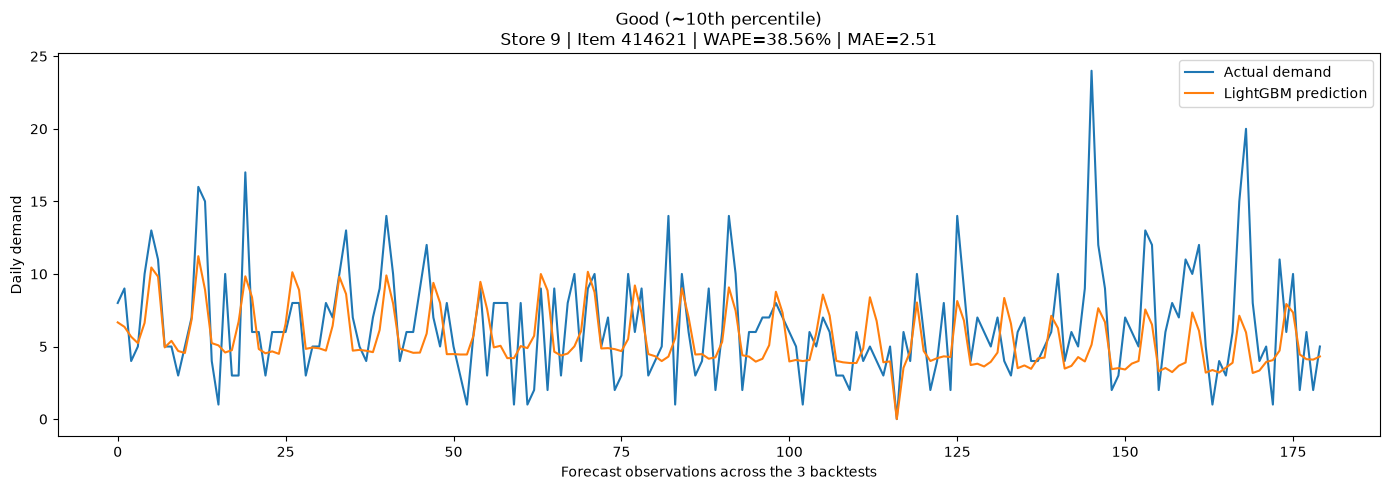

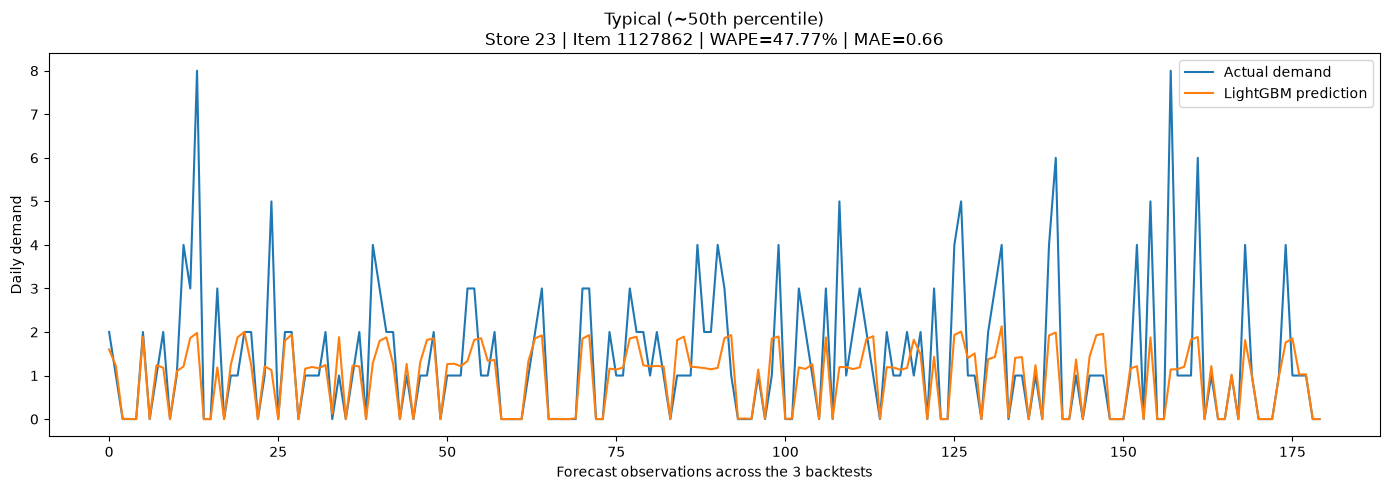

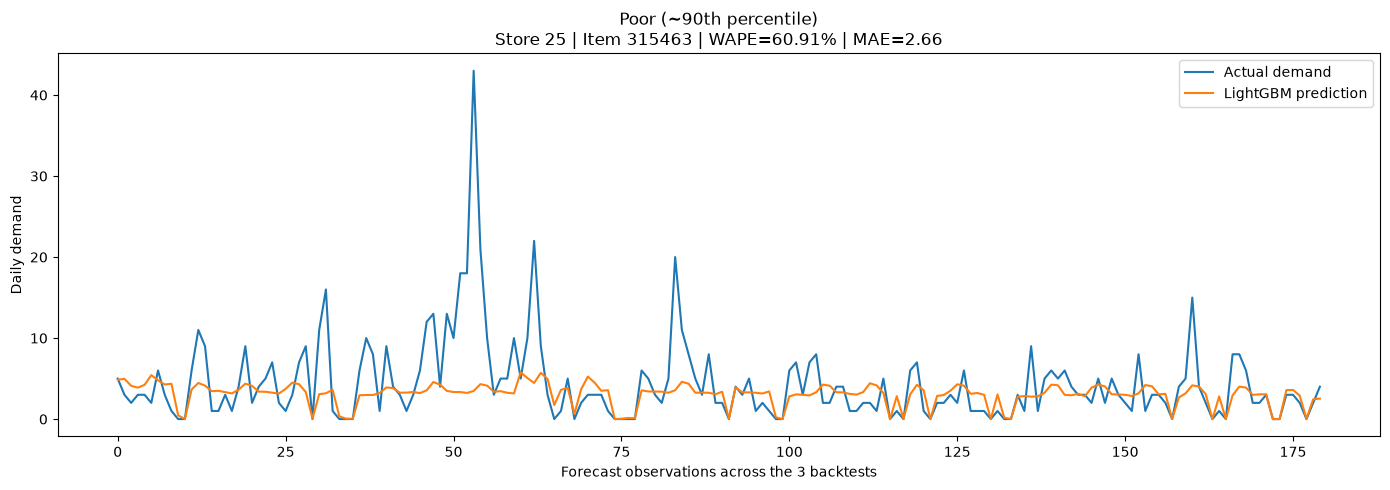


Selected series:
Good (~10th percentile): Store 9, Item 414621, WAPE=38.56%, MAE=2.51
Typical (~50th percentile): Store 23, Item 1127862, WAPE=47.77%, MAE=0.66
Poor (~90th percentile): Store 25, Item 315463, WAPE=60.91%, MAE=2.66


In [46]:
# ============================================================
# DIAGNOSTIC CHECK 3
# Visual sanity check: good / median / poor series
# ============================================================

# Sort all 300 series by WAPE.
ranked_series = (
    series_error
    .sort_values("WAPE")
    .reset_index(drop=True)
)

# Pick:
# - one good series around the 10th percentile
# - one typical series around the median
# - one poor series around the 90th percentile
positions = {
    "Good (~10th percentile)": int(len(ranked_series) * 0.10),
    "Typical (~50th percentile)": int(len(ranked_series) * 0.50),
    "Poor (~90th percentile)": int(len(ranked_series) * 0.90),
}

selected_series = {}

for label, position in positions.items():

    row = ranked_series.iloc[position]

    selected_series[label] = {
        "store_nbr": row["store_nbr"],
        "item_nbr": row["item_nbr"],
        "WAPE": row["WAPE"],
        "MAE": row["MAE"],
    }


# ------------------------------------------------------------
# Plot each selected series separately
# ------------------------------------------------------------

for label, info in selected_series.items():

    store = info["store_nbr"]
    item = info["item_nbr"]

    plot_data = diagnostic_eval[
        (diagnostic_eval["store_nbr"] == store)
        & (diagnostic_eval["item_nbr"] == item)
    ].copy()

    # Sort chronologically within each backtest.
    plot_data = plot_data.sort_values(
        ["backtest", "date"]
    )

    # Use a simple sequential x-axis so the three backtests
    # can be viewed together without confusing date gaps.
    plot_data = plot_data.reset_index(drop=True)

    plt.figure(figsize=(14, 5))

    plt.plot(
        plot_data.index,
        plot_data["demand_target"],
        label="Actual demand"
    )

    plt.plot(
        plot_data.index,
        plot_data["prediction"],
        label="LightGBM prediction"
    )

    plt.title(
        f"{label}\n"
        f"Store {store} | Item {item} | "
        f"WAPE={info['WAPE']:.2f}% | "
        f"MAE={info['MAE']:.2f}"
    )

    plt.xlabel(
        "Forecast observations across the 3 backtests"
    )

    plt.ylabel("Daily demand")

    plt.legend()

    plt.tight_layout()
    plt.show()


# ------------------------------------------------------------
# Print which series were selected
# ------------------------------------------------------------

print("\nSelected series:")

for label, info in selected_series.items():

    print(
        f"{label}: "
        f"Store {info['store_nbr']}, "
        f"Item {info['item_nbr']}, "
        f"WAPE={info['WAPE']:.2f}%, "
        f"MAE={info['MAE']:.2f}"
    )

In [47]:
# ============================================================
# NOTEBOOK 08 — FINAL CHECKPOINT
# ============================================================
#
# Final Optuna LightGBM benchmark:
#   Average 60-day MAE  ≈ 3.3441
#   Average 60-day WAPE ≈ 44.18%
#
# Diagnostic findings:
# 1. Recursive forecasting adds ~4 WAPE percentage points
#    compared with diagnostic one-step-ahead forecasting.
#
# 2. The model strongly smooths demand toward the middle:
#       High-demand days:
#           Actual ≈ 13.10
#           Prediction ≈ 7.19
#
#       Normal-demand days:
#           Actual ≈ 8.07
#           Prediction ≈ 8.09
#
#       Low-demand days:
#           Actual ≈ 3.94
#           Prediction ≈ 7.69
#
# 3. Higher volatility and greater intermittency are associated
#    with worse percentage forecast error.
#
# Decision:
# Notebook 09 will make the FINAL LightGBM improvement attempt:
#   A. Improve the multi-horizon forecasting strategy.
#   B. Address excessive smoothing / objective-target formulation.
#   C. Improve predictive demand features.
#   D. Combine successful changes.
#   E. Run Optuna ONCE on the improved architecture.
#   F. Run final frozen backtests and freeze LightGBM permanently.
#
# After Notebook 09:
#   -> Train/evaluate TFT.
#   -> Select final model winner.
# ============================================================

print("Notebook 08 complete.")
print("Next: 09_final_lightgbm_improvement.ipynb")

Notebook 08 complete.
Next: 09_final_lightgbm_improvement.ipynb
